# Exploratory Data Analysis of Large-Scale Retail Transaction Data
### Univariate, Bivariate and Multivariate Statistical Techniques

**NextHikes IT Solutions**

---

| # | Section |
|---|---------|
| 1 | Setup and loading |
| 2 | Data understanding |
| 3 | Preprocessing and cleaning (including feature engineering) |
| 4 | Univariate analysis: numerical variables |
| 5 | Univariate analysis: categorical variables |
| 6 | Outlier detection and capping |
| 7 | Bivariate analysis: numerical vs numerical (correlation) |
| 8 | Bivariate analysis: numerical vs categorical |
| 9 | Bivariate analysis: categorical vs categorical |
| 10 | Multivariate analysis |
| 11 | Extra analysis beyond the assignment (time, geography, products, discounts) |
| 12 | Key findings, recommendations and conclusion |
---

## 1. Setup and Loading

**Objective:** import the required libraries, configure plotting styles, and load the dataset.

### 1.1 Import libraries and configure the notebook

In [1]:
import os
import re
import string
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")

# ---- display and plot settings ----
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 12

# ---- project folders ----
DATA_DIR = "data"
FIG_DIR = os.path.join("outputs", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    """Save the current figure into outputs/figures/ (call before plt.show())."""
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")

print("Libraries loaded.")
print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

Libraries loaded.
pandas 3.0.6 | numpy 2.5.4 | seaborn 0.13.2


### 1.2 Load the dataset

**Objective:** read `Original_dataset.csv` into a DataFrame. We keep an untouched copy (`retail_data_raw`) and do all cleaning on a separate copy (`retail_data`).

In [2]:
DATA_PATH = os.path.join(DATA_DIR, "Original_dataset.csv")
retail_data_raw = pd.read_csv(DATA_PATH)
print(f"Rows: {retail_data_raw.shape[0]:,}  |  Columns: {retail_data_raw.shape[1]}")

Rows: 100,000  |  Columns: 18


### 1.3 First look at the data

**Objective:** inspect the first and last rows, the structure (`info`) and the overall statistics (`describe`).

In [3]:
print("First 5 rows")
display(retail_data_raw.head())
print("Last 5 rows")
display(retail_data_raw.tail())

First 5 rows


,customer_id,age,gender,city,state,customer_segment,order_id,order_date,product_category,product_subcategory,product_price,quantity,discount_percentage,final_price,payment_method,shipping_type,delivery_days,return_status
0,C10000,56,Male,Hyderabad,Telangana,New,O50000,2025-05-10,Health,Protein Powder,38658,3,7,"107,855.82",Debit Card,Standard,5,No
1,C10001,36,Male,Pune,Maharashtra,Premium,O50001,2023-11-27,Electronics,Smartphone,22462,4,20,"71,878.40",Cash on Delivery,Standard,4,Yes
2,C10002,20,Male,Kolkata,West Bengal,New,O50002,2025-02-08,Fashion,Women Dress,56601,2,27,"82,637.46",Credit Card,Standard,5,No
3,C10003,39,Female,Jaipur,Rajasthan,New,O50003,2024-04-19,Beauty,Perfume,26158,3,9,"71,411.34",UPI,Standard,3,No
4,C10004,20,Male,Chennai,Tamil Nadu,Premium,O50004,2024-10-08,Beauty,Shampoo,31240,1,6,"29,365.60",UPI,Standard,2,No


Last 5 rows


,customer_id,age,gender,city,state,customer_segment,order_id,order_date,product_category,product_subcategory,product_price,quantity,discount_percentage,final_price,payment_method,shipping_type,delivery_days,return_status
99995,C109995,29,Female,Pune,Maharashtra,Regular,O149995,2024-06-11,Health,Supplements,49293,1,11,"43,870.77",Debit Card,Standard,9,No
99996,C109996,28,Male,Mumbai,Maharashtra,Premium,O149996,2024-04-27,Fashion,Men T-Shirt,5722,2,22,"8,926.32",Cash on Delivery,Express,1,No
99997,C109997,44,Female,Jaipur,Rajasthan,Premium,O149997,2024-04-14,Grocery,Snacks,6311,4,11,"22,467.16",Cash on Delivery,Express,9,No
99998,C109998,45,Male,Jaipur,Rajasthan,Premium,O149998,2024-09-08,Beauty,Shampoo,46888,1,28,"33,759.36",Debit Card,Standard,1,No
99999,C109999,19,Male,Kolkata,West Bengal,New,O149999,2025-11-15,Health,Supplements,37361,3,3,"108,720.51",Credit Card,Standard,2,No


In [4]:
retail_data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   customer_id          100000 non-null  str    
 1   age                  100000 non-null  int64  
 2   gender               100000 non-null  str    
 3   city                 100000 non-null  str    
 4   state                100000 non-null  str    
 5   customer_segment     100000 non-null  str    
 6   order_id             100000 non-null  str    
 7   order_date           100000 non-null  str    
 8   product_category     100000 non-null  str    
 9   product_subcategory  100000 non-null  str    
 10  product_price        100000 non-null  int64  
 11  quantity             100000 non-null  int64  
 12  discount_percentage  100000 non-null  int64  
 13  final_price          100000 non-null  float64
 14  payment_method       100000 non-null  str    
 15  shipping_type        100000 n

In [5]:
retail_data_raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,100000,100000,C10000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,"100,000.00",NaN,NaN,NaN,41.56,13.85,18.00,30.00,42.00,54.00,65.00
gender,100000,2,Male,50111,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,100000,10,Hyderabad,10150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,100000,9,Maharashtra,19952,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_segment,100000,3,New,33488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,100000,100000,O50000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,100000,1095,2023-04-12,124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,100000,6,Health,16858,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_subcategory,100000,21,Protein Powder,5668,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Interpretation**

- The dataset has **100,000 rows and 18 columns** (about 13.7 MB). `info()` shows every column has 100,000 non-null values, so there are no missing cells at first glance.
- There are 12 text columns, 5 whole-number columns and 1 decimal column (`final_price`). `order_date` is stored as text and will need converting to a date type in section 3.
- `customer_id` and `order_id` each have 100,000 unique values, so every row is a different customer and a different order.
- First impressions from `describe()`:
  - `age` runs from 18 to 65 (mean 41.6), `quantity` from 1 to 4, `discount_percentage` from 0 to 30 (mean 15.0) and `delivery_days` from 1 to 10 (mean 5.5).
  - `product_price` runs from 500 to 59,998 with the mean (30,165) almost equal to the median (30,148).
  - `final_price` behaves differently: its mean (64,166) is well above its median (49,752) and its maximum is 239,980. This hints at a right-skewed distribution that we examine in section 4.
- The orders cover 1,095 different dates.

## 2. Data Understanding

**Objective:** understand what each column represents, classify the columns (ID / numerical / categorical / date), and check the value range of each one.

### 2.1 Data dictionary

In [6]:
roles = {
    "customer_id": "ID", "age": "Numerical", "gender": "Categorical", "city": "Categorical",
    "state": "Categorical", "customer_segment": "Categorical", "order_id": "ID",
    "order_date": "Date", "product_category": "Categorical", "product_subcategory": "Categorical",
    "product_price": "Numerical", "quantity": "Numerical", "discount_percentage": "Numerical",
    "final_price": "Numerical", "payment_method": "Categorical", "shipping_type": "Categorical",
    "delivery_days": "Numerical", "return_status": "Categorical",
}
descriptions = {
    "customer_id": "Unique customer identifier",
    "age": "Customer age in years",
    "gender": "Customer gender",
    "city": "City of the customer",
    "state": "State of the customer",
    "customer_segment": "Customer tier (New / Regular / Premium)",
    "order_id": "Unique order identifier",
    "order_date": "Date the order was placed",
    "product_category": "Top-level product category",
    "product_subcategory": "Specific product type within the category",
    "product_price": "Unit price of the product (currency not stated in the data)",
    "quantity": "Number of units ordered",
    "discount_percentage": "Discount given on the order (%)",
    "final_price": "Final amount of the order after discount (verified in section 3.6)",
    "payment_method": "How the customer paid",
    "shipping_type": "Shipping speed option chosen",
    "delivery_days": "Days taken to deliver the order",
    "return_status": "Whether the order was returned (Yes / No)",
}

def value_range(s, role):
    if role == "Numerical":
        return f"{s.min():,} to {s.max():,}"
    if role == "Date":
        return f"{s.min()} to {s.max()}"
    if role == "ID":
        return f"{s.iloc[0]} ... {s.iloc[-1]}"
    if s.nunique() <= 10:
        return ", ".join(sorted(s.unique()))
    return f"{s.nunique()} categories, e.g. " + ", ".join(sorted(s.unique())[:3]) + " ..."

data_dict = pd.DataFrame({
    "role": pd.Series(roles),
    "dtype": retail_data_raw.dtypes.astype(str),
    "unique_values": retail_data_raw.nunique(),
    "value range / categories": {c: value_range(retail_data_raw[c], roles[c]) for c in retail_data_raw.columns},
    "description": pd.Series(descriptions),
}).loc[retail_data_raw.columns]
data_dict.index.name = "column"
data_dict

,role,dtype,unique_values,value range / categories,description
column,,,,,
customer_id,ID,str,100000,C10000 ... C109999,Unique customer identifier
age,Numerical,int64,48,18 to 65,Customer age in years
gender,Categorical,str,2,"Female, Male",Customer gender
city,Categorical,str,10,"Ahmedabad, Bangalore, Chennai, Delhi, Hyderabad, Jaipur, Kolkata, Mumbai, Noida, Pune",City of the customer
state,Categorical,str,9,"Delhi, Gujarat, Karnataka, Maharashtra, Rajasthan, Tamil Nadu, Telangana, Uttar Prades...",State of the customer
customer_segment,Categorical,str,3,"New, Premium, Regular",Customer tier (New / Regular / Premium)
order_id,ID,str,100000,O50000 ... O149999,Unique order identifier
order_date,Date,str,1095,2023-01-01 to 2025-12-30,Date the order was placed
product_category,Categorical,str,6,"Beauty, Electronics, Fashion, Grocery, Health, Home & Kitchen",Top-level product category


### 2.2 Group the columns by type

**Objective:** create column lists that we reuse in every later section.

In [7]:
id_cols   = ["customer_id", "order_id"]
date_cols = ["order_date"]
num_cols  = ["age", "product_price", "quantity", "discount_percentage", "final_price", "delivery_days"]
cat_cols  = ["gender", "city", "state", "customer_segment", "product_category",
             "product_subcategory", "payment_method", "shipping_type", "return_status"]

print(f"ID columns          ({len(id_cols)}): {id_cols}")
print(f"Date columns        ({len(date_cols)}): {date_cols}")
print(f"Numerical columns   ({len(num_cols)}): {num_cols}")
print(f"Categorical columns ({len(cat_cols)}): {cat_cols}")
print("Total:", len(id_cols) + len(date_cols) + len(num_cols) + len(cat_cols))

ID columns          (2): ['customer_id', 'order_id']
Date columns        (1): ['order_date']
Numerical columns   (6): ['age', 'product_price', 'quantity', 'discount_percentage', 'final_price', 'delivery_days']
Categorical columns (9): ['gender', 'city', 'state', 'customer_segment', 'product_category', 'product_subcategory', 'payment_method', 'shipping_type', 'return_status']
Total: 18


**Interpretation**

- The 18 columns split into **2 ID columns, 1 date column, 6 numerical columns and 9 categorical columns**. The ID columns only label rows, so they are excluded from statistical analysis.
- `quantity` (4 values), `delivery_days` (10 values) and `discount_percentage` (31 values) are numbers, but they take only a few whole-number values, so they behave partly like categories. We keep them numeric but also check their frequency tables.
- Because `customer_id` is unique in every row, **each customer placed exactly one order**. This means we cannot study repeat purchases or customer lifetime value with this data.
- All value ranges are plausible: adults only (18 to 65), discounts between 0 and 30%, 21 subcategories nested inside 6 categories, and 10 cities spread over 9 states.

## 3. Data Preprocessing and Cleaning

**Objective:** make sure the data is trustworthy before analysis: tidy column names, remove stray spaces/special characters, check missing values and duplicates, fix data types, verify the logic of the data, and create helpful new features.

### 3.1 Column names: spaces, special characters, duplicates

**Objective:** check that every column name is clean and consistent, then standardise the names on the working copy `retail_data`.

In [8]:
cols = retail_data_raw.columns.tolist()
audit = pd.DataFrame({
    "leading/trailing space": [c != c.strip() for c in cols],
    "special characters":     [bool(re.search(r"[^0-9a-zA-Z_]", c)) for c in cols],
    "uppercase letters":      [c != c.lower() for c in cols],
    "contains space":         [" " in c for c in cols],
}, index=cols)

print("Columns flagged per check:")
print(audit.sum().to_string())
print("\nDuplicate column names:", int(retail_data_raw.columns.duplicated().sum()))

# Standardise names on the working copy (strip, lowercase, replace odd characters with underscores)
retail_data = retail_data_raw.copy()
retail_data.columns = (retail_data.columns.str.strip().str.lower()
              .str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_"))
print("\nColumn names changed by standardisation:", int((retail_data.columns != retail_data_raw.columns).sum()))
print(retail_data.columns.tolist())

Columns flagged per check:
leading/trailing space    0
special characters        0
uppercase letters         0
contains space            0

Duplicate column names: 0

Column names changed by standardisation: 0
['customer_id', 'age', 'gender', 'city', 'state', 'customer_segment', 'order_id', 'order_date', 'product_category', 'product_subcategory', 'product_price', 'quantity', 'discount_percentage', 'final_price', 'payment_method', 'shipping_type', 'delivery_days', 'return_status']


**Interpretation**

All 18 column names are already clean: no leading or trailing spaces, no special characters, no spaces inside names, no uppercase letters and no duplicates. The standardisation step changed 0 names, so nothing needed fixing. The check is still worth keeping, because column-name problems break code silently in many real datasets.

### 3.2 Text values: extra spaces, special characters, casing variants

**Objective:** check every text column for leading/trailing/double spaces, unusual characters and inconsistent spellings or casing (e.g. "mumbai" vs "Mumbai"), then strip whitespace.

In [9]:
text_cols = retail_data.select_dtypes(exclude=["number", "datetime"]).columns.tolist()
allowed = set(string.ascii_letters + string.digits + " ")

rows = []
for c in text_cols:
    s = retail_data[c]
    rows.append({
        "column": c,
        "extra spaces (lead/trail)": int((s != s.str.strip()).sum()),
        "double spaces": int(s.str.contains(r"\s{2,}", regex=True).sum()),
        "unique (raw)": s.nunique(),
        "unique (after strip + lowercase)": s.str.strip().str.lower().nunique(),
        "non-alphanumeric characters used": "".join(sorted(set("".join(s.unique())) - allowed)) or "none",
    })
text_audit = pd.DataFrame(rows).set_index("column")
display(text_audit)

# Strip whitespace from all text columns (casing is already consistent, so it is left unchanged)
for c in text_cols:
    retail_data[c] = retail_data[c].str.strip()
print("Whitespace stripped from", len(text_cols), "text columns.")

,extra spaces (lead/trail),double spaces,unique (raw),unique (after strip + lowercase),non-alphanumeric characters used
column,,,,,
customer_id,0,0,100000,100000,none
gender,0,0,2,2,none
city,0,0,10,10,none
state,0,0,9,9,none
customer_segment,0,0,3,3,none
order_id,0,0,100000,100000,none
order_date,0,0,1095,1095,-
product_category,0,0,6,6,&
product_subcategory,0,0,21,21,-


Whitespace stripped from 12 text columns.


**Interpretation**

- No text value has extra leading, trailing or double spaces.
- The number of unique values is identical before and after lowercasing and stripping in every column, so there are no spelling or casing variants such as "mumbai" vs "Mumbai".
- The only non-alphanumeric characters are genuine parts of names: the dash in dates and in "Men T-Shirt", and the ampersand in "Home & Kitchen". These are correct and are kept.
- Whitespace stripping was applied as a safeguard but changed nothing.

### 3.3 Missing values

**Objective:** count missing values per column and also look for hidden placeholders such as "NA", "null", "?" or blank strings.

In [10]:
missing = pd.DataFrame({
    "missing_count": retail_data.isnull().sum(),
    "missing_%": retail_data.isnull().mean() * 100,
})
placeholders = {"", "na", "n/a", "null", "none", "nan", "?", "-", "unknown"}
missing["placeholder_strings"] = [
    int(retail_data[c].astype(str).str.strip().str.lower().isin(placeholders).sum()) for c in retail_data.columns
]
display(missing)
print("Total missing cells:", int(retail_data.isnull().sum().sum()))
print("Total placeholder-like cells:", int(missing["placeholder_strings"].sum()))

,missing_count,missing_%,placeholder_strings
customer_id,0,0.00,0
age,0,0.00,0
gender,0,0.00,0
city,0,0.00,0
state,0,0.00,0
customer_segment,0,0.00,0
order_id,0,0.00,0
order_date,0,0.00,0
product_category,0,0.00,0
product_subcategory,0,0.00,0


Total missing cells: 0
Total placeholder-like cells: 0


**Interpretation**

There are **no missing values** in any of the 18 columns (0 out of 1.8 million cells), and no hidden placeholders such as "NA", "null", "?" or blank text. No imputation or row removal is needed, so all 100,000 rows continue to the analysis.

### 3.4 Duplicates

**Objective:** check for fully duplicated rows and for repeated `order_id` / `customer_id` values (each order should be unique).

In [11]:
print("Fully duplicated rows              :", int(retail_data.duplicated().sum()))
print("Duplicate order_id values          :", int(retail_data["order_id"].duplicated().sum()))
print("Duplicate customer_id values       :", int(retail_data["customer_id"].duplicated().sum()))
print("Duplicate rows ignoring both IDs   :", int(retail_data.drop(columns=id_cols).duplicated().sum()))

n_before = len(retail_data)
retail_data = retail_data.drop_duplicates().reset_index(drop=True)
print(f"\nRows before: {n_before:,} | rows after dropping duplicates: {len(retail_data):,}")

Fully duplicated rows              : 0
Duplicate order_id values          : 0
Duplicate customer_id values       : 0
Duplicate rows ignoring both IDs   : 0

Rows before: 100,000 | rows after dropping duplicates: 100,000


**Interpretation**

There are no fully duplicated rows, no repeated `order_id`, no repeated `customer_id`, and no rows that match when the IDs are ignored. No rows were dropped (100,000 before and after). Every row is a distinct order from a distinct customer.

### 3.5 Data types and the date column

**Objective:** convert `order_date` from text to a proper datetime type and confirm every column has the right type.

In [12]:
retail_data["order_date"] = pd.to_datetime(retail_data["order_date"], errors="coerce")

print("Unparseable dates:", int(retail_data["order_date"].isna().sum()))
print("First order:", retail_data["order_date"].min().date(), "| Last order:", retail_data["order_date"].max().date())
print("Span:", (retail_data["order_date"].max() - retail_data["order_date"].min()).days, "days")
print("\nOrders per year:")
print(retail_data["order_date"].dt.year.value_counts().sort_index().to_string())
print()
retail_data.dtypes.astype(str).to_frame("dtype").T

Unparseable dates: 0
First order: 2023-01-01 | Last order: 2025-12-30
Span: 1094 days

Orders per year:
order_date
2023    33513
2024    33547
2025    32940



,customer_id,age,gender,city,state,customer_segment,order_id,order_date,product_category,product_subcategory,product_price,quantity,discount_percentage,final_price,payment_method,shipping_type,delivery_days,return_status
dtype,str,int64,str,str,str,str,str,datetime64[us],str,str,int64,int64,int64,float64,str,str,int64,str


**Interpretation**

- `order_date` converted successfully to a datetime type, with 0 unparseable dates.
- The data covers **2023-01-01 to 2025-12-30**, almost exactly three years (1,094 days), with a similar number of orders each year (33,513 in 2023, 33,547 in 2024 and 32,940 in 2025).
- All other columns already have the right type: whole numbers for age, price, quantity, discount and delivery days, a decimal for `final_price`, and text for the categories.

### 3.6 Integrity and logic checks

**Objective:** verify the data makes logical sense: values in sensible ranges, `final_price` equal to price × quantity × (1 − discount), each city in one state, and each subcategory in one category.

In [13]:
recomputed = (retail_data["product_price"] * retail_data["quantity"] * (1 - retail_data["discount_percentage"] / 100)).round(2)
price_diff = (recomputed - retail_data["final_price"]).abs()

checks = {
    "age below 18 or above 100":                      ((retail_data["age"] < 18) | (retail_data["age"] > 100)).sum(),
    "product_price <= 0":                              (retail_data["product_price"] <= 0).sum(),
    "quantity < 1":                                    (retail_data["quantity"] < 1).sum(),
    "discount_percentage outside 0-100":               ((retail_data["discount_percentage"] < 0) | (retail_data["discount_percentage"] > 100)).sum(),
    "delivery_days < 1":                               (retail_data["delivery_days"] < 1).sum(),
    "final_price <= 0":                                (retail_data["final_price"] <= 0).sum(),
    "final_price > price x quantity (gross)":          (retail_data["final_price"] > retail_data["product_price"] * retail_data["quantity"] + 0.01).sum(),
    "final_price differs from recomputed (> 0.01)":    (price_diff > 0.01).sum(),
    "return_status not in {Yes, No}":                  (~retail_data["return_status"].isin(["Yes", "No"])).sum(),
    "order_date in the future":                        (retail_data["order_date"] > pd.Timestamp.today()).sum(),
}
integrity = pd.DataFrame({"rule violations": pd.Series(checks).astype(int)})
integrity["status"] = np.where(integrity["rule violations"] == 0, "PASS", "CHECK")
display(integrity)
print("Largest difference between stored and recomputed final_price:", round(price_diff.max(), 4))

# Mapping consistency
city_state = retail_data.groupby("city")["state"].nunique()
sub_cat = retail_data.groupby("product_subcategory")["product_category"].nunique()
print("\nCities that map to more than one state      :", int((city_state > 1).sum()))
print("Subcategories that map to more than one category:", int((sub_cat > 1).sum()))

print("\nCities per state:")
print(retail_data.groupby("state")["city"].unique().apply(lambda x: ", ".join(sorted(x))).to_string())
print("\nSubcategories per category:")
print(retail_data.groupby("product_category")["product_subcategory"].unique().apply(lambda x: ", ".join(sorted(x))).to_string())

,rule violations,status
age below 18 or above 100,0,PASS
product_price <= 0,0,PASS
quantity < 1,0,PASS
discount_percentage outside 0-100,0,PASS
delivery_days < 1,0,PASS
final_price <= 0,0,PASS
final_price > price x quantity (gross),0,PASS
final_price differs from recomputed (> 0.01),0,PASS
"return_status not in {Yes, No}",0,PASS
order_date in the future,0,PASS


Largest difference between stored and recomputed final_price: 0.0

Cities that map to more than one state      : 0
Subcategories that map to more than one category: 0

Cities per state:
state
Delhi                   Delhi
Gujarat             Ahmedabad
Karnataka           Bangalore
Maharashtra      Mumbai, Pune
Rajasthan              Jaipur
Tamil Nadu            Chennai
Telangana           Hyderabad
Uttar Pradesh           Noida
West Bengal           Kolkata

Subcategories per category:
product_category
Beauty                            Face Cream, Perfume, Shampoo
Electronics             Headphones, Laptop, Smartphone, Tablet
Fashion                 Jeans, Men T-Shirt, Shoes, Women Dress
Grocery                           Organic Rice, Pulses, Snacks
Health                   Protein Powder, Supplements, Vitamins
Home & Kitchen    Blender, Cookware, Microwave, Vacuum Cleaner


**Interpretation**

- **All 10 range and logic checks pass** with zero violations: ages are adult, prices and quantities are positive, discounts are within 0 to 100, delivery days are at least 1, no `final_price` exceeds the gross amount, return status is only Yes or No, and no dates are in the future.
- **`final_price` equals `product_price × quantity × (1 − discount/100)` for every row** (largest difference 0.0). This is an important finding: `final_price` is a *calculated* value, not an independent measurement. Later correlations between `final_price` and its three ingredients are therefore partly arithmetic, not behaviour.
- Every city belongs to exactly one state, and every subcategory belongs to exactly one category. Maharashtra contains two cities (Mumbai and Pune), so it will naturally show about twice the orders of other states.

### 3.7 Feature engineering

**Objective:** create new columns that make deeper analysis possible: date parts, gross amount, discount amount, revenue per unit, a 0/1 return flag, and bins for age, discount and delivery speed.

In [14]:
month_order   = ["January", "February", "March", "April", "May", "June", "July",
                 "August", "September", "October", "November", "December"]
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Date features
retail_data["order_year"]       = retail_data["order_date"].dt.year
retail_data["order_quarter"]    = retail_data["order_date"].dt.quarter
retail_data["order_month"]      = retail_data["order_date"].dt.month
retail_data["order_month_name"] = retail_data["order_date"].dt.month_name()
retail_data["order_weekday"]    = retail_data["order_date"].dt.day_name()
retail_data["year_month"]       = retail_data["order_date"].dt.to_period("M").astype(str)

# Money features
retail_data["gross_amount"]     = retail_data["product_price"] * retail_data["quantity"]          # before discount
retail_data["discount_amount"]  = retail_data["gross_amount"] - retail_data["final_price"]        # money given away
retail_data["revenue_per_unit"] = retail_data["final_price"] / retail_data["quantity"]

# Target-style flag
retail_data["is_return"] = (retail_data["return_status"] == "Yes").astype(int)

# Bins
retail_data["age_group"] = pd.cut(retail_data["age"], bins=[17, 25, 35, 45, 55, 65],
                         labels=["18-25", "26-35", "36-45", "46-55", "56-65"])
retail_data["discount_band"] = pd.cut(retail_data["discount_percentage"], bins=[-1, 5, 10, 15, 20, 25, 30],
                             labels=["0-5%", "6-10%", "11-15%", "16-20%", "21-25%", "26-30%"])
retail_data["delivery_speed"] = pd.cut(retail_data["delivery_days"], bins=[0, 3, 6, 10],
                              labels=["Fast (1-3 days)", "Medium (4-6 days)", "Slow (7-10 days)"])

new_cols = ["order_year", "order_quarter", "order_month", "order_weekday", "gross_amount",
            "discount_amount", "revenue_per_unit", "is_return", "age_group", "discount_band", "delivery_speed"]
print("Rows with unassigned bins (should all be 0):",
      {c: int(retail_data[c].isna().sum()) for c in ["age_group", "discount_band", "delivery_speed"]})
print("Dataset shape after feature engineering:", retail_data.shape)
retail_data[["order_date", "age", "discount_percentage", "delivery_days"] + new_cols].head()

Rows with unassigned bins (should all be 0): {'age_group': 0, 'discount_band': 0, 'delivery_speed': 0}
Dataset shape after feature engineering: (100000, 31)


,order_date,age,discount_percentage,delivery_days,order_year,order_quarter,order_month,order_weekday,gross_amount,discount_amount,revenue_per_unit,is_return,age_group,discount_band,delivery_speed
0,2025-05-10,56,7,5,2025,2,5,Saturday,115974,"8,118.18","35,951.94",0,56-65,6-10%,Medium (4-6 days)
1,2023-11-27,36,20,4,2023,4,11,Monday,89848,"17,969.60","17,969.60",1,36-45,16-20%,Medium (4-6 days)
2,2025-02-08,20,27,5,2025,1,2,Saturday,113202,"30,564.54","41,318.73",0,18-25,26-30%,Medium (4-6 days)
3,2024-04-19,39,9,3,2024,2,4,Friday,78474,"7,062.66","23,803.78",0,36-45,6-10%,Fast (1-3 days)
4,2024-10-08,20,6,2,2024,4,10,Tuesday,31240,"1,874.40","29,365.60",0,18-25,6-10%,Fast (1-3 days)


**Interpretation**

- 13 new columns were added (date parts, `gross_amount`, `discount_amount`, `revenue_per_unit`, `is_return`, and the three bin columns), taking the working data from 18 to 31 columns. Two more (`is_final_price_outlier` and `final_price_capped`) are added in section 6.
- Every row received a valid age group, discount band and delivery-speed band (0 unassigned), so the bins are complete.
- Note that the discount band **0-5% contains six whole-number discount values (0, 1, 2, 3, 4, 5)** while the other bands contain five. This makes the first band larger in order count, so later comparisons across bands use averages rather than totals.

## 4. Univariate Analysis: Numerical Variables

**Objective:** study each numerical variable on its own: centre (mean, median), spread (std, IQR), shape (skewness, kurtosis) and distribution plots.

*How to read the shape numbers:* skewness near 0 means symmetric, positive means a long right tail. Excess kurtosis near 0 means a bell-like tail weight, strongly negative means a flat distribution, and strongly positive means heavy tails with extreme values.

### 4.1 Summary statistics

In [15]:
def skew_label(x):
    side = "right" if x > 0 else "left"
    if abs(x) < 0.5:
        return "approximately symmetric"
    return f"{'moderately' if abs(x) < 1 else 'highly'} {side}-skewed"

def kurt_label(x):
    if x < -1:
        return "flat (platykurtic)"
    if x > 1:
        return "heavy-tailed (leptokurtic)"
    return "normal-like (mesokurtic)"

def num_summary(data, cols):
    d = data[cols]
    s = pd.DataFrame({
        "count": d.count(), "mean": d.mean(), "median": d.median(), "std": d.std(),
        "min": d.min(), "Q1": d.quantile(0.25), "Q3": d.quantile(0.75), "max": d.max(),
    })
    s["IQR"] = s["Q3"] - s["Q1"]
    s["skewness"] = d.skew()
    s["kurtosis (excess)"] = d.kurt()
    s["CV %"] = s["std"] / s["mean"] * 100
    s["skew shape"] = s["skewness"].apply(skew_label)
    s["tail shape"] = s["kurtosis (excess)"].apply(kurt_label)
    return s

summary_stats = num_summary(retail_data, num_cols)
summary_stats

,count,mean,median,std,min,Q1,Q3,max,IQR,skewness,kurtosis (excess),CV %,skew shape,tail shape
age,100000,41.56,42.00,13.85,18.00,30.00,54.00,65.00,24.00,-0.00,-1.20,33.33,approximately symmetric,flat (platykurtic)
product_price,100000,"30,164.53","30,148.00","17,139.68",500.00,"15,375.00","44,957.00","59,998.00","29,582.00",0.00,-1.20,56.82,approximately symmetric,flat (platykurtic)
quantity,100000,2.50,3.00,1.12,1.00,1.00,4.00,4.00,3.00,-0.00,-1.36,44.77,approximately symmetric,flat (platykurtic)
discount_percentage,100000,15.01,15.00,8.95,0.00,7.00,23.00,30.00,16.00,-0.00,-1.20,59.65,approximately symmetric,flat (platykurtic)
final_price,100000,"64,165.72","49,752.39","49,969.28",357.00,"24,705.00","94,046.07","239,980.00","69,341.07",0.93,0.17,77.88,moderately right-skewed,normal-like (mesokurtic)
delivery_days,100000,5.51,5.00,2.87,1.00,3.00,8.00,10.00,5.00,0.00,-1.22,52.18,approximately symmetric,flat (platykurtic)


### 4.2 Frequency of the discrete numerical variables

**Objective:** `quantity` (4 values) and `delivery_days` (10 values) behave like categories, so we look at the share of each value.

In [16]:
discrete_share = pd.concat(
    {c: retail_data[c].value_counts(normalize=True).sort_index() * 100 for c in ["quantity", "delivery_days"]}, axis=1
)
discrete_share.columns = ["quantity (% of orders)", "delivery_days (% of orders)"]
discrete_share.index.name = "value"
discrete_share

,quantity (% of orders),delivery_days (% of orders)
value,,
1,25.08,9.94
2,24.81,9.99
3,24.97,9.93
4,25.15,10.02
5,NaN,10.20
6,NaN,10.02
7,NaN,9.92
8,NaN,9.77
9,NaN,10.06


### 4.3 Histograms with KDE (mean and median marked)

**Objective:** see the full shape of each distribution. Each variable has its own colour. The black dashed line is the mean and the red dotted line is the median.

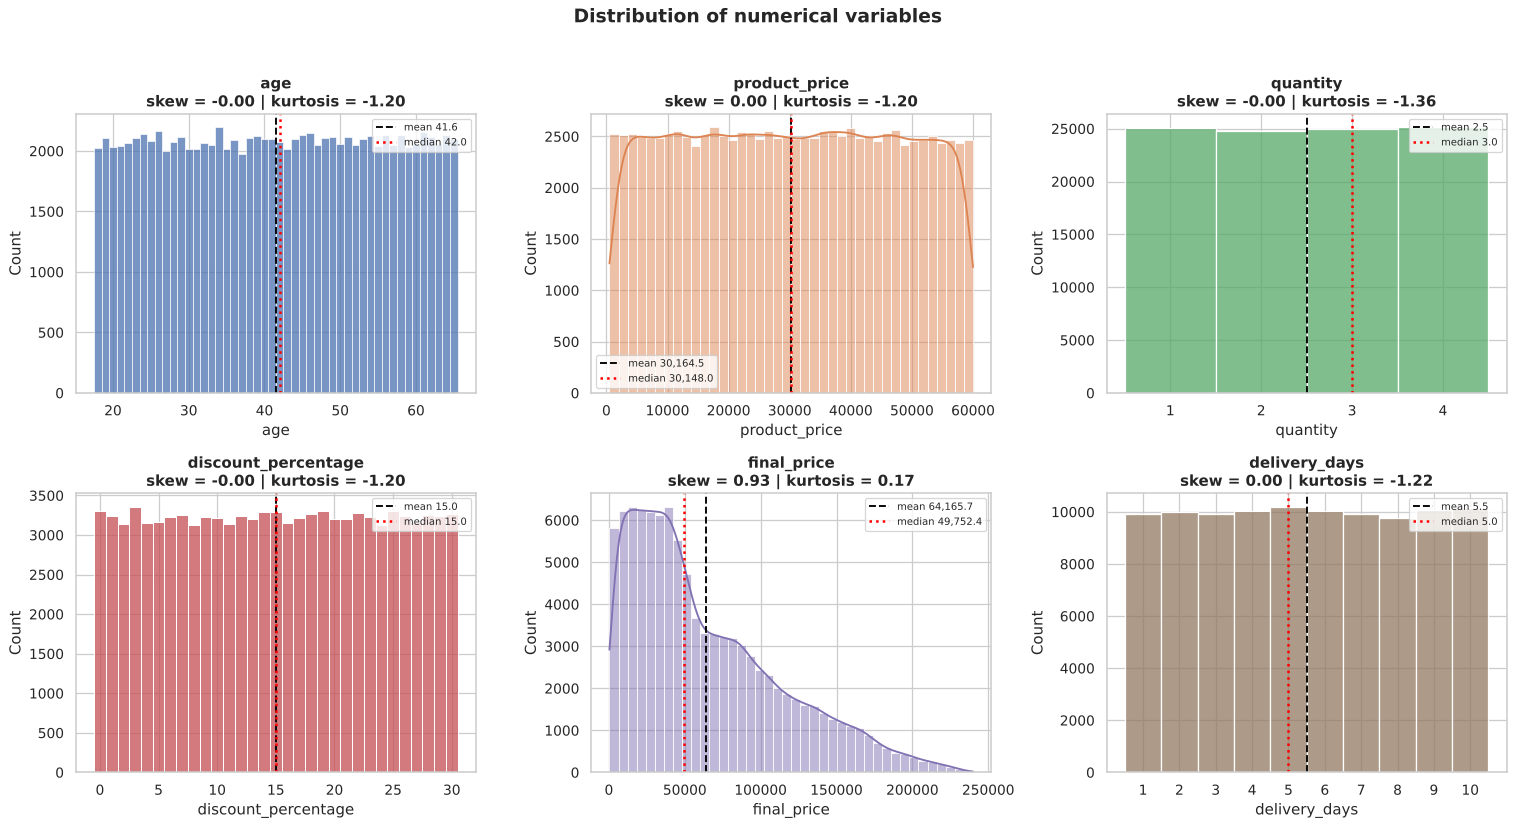

In [17]:
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860"]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col, color in zip(axes.ravel(), num_cols, colors):
    discrete = retail_data[col].nunique() <= 60
    if discrete:
        sns.histplot(retail_data[col], ax=ax, color=color, discrete=True, edgecolor="white")
        if retail_data[col].nunique() <= 12:
            ax.set_xticks(sorted(retail_data[col].unique()))
    else:
        sns.histplot(retail_data[col], ax=ax, color=color, bins=40, kde=True, edgecolor="white")
    ax.axvline(retail_data[col].mean(), color="black", ls="--", lw=1.5, label=f"mean {retail_data[col].mean():,.1f}")
    ax.axvline(retail_data[col].median(), color="red", ls=":", lw=2, label=f"median {retail_data[col].median():,.1f}")
    ax.set_title(f"{col}\nskew = {retail_data[col].skew():.2f} | kurtosis = {retail_data[col].kurt():.2f}")
    ax.legend(fontsize=8)
fig.suptitle("Distribution of numerical variables", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
save_fig("04_histograms_numeric")
plt.show()

### 4.4 Boxplots

**Objective:** look at the median, quartiles and any points beyond the whiskers for every numerical variable.

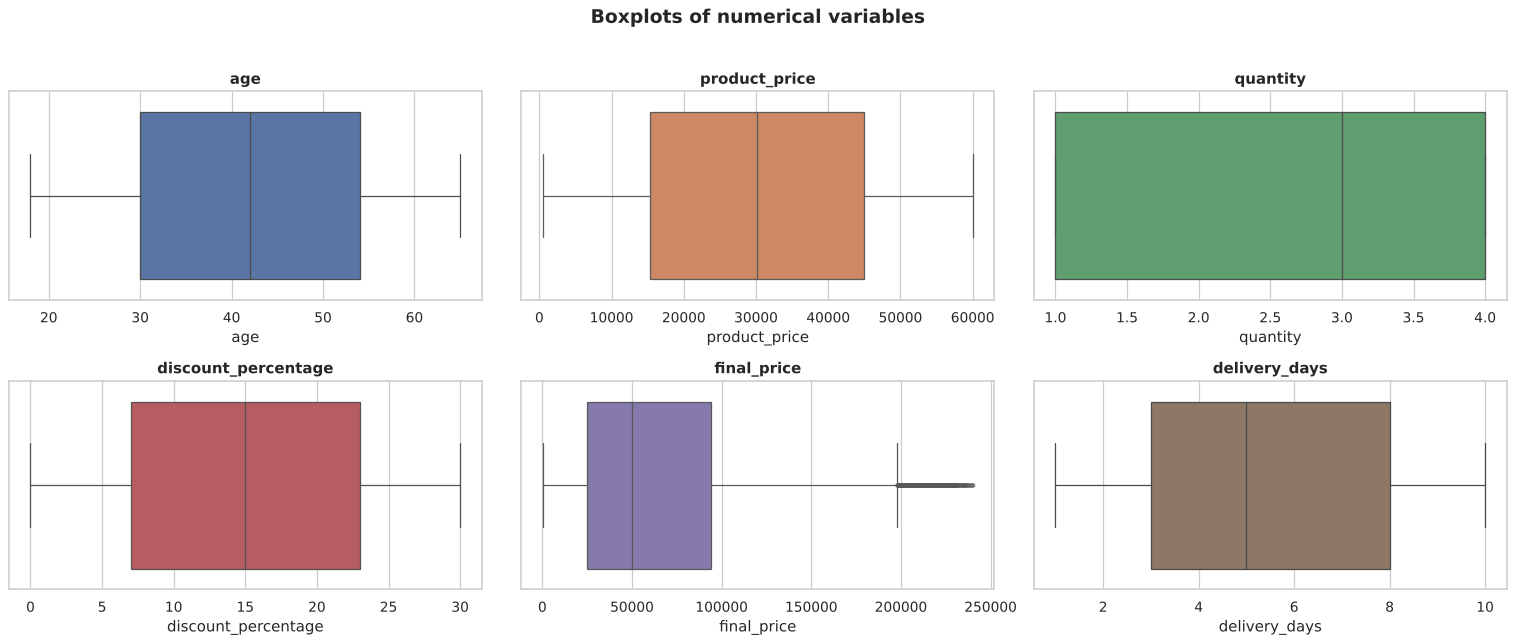

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(17, 7))
for ax, col, color in zip(axes.ravel(), num_cols, colors):
    sns.boxplot(x=retail_data[col], ax=ax, color=color, flierprops=dict(marker="o", markersize=2.5, alpha=0.35))
    ax.set_title(col)
fig.suptitle("Boxplots of numerical variables", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
save_fig("04_boxplots_numeric")
plt.show()

### 4.5 Looking closer at `final_price`: raw vs log scale and a Q-Q plot

**Objective:** `final_price` is the key money variable, so we check whether a log transform makes it more symmetric, and compare it to a normal distribution with a Q-Q plot.

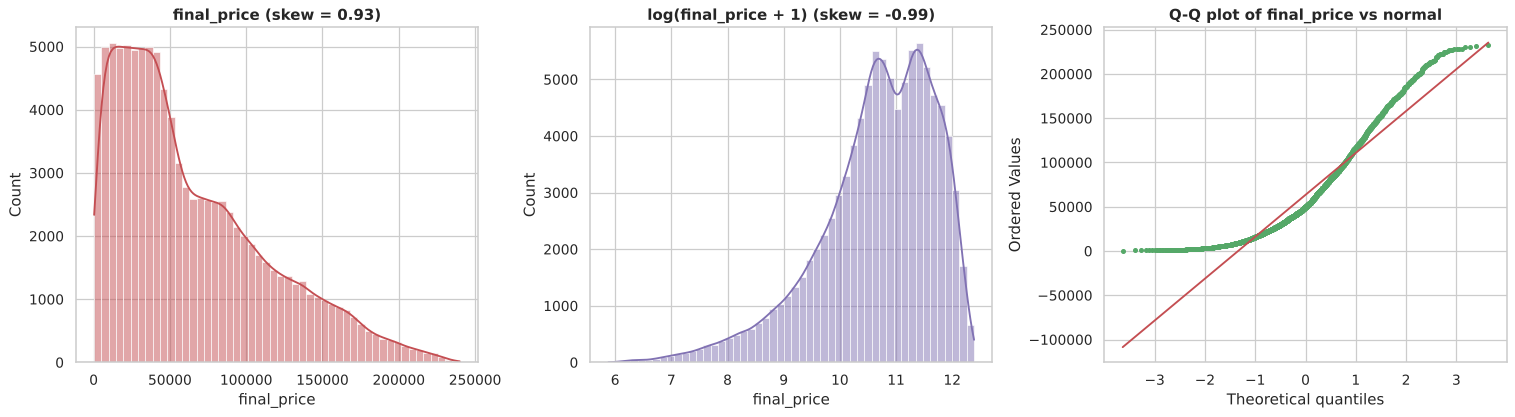

final_price skewness: 0.935 -> after log transform: -0.986
final_price kurtosis: 0.169 -> after log transform: 1.031


In [19]:
fp = retail_data["final_price"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.histplot(fp, bins=50, kde=True, color="#C44E52", ax=axes[0])
axes[0].set_title(f"final_price (skew = {fp.skew():.2f})")

sns.histplot(np.log1p(fp), bins=50, kde=True, color="#8172B3", ax=axes[1])
axes[1].set_title(f"log(final_price + 1) (skew = {np.log1p(fp).skew():.2f})")

stats.probplot(fp.sample(5000, random_state=42), dist="norm", plot=axes[2])
axes[2].get_lines()[0].set_color("#55A868")
axes[2].get_lines()[0].set_markersize(3)
axes[2].set_title("Q-Q plot of final_price vs normal")
plt.tight_layout()
save_fig("04_final_price_log_qq")
plt.show()

print(f"final_price skewness: {fp.skew():.3f} -> after log transform: {np.log1p(fp).skew():.3f}")
print(f"final_price kurtosis: {fp.kurt():.3f} -> after log transform: {np.log1p(fp).kurt():.3f}")

**Interpretation**

- **Five of the six numerical variables are uniformly distributed.** `age`, `product_price`, `quantity`, `discount_percentage` and `delivery_days` all have skewness of about 0 and mean ≈ median. Their excess kurtosis is about −1.2 (−1.36 for the 4-value `quantity`), which is exactly the value expected for a flat, uniform distribution. In plain terms: every age from 18 to 65, every price from 500 to 60,000, every discount from 0 to 30% and every delivery time from 1 to 10 days is about equally common. Each of the four quantities accounts for about 25% of orders and each delivery-day value for about 10%.
- **`product_price` is therefore not right-skewed** (skewness 0.00): expensive products are as common as cheap ones.
- **`final_price` is the only variable with a different shape.** It is moderately right-skewed (skewness 0.93): the mean (64,166) is about 29% above the median (49,752), and the spread is large (standard deviation of 49,969, coefficient of variation 78%). Most orders are small to medium, with a long tail up to 239,980. This happens because `final_price` multiplies three variables together, and products of independent positive variables tend to be right-skewed.
- **Its kurtosis is only 0.17**, close to a bell-shaped tail weight. So the right tail is long but not extreme or heavy: there is no cluster of extreme values far from the rest.
- A **log transform does not help**: it over-corrects, turning a skewness of +0.93 into −0.99 and raising kurtosis to 1.03. The original scale is the better one for this variable, and the Q-Q plot confirms that `final_price` is not normally distributed.
- The boxplots show that only `final_price` has points beyond the whiskers, all on the high side. These are examined in section 6.

## 5. Univariate Analysis: Categorical Variables

**Objective:** study how orders are distributed across each categorical variable (gender, city, state, segment, category, subcategory, payment method, shipping type and return status).

### 5.1 Frequency tables

In [20]:
rows = []
for c in cat_cols:
    vc = retail_data[c].value_counts(normalize=True) * 100
    rows.append({
        "column": c, "unique values": retail_data[c].nunique(),
        "if perfectly even (%)": 100 / retail_data[c].nunique(),
        "most frequent": vc.index[0], "most frequent (%)": vc.iloc[0],
        "least frequent": vc.index[-1], "least frequent (%)": vc.iloc[-1],
        "gap (percentage points)": vc.iloc[0] - vc.iloc[-1],
    })
display(pd.DataFrame(rows).set_index("column"))

for c in ["product_category", "customer_segment", "payment_method", "return_status"]:
    t = retail_data[c].value_counts().to_frame("count")
    t["percent"] = t["count"] / len(retail_data) * 100
    print(f"\n{c}")
    display(t)

print(f"\nOverall return rate: {retail_data['is_return'].mean():.2%}")

,unique values,if perfectly even (%),most frequent,most frequent (%),least frequent,least frequent (%),gap (percentage points)
column,,,,,,,
gender,2,50.00,Male,50.11,Female,49.89,0.22
city,10,10.00,Hyderabad,10.15,Jaipur,9.92,0.23
state,9,11.11,Maharashtra,19.95,Rajasthan,9.92,10.03
customer_segment,3,33.33,New,33.49,Premium,33.15,0.34
product_category,6,16.67,Health,16.86,Beauty,16.51,0.35
product_subcategory,21,4.76,Protein Powder,5.67,Laptop,4.04,1.62
payment_method,4,25.00,Credit Card,25.31,Debit Card,24.56,0.75
shipping_type,2,50.00,Express,50.01,Standard,49.99,0.02
return_status,2,50.00,No,85.19,Yes,14.81,70.38



product_category


,count,percent
product_category,,
Health,16858,16.86
Home & Kitchen,16848,16.85
Fashion,16613,16.61
Grocery,16592,16.59
Electronics,16576,16.58
Beauty,16513,16.51



customer_segment


,count,percent
customer_segment,,
New,33488,33.49
Regular,33361,33.36
Premium,33151,33.15



payment_method


,count,percent
payment_method,,
Credit Card,25307,25.31
UPI,25139,25.14
Cash on Delivery,24994,24.99
Debit Card,24560,24.56



return_status


,count,percent
return_status,,
No,85189,85.19
Yes,14811,14.81



Overall return rate: 14.81%


### 5.2 Bar charts of every categorical variable

**Objective:** compare category sizes visually. Each chart uses a different colour palette, with the percentage share printed above each bar.

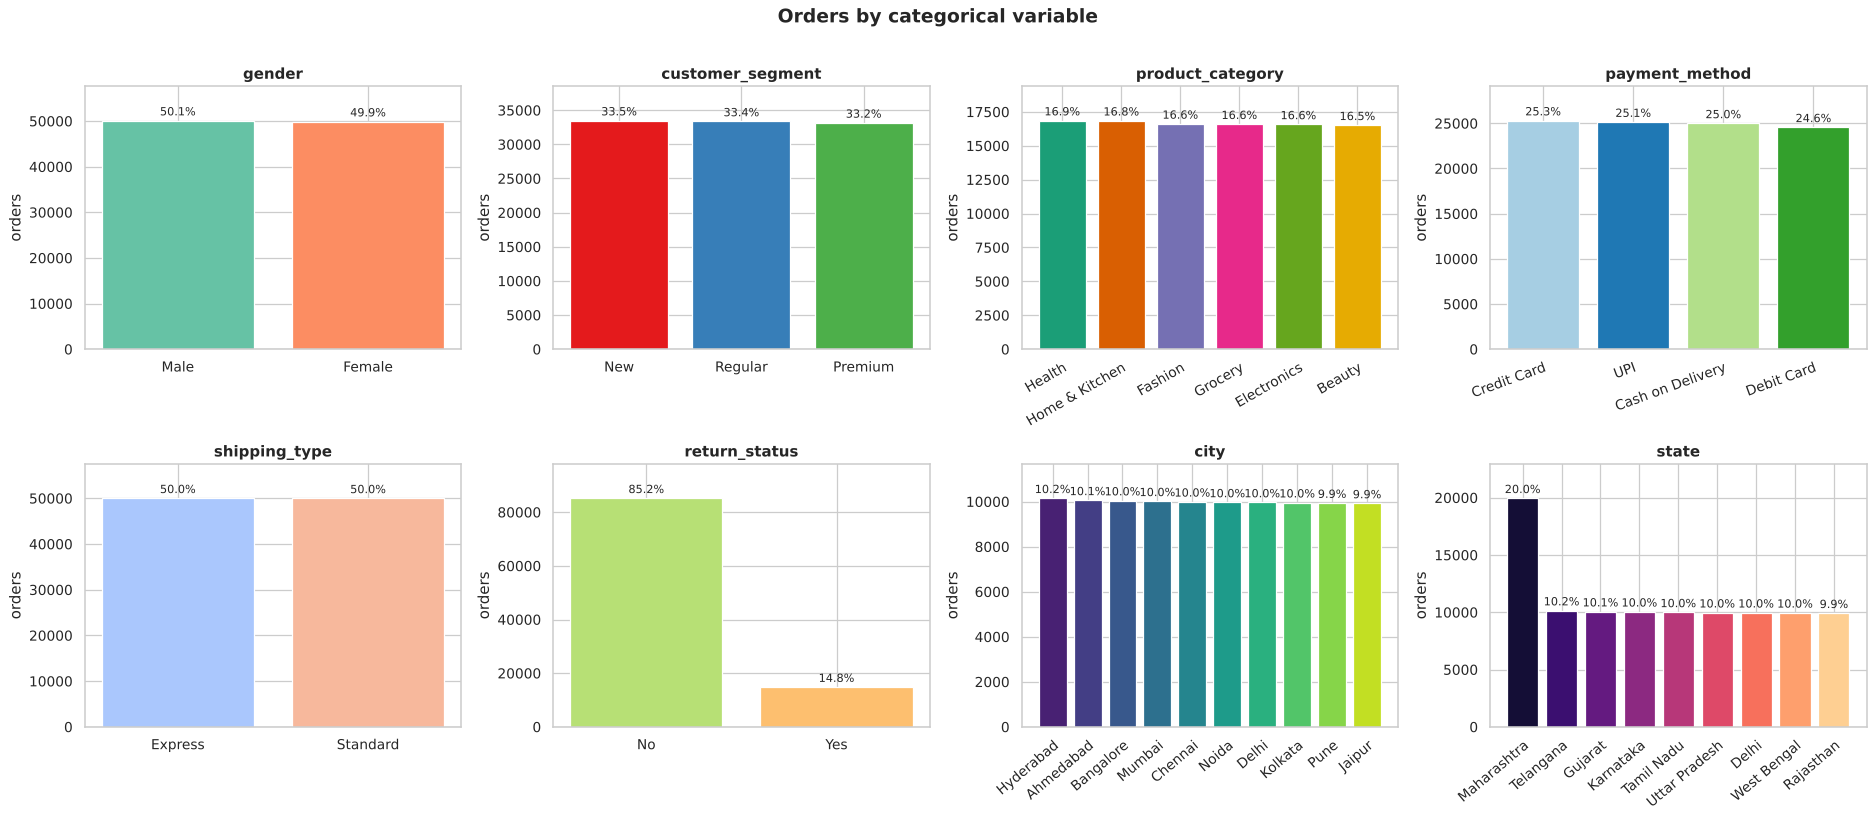

In [21]:
def bar_counts(ax, series, palette, title, rotate=0):
    vc = series.value_counts()
    bars = ax.bar(vc.index.astype(str), vc.values, color=sns.color_palette(palette, len(vc)), edgecolor="white")
    ax.bar_label(bars, labels=[f"{v / len(series):.1%}" for v in vc.values], fontsize=9, padding=2)
    ax.set_title(title)
    ax.set_ylabel("orders")
    ax.set_ylim(0, vc.max() * 1.15)
    ax.tick_params(axis="x", rotation=rotate)
    if rotate:
        plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")

panels = [
    ("gender", "Set2", 0), ("customer_segment", "Set1", 0), ("product_category", "Dark2", 30),
    ("payment_method", "Paired", 20), ("shipping_type", "coolwarm", 0), ("return_status", "RdYlGn_r", 0),
    ("city", "viridis", 40), ("state", "magma", 40),
]
fig, axes = plt.subplots(2, 4, figsize=(21, 9))
for ax, (c, pal, rot) in zip(axes.ravel(), panels):
    bar_counts(ax, retail_data[c], pal, c, rot)
fig.suptitle("Orders by categorical variable", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
save_fig("05_categorical_bars")
plt.show()

### 5.3 Product subcategories and the category × segment mix (using `hue`)

**Objective:** use the `hue` parameter to show which category each subcategory belongs to, and how customer segments are spread within every product category.

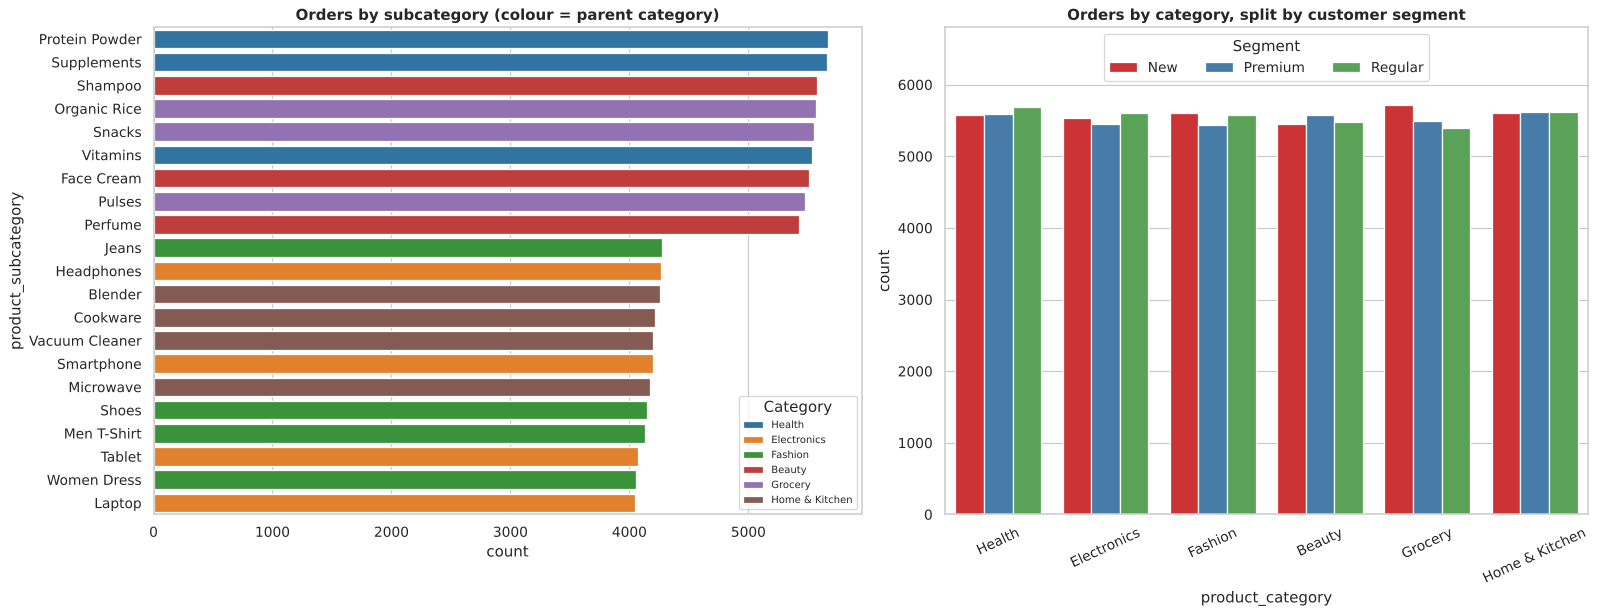

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1.1, 1]})

order = retail_data["product_subcategory"].value_counts().index
sns.countplot(data=retail_data, y="product_subcategory", hue="product_category", order=order,
              dodge=False, palette="tab10", ax=axes[0])
axes[0].set_title("Orders by subcategory (colour = parent category)")
axes[0].legend(title="Category", fontsize=8, loc="lower right")

sns.countplot(data=retail_data, x="product_category", hue="customer_segment", palette="Set1", ax=axes[1])
axes[1].set_title("Orders by category, split by customer segment")
axes[1].tick_params(axis="x", rotation=25)
axes[1].set_ylim(0, 6800)
axes[1].legend(title="Segment", ncol=3, loc="upper center")
plt.tight_layout()
save_fig("05_subcategory_and_segment_mix")
plt.show()

### 5.4 Donut charts

**Objective:** show the share of the main binary and small-category variables at a glance.

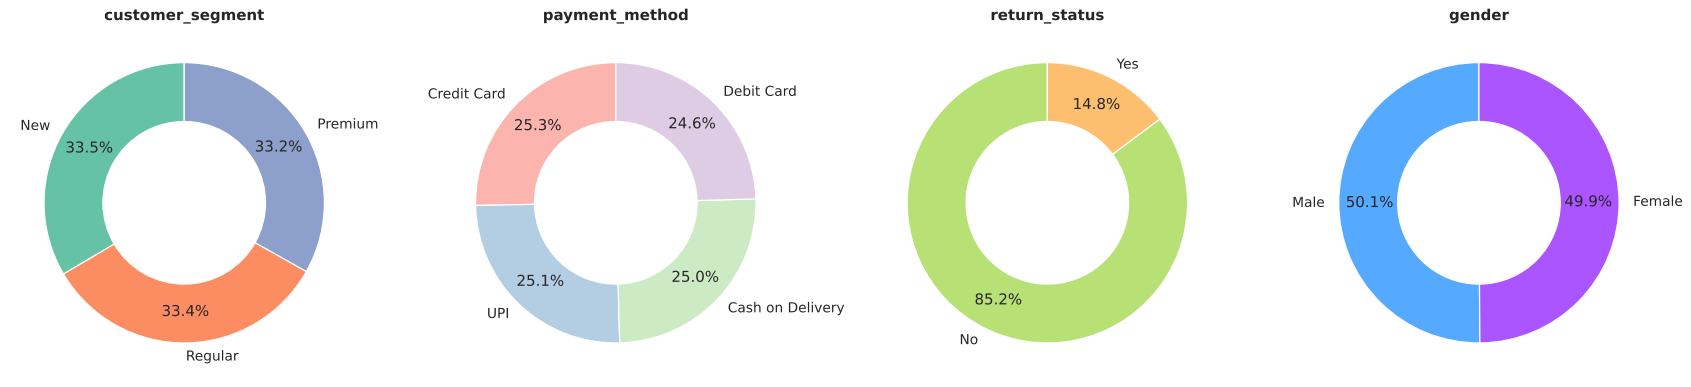

In [23]:
donut_vars = [("customer_segment", "Set2"), ("payment_method", "Pastel1"),
              ("return_status", "RdYlGn_r"), ("gender", "cool")]
fig, axes = plt.subplots(1, 4, figsize=(19, 5))
for ax, (c, pal) in zip(axes, donut_vars):
    vc = retail_data[c].value_counts()
    ax.pie(vc.values, labels=vc.index, autopct="%1.1f%%", startangle=90,
           colors=sns.color_palette(pal, len(vc)), pctdistance=0.78,
           wedgeprops=dict(width=0.42, edgecolor="white"))
    ax.set_title(c)
plt.tight_layout()
save_fig("05_donut_charts")
plt.show()

**Interpretation**

- **The categories are almost perfectly balanced.** Gender is 50.1% / 49.9%; the three customer segments are 33.5% (New), 33.4% (Regular) and 33.2% (Premium); payment methods are all between 24.6% and 25.3%; Express and Standard shipping are 50.0% each; every city is about 10%. So **no single segment is the majority**, and every group is large enough for fair comparisons.
- **Product categories are also nearly equal** (16.5% to 16.9%). Health is the largest (16.9%) and Beauty the smallest (16.5%), a gap of only 0.35 percentage points. Electronics (16.6%) is not the top category.
- **Maharashtra shows 20% of orders**, double any other state, only because it contains two cities (Mumbai and Pune). Per city, volume is the same as everywhere else.
- **Subcategories look uneven (4.0% to 5.7%), but this comes from how they are grouped.** Health, Grocery and Beauty have three subcategories each, so each gets about 5,500 orders. Electronics, Fashion and Home & Kitchen have four each, so each gets about 4,200 orders. The categories sell equally; the volume is just split across more or fewer products.
- **Return status is the only clearly unbalanced variable**: 14.81% of orders (14,811) were returned and 85.19% were kept.
- Customer segments are spread evenly inside every product category, so no category is dominated by one type of customer.

## 6. Outlier Detection and Capping

**Objective:** find extreme values using two standard methods (IQR and Z-score), understand *what kind* of orders the outliers are, and apply a capping (winsorising) method. The main analysis keeps the original values, and the capped version is stored in a separate column.

### 6.1 Detecting outliers: IQR method and Z-score method

**Objective:** count outliers for each numerical variable. IQR rule: a value is an outlier if it is below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. Z-score rule: a value is an outlier if it is more than 3 standard deviations from the mean.

In [24]:
rows = []
fences = {}
for c in num_cols:
    s = retail_data[c]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fences[c] = (lo, hi)
    z = (s - s.mean()) / s.std()
    rows.append({
        "column": c, "min": s.min(), "max": s.max(),
        "IQR lower fence": lo, "IQR upper fence": hi,
        "IQR outliers (low)": int((s < lo).sum()), "IQR outliers (high)": int((s > hi).sum()),
        "IQR outliers (%)": ((s < lo) | (s > hi)).mean() * 100,
        "Z-score outliers (|z|>3)": int((z.abs() > 3).sum()),
    })
outlier_table = pd.DataFrame(rows).set_index("column")
outlier_table

,min,max,IQR lower fence,IQR upper fence,IQR outliers (low),IQR outliers (high),IQR outliers (%),Z-score outliers (|z|>3)
column,,,,,,,,
age,18.00,65.00,-6.00,90.00,0,0,0.00,0
product_price,500.00,"59,998.00","-28,998.00","89,330.00",0,0,0.00,0
quantity,1.00,4.00,-3.50,8.50,0,0,0.00,0
discount_percentage,0.00,30.00,-17.00,47.00,0,0,0.00,0
final_price,357.00,"239,980.00","-79,306.60","198,057.67",0,1335,1.33,503
delivery_days,1.00,10.00,-4.50,15.50,0,0,0.00,0


### 6.2 Who are the `final_price` outliers?

**Objective:** only `final_price` has outliers by the IQR rule. Before touching them, we check what these orders look like, so we can decide whether they are errors or genuine high-value purchases.

Upper fence for final_price: 198,057.67
Outlier orders: 1,335 (1.33% of all orders)
Largest order: 239,980.00 | Median order: 49,752.39

Average profile: normal vs outlier orders


,normal orders,outlier orders
quantity,2.48,4.00
product_price,"29,811.58","56,249.43"
discount_percentage,15.14,5.65
gross_amount,"73,460.52","224,997.73"
final_price,"62,164.67","212,056.44"
age,41.57,41.24
delivery_days,5.50,5.59
is_return,0.15,0.15



Quantity of the outlier orders (% of outliers):
quantity
4   100.00

Category mix of the outlier orders (% of outliers) vs all orders:


,outliers %,all orders %
product_category,,
Beauty,17.60,16.51
Electronics,15.81,16.58
Fashion,15.28,16.61
Grocery,18.50,16.59
Health,15.21,16.86
Home & Kitchen,17.60,16.85


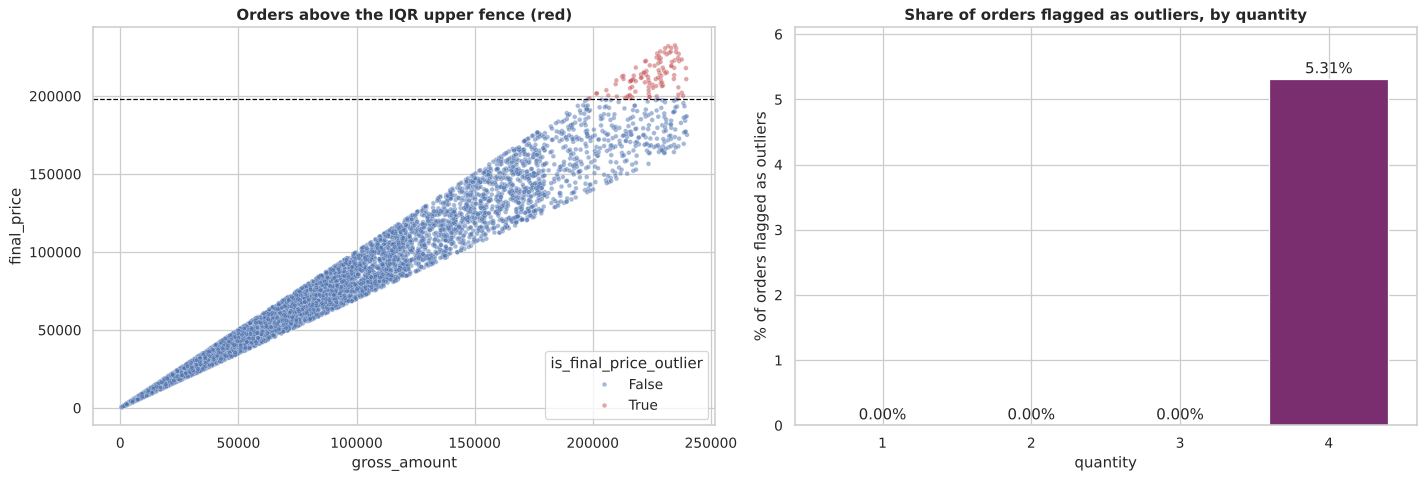

In [25]:
fp_lo, fp_hi = fences["final_price"]
retail_data["is_final_price_outlier"] = (retail_data["final_price"] > fp_hi) | (retail_data["final_price"] < fp_lo)
out = retail_data[retail_data["is_final_price_outlier"]]
print(f"Upper fence for final_price: {fp_hi:,.2f}")
print(f"Outlier orders: {len(out):,} ({len(out) / len(retail_data):.2%} of all orders)")
print(f"Largest order: {retail_data['final_price'].max():,.2f} | Median order: {retail_data['final_price'].median():,.2f}")

profile = retail_data.groupby("is_final_price_outlier")[
    ["quantity", "product_price", "discount_percentage", "gross_amount", "final_price", "age", "delivery_days", "is_return"]
].mean().T
profile.columns = ["normal orders", "outlier orders"]
print("\nAverage profile: normal vs outlier orders")
display(profile)

print("\nQuantity of the outlier orders (% of outliers):")
print((out["quantity"].value_counts(normalize=True).sort_index() * 100).round(1).to_string())
print("\nCategory mix of the outlier orders (% of outliers) vs all orders:")
mix = pd.DataFrame({
    "outliers %": out["product_category"].value_counts(normalize=True) * 100,
    "all orders %": retail_data["product_category"].value_counts(normalize=True) * 100,
})
display(mix)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
samp = retail_data.sample(8000, random_state=42)
sns.scatterplot(data=samp, x="gross_amount", y="final_price", hue="is_final_price_outlier",
                palette={False: "#4C72B0", True: "#C44E52"}, alpha=0.5, s=14, ax=axes[0])
axes[0].axhline(fp_hi, color="black", ls="--", lw=1)
axes[0].set_title("Orders above the IQR upper fence (red)")
share = retail_data.groupby("quantity")["is_final_price_outlier"].mean() * 100
bars = axes[1].bar(share.index.astype(str), share.values, color=sns.color_palette("flare", len(share)), edgecolor="white")
axes[1].bar_label(bars, fmt="%.2f%%", padding=2)
axes[1].set_ylim(0, share.max() * 1.15)
axes[1].set_xlabel("quantity")
axes[1].set_ylabel("% of orders flagged as outliers")
axes[1].set_title("Share of orders flagged as outliers, by quantity")
plt.tight_layout()
save_fig("06_final_price_outliers")
plt.show()

**Interpretation**

- **Only `final_price` has outliers.** The IQR rule flags 1,335 orders (1.33%) above the upper fence of 198,058, and the Z-score rule flags 503 (0.50%). The Z-score finds fewer because it assumes a symmetric, bell-shaped distribution, which does not hold for a skewed variable. The other five variables have no outliers by either method.
- **These outliers are explained by the order itself, not by errors.** Every outlier has the maximum quantity of 4, a high unit price (average 56,249 against 29,812 for normal orders) and a low discount (5.65% against 15.14%). So they are simply the largest possible combination of price × quantity with little discount. About 5% of all quantity-4 orders qualify.
- The outliers are **not concentrated in any product category** (each category contributes 15% to 18.5% of them), and their return rate and customer age are the same as normal orders.
- Conclusion: these are genuine high-value purchases, so the main analysis keeps them. They are capped only in a separate column (next step) to test whether they influence the results.

### 6.3 Capping (winsorising) `final_price`

**Objective:** replace values above the upper IQR fence with the fence value (values below the lower fence would be raised to it, but none exist). The result is stored in a new column `final_price_capped`; the original `final_price` is kept. For comparison, we also test the alternative 1st/99th percentile cap, but do not store it.

,mean,median,std,min,max,skewness,kurtosis,values changed
original final_price,"64,165.72","49,752.39","49,969.28",357.00,"239,980.00",0.93,0.17,0
IQR-capped (stored),"63,978.84","49,752.39","49,425.72",357.00,"198,057.67",0.88,-0.06,1335
1st-99th percentile cap (comparison),"64,046.82","49,752.39","49,590.05","1,750.47","203,401.70",0.90,0.00,2000


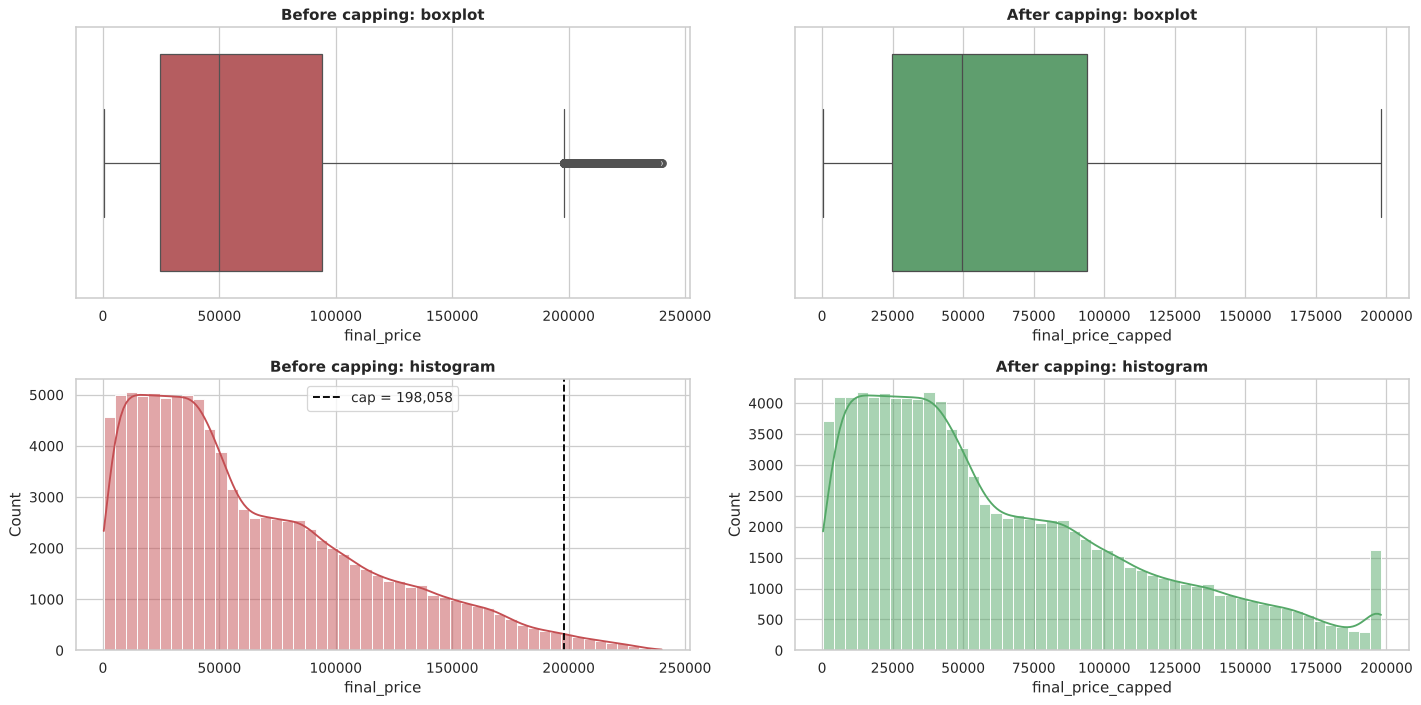

In [26]:
retail_data["final_price_capped"] = retail_data["final_price"].clip(lower=fp_lo, upper=fp_hi)

p1, p99 = retail_data["final_price"].quantile([0.01, 0.99])
cap_pct = retail_data["final_price"].clip(lower=p1, upper=p99)

def cap_stats(s, label, n_capped):
    return pd.Series({"mean": s.mean(), "median": s.median(), "std": s.std(), "min": s.min(), "max": s.max(),
                      "skewness": s.skew(), "kurtosis": s.kurt(), "values changed": n_capped}, name=label)

cap_compare = pd.DataFrame([
    cap_stats(retail_data["final_price"], "original final_price", 0),
    cap_stats(retail_data["final_price_capped"], "IQR-capped (stored)", int((retail_data["final_price"] != retail_data["final_price_capped"]).sum())),
    cap_stats(cap_pct, "1st-99th percentile cap (comparison)", int((retail_data["final_price"] != cap_pct).sum())),
])
cap_compare["values changed"] = cap_compare["values changed"].astype(int)
display(cap_compare)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
sns.boxplot(x=retail_data["final_price"], ax=axes[0, 0], color="#C44E52")
axes[0, 0].set_title("Before capping: boxplot")
sns.boxplot(x=retail_data["final_price_capped"], ax=axes[0, 1], color="#55A868")
axes[0, 1].set_title("After capping: boxplot")
sns.histplot(retail_data["final_price"], bins=50, kde=True, color="#C44E52", ax=axes[1, 0])
axes[1, 0].axvline(fp_hi, color="black", ls="--", label=f"cap = {fp_hi:,.0f}")
axes[1, 0].legend()
axes[1, 0].set_title("Before capping: histogram")
sns.histplot(retail_data["final_price_capped"], bins=50, kde=True, color="#55A868", ax=axes[1, 1])
axes[1, 1].set_title("After capping: histogram")
plt.tight_layout()
save_fig("06_before_after_capping")
plt.show()

**Interpretation**

- Capping replaced the 1,335 values above the fence with 198,057.67. The effect on the overall picture is small: the mean moved from 64,166 to 63,979 (−0.29%), the median did not change at all (49,752), the standard deviation fell slightly (49,969 to 49,426), the maximum dropped from 239,980 to 198,058, skewness eased from 0.93 to 0.88 and kurtosis from 0.17 to −0.06.
- The boxplot after capping has no points beyond the whiskers. The histogram shows a small spike at the cap value, which is the expected side effect of piling the 1,335 extreme orders onto one value.
- The alternative 1st to 99th percentile cap changes 2,000 values (both tails) and gives a similar result (mean 64,047). Either method would lead to the same conclusions, because only 1.33% of orders are affected.
- We keep the IQR-capped version as the column `final_price_capped`, alongside the untouched `final_price`.

### 6.4 Do the conclusions change after capping? Then save the processed dataset

**Objective:** check that capping does not change the business picture (average spend by segment, and the correlation of `final_price` with its drivers), then save the cleaned dataset with the capped column to `data/Processed_dataset.csv`.

In [27]:
robust = retail_data.groupby("customer_segment")[["final_price", "final_price_capped"]].mean()
robust["difference %"] = (robust["final_price_capped"] / robust["final_price"] - 1) * 100
print("Average order value by customer segment")
display(robust)

corr_check = pd.DataFrame({
    "with original final_price": retail_data[["product_price", "quantity", "discount_percentage", "age", "delivery_days"]].corrwith(retail_data["final_price"]),
    "with capped final_price": retail_data[["product_price", "quantity", "discount_percentage", "age", "delivery_days"]].corrwith(retail_data["final_price_capped"]),
})
print("\nPearson correlation of final_price with its drivers")
display(corr_check)

processed_path = os.path.join(DATA_DIR, "Processed_dataset.csv")
retail_data.to_csv(processed_path, index=False)
print(f"\nSaved {processed_path}: {retail_data.shape[0]:,} rows x {retail_data.shape[1]} columns")
print("New columns added to the original 18:", [c for c in retail_data.columns if c not in retail_data_raw.columns])

Average order value by customer segment


,final_price,final_price_capped,difference %
customer_segment,,,
New,"63,766.75","63,584.86",-0.29
Premium,"64,430.45","64,243.79",-0.29
Regular,"64,303.15","64,111.04",-0.30



Pearson correlation of final_price with its drivers


,with original final_price,with capped final_price
product_price,0.73,0.73
quantity,0.58,0.58
discount_percentage,-0.14,-0.13
age,-0.00,-0.00
delivery_days,0.00,0.00



Saved data/Processed_dataset.csv: 100,000 rows x 33 columns
New columns added to the original 18: ['order_year', 'order_quarter', 'order_month', 'order_month_name', 'order_weekday', 'year_month', 'gross_amount', 'discount_amount', 'revenue_per_unit', 'is_return', 'age_group', 'discount_band', 'delivery_speed', 'is_final_price_outlier', 'final_price_capped']


**Interpretation**

- **Capping does not change any conclusion.** Average order value by segment drops by about 0.3% in every segment, and the ranking stays the same (Premium, then Regular, then New). The correlations of `final_price` with its drivers are identical to two decimals (price 0.73, quantity 0.58, discount −0.14 vs −0.13, age and delivery days 0.00).
- This supports keeping outliers in the main analysis: they are valid orders and they do not distort the story.
- `data/Processed_dataset.csv` was saved with **100,000 rows and 33 columns**: the 18 original columns, 13 engineered features, the outlier flag and the capped price column.

## 7. Bivariate Analysis: Numerical vs Numerical

**Objective:** measure and visualise how pairs of numerical variables move together. We use Pearson correlation (linear relationships) and Spearman correlation (rank-based, less affected by skew and outliers).

### 7.1 Scatter plots and trend views

**Objective:** look at the main relationships visually. A sample of 6,000 orders is used for scatter plots (to keep them readable); the line and box charts use all 100,000 orders.

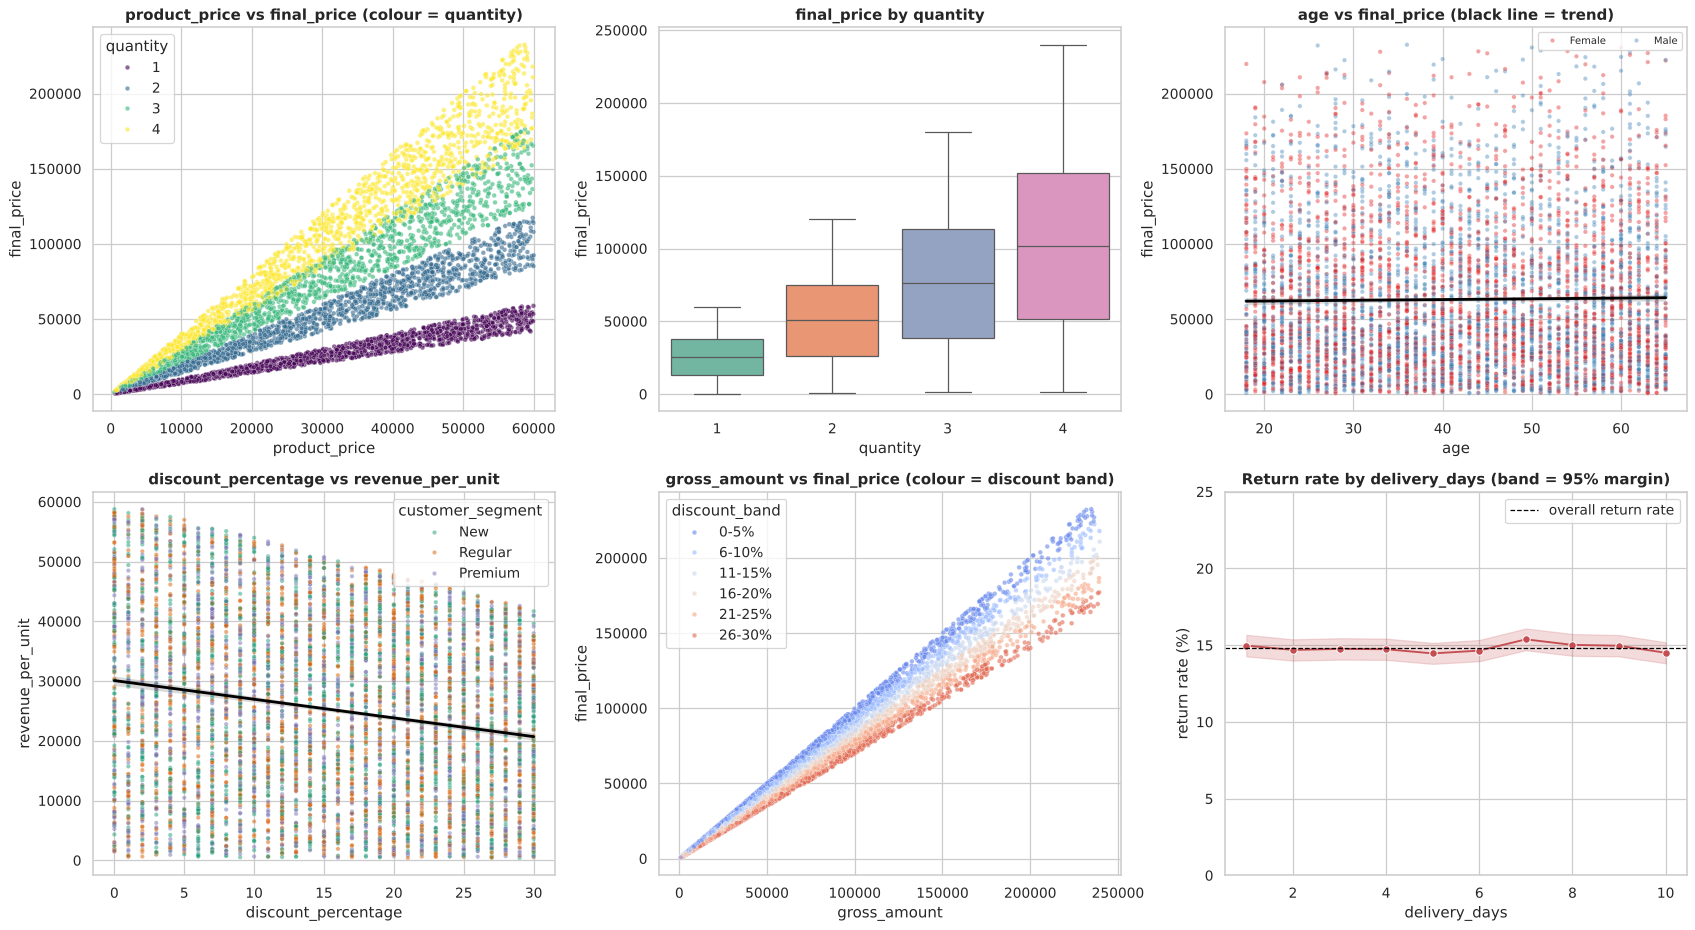

In [28]:
samp = retail_data.sample(6000, random_state=42)
retail_plot_data = retail_data.assign(return_pct=retail_data["is_return"] * 100)

fig, axes = plt.subplots(2, 3, figsize=(19, 10.5))

sns.scatterplot(data=samp, x="product_price", y="final_price", hue="quantity",
                palette="viridis", alpha=0.6, s=14, ax=axes[0, 0])
axes[0, 0].set_title("product_price vs final_price (colour = quantity)")

sns.boxplot(data=retail_data, x="quantity", y="final_price", hue="quantity", palette="Set2", legend=False,
            flierprops=dict(marker="o", markersize=2, alpha=0.3), ax=axes[0, 1])
axes[0, 1].set_title("final_price by quantity")

sns.scatterplot(data=samp, x="age", y="final_price", hue="gender", palette="Set1", alpha=0.4, s=12, ax=axes[0, 2])
sns.regplot(data=samp, x="age", y="final_price", scatter=False, color="black", ax=axes[0, 2])
axes[0, 2].legend(loc="upper right", ncol=2, fontsize=8)
axes[0, 2].set_title("age vs final_price (black line = trend)")

sns.scatterplot(data=samp, x="discount_percentage", y="revenue_per_unit", hue="customer_segment",
                palette="Dark2", alpha=0.5, s=12, ax=axes[1, 0])
sns.regplot(data=samp, x="discount_percentage", y="revenue_per_unit", scatter=False, color="black", ax=axes[1, 0])
axes[1, 0].set_title("discount_percentage vs revenue_per_unit")

sns.scatterplot(data=samp, x="gross_amount", y="final_price", hue="discount_band",
                palette="coolwarm", alpha=0.6, s=14, ax=axes[1, 1])
axes[1, 1].set_title("gross_amount vs final_price (colour = discount band)")

sns.lineplot(data=retail_plot_data, x="delivery_days", y="return_pct", marker="o", color="#C44E52",
             errorbar=("se", 1.96), ax=axes[1, 2])
axes[1, 2].axhline(retail_data["is_return"].mean() * 100, color="black", ls="--", lw=1, label="overall return rate")
axes[1, 2].set_ylim(0, 25)
axes[1, 2].set_ylabel("return rate (%)")
axes[1, 2].legend()
axes[1, 2].set_title("Return rate by delivery_days (band = 95% margin)")

plt.tight_layout()
save_fig("07_scatter_relationships")
plt.show()

### 7.2 Correlation matrices (Pearson and Spearman heatmaps)

**Objective:** measure the strength and direction of every numerical relationship in one view. `final_price_capped` and `revenue_per_unit` are included to see how derived columns behave.

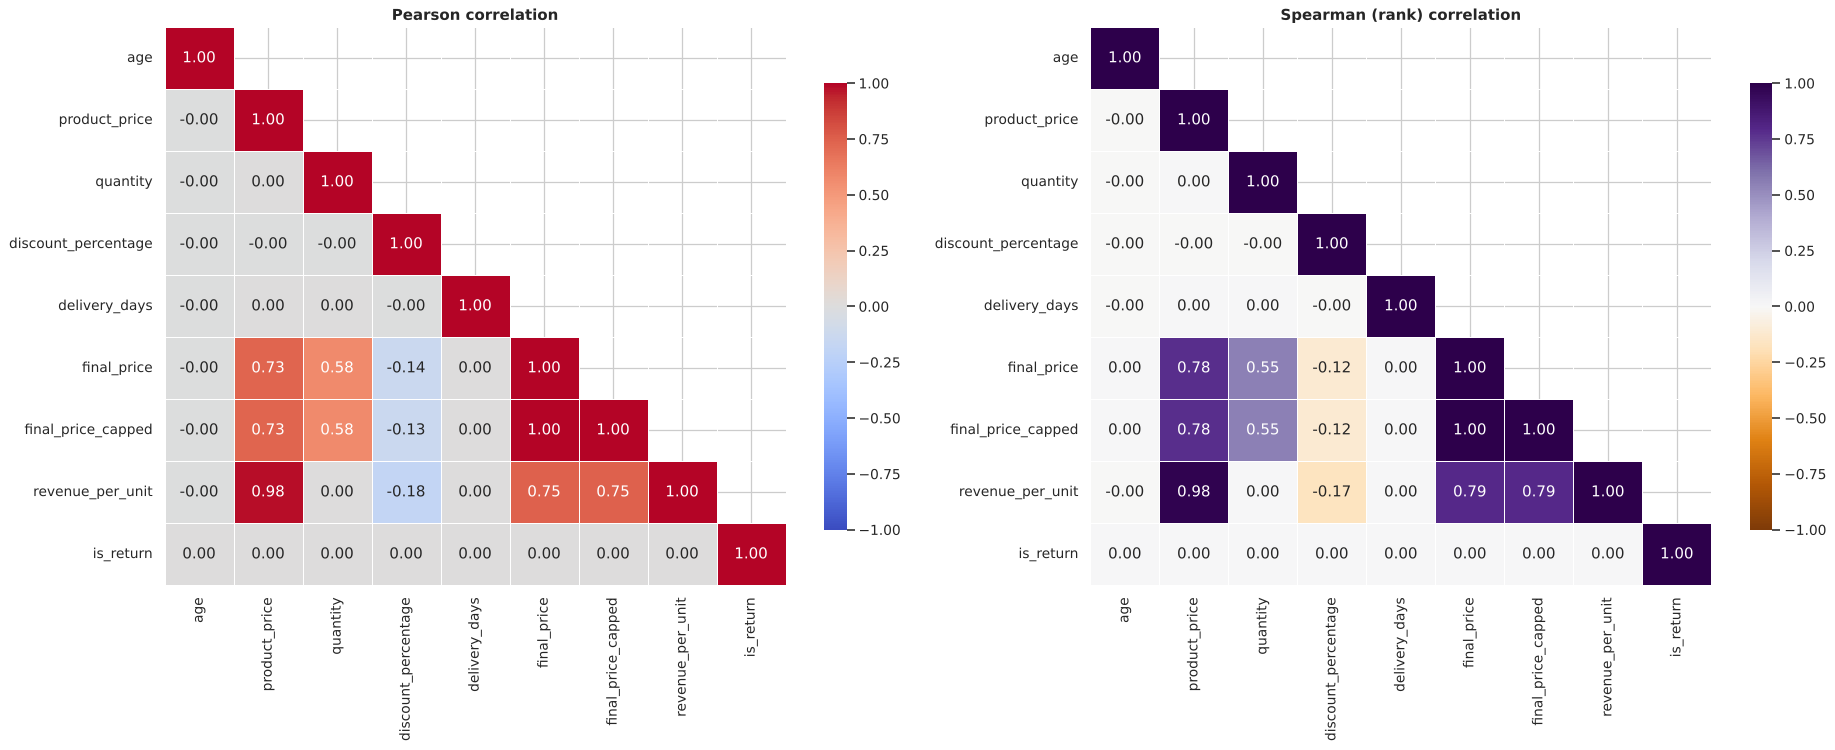

Correlation of final_price with the other variables (strongest first)


,Pearson,Spearman
revenue_per_unit,0.75,0.79
product_price,0.73,0.78
quantity,0.58,0.55
discount_percentage,-0.14,-0.12
delivery_days,0.00,0.00
is_return,0.00,0.00
age,-0.00,0.00


In [29]:
corr_cols = ["age", "product_price", "quantity", "discount_percentage", "delivery_days",
             "final_price", "final_price_capped", "revenue_per_unit", "is_return"]
pearson = retail_data[corr_cols].corr(method="pearson")
spearman = retail_data[corr_cols].corr(method="spearman")
mask = np.triu(np.ones_like(pearson, dtype=bool), k=1)

fig, axes = plt.subplots(1, 2, figsize=(21, 8.5))
sns.heatmap(pearson, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=axes[0])
axes[0].set_title("Pearson correlation")
sns.heatmap(spearman, mask=mask, annot=True, fmt=".2f", cmap="PuOr", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=axes[1])
axes[1].set_title("Spearman (rank) correlation")
plt.tight_layout()
save_fig("07_correlation_heatmaps")
plt.show()

rank = pd.DataFrame({"Pearson": pearson["final_price"], "Spearman": spearman["final_price"]})
rank = rank.drop(["final_price", "final_price_capped"]).sort_values("Pearson", key=abs, ascending=False)
print("Correlation of final_price with the other variables (strongest first)")
display(rank)

### 7.3 Is a return linked to any numerical variable?

**Objective:** `is_return` is a 0/1 variable, so we use the point-biserial correlation (Pearson on a binary variable) with a significance test.

In [30]:
rows = []
for c in ["age", "product_price", "quantity", "discount_percentage", "delivery_days", "final_price"]:
    r, p = stats.pointbiserialr(retail_data["is_return"], retail_data[c])
    rows.append({"variable": c, "r (point-biserial)": f"{r:.4f}", "p-value": f"{p:.3g}", "significant (p < 0.05)": bool(p < 0.05)})
pd.DataFrame(rows).set_index("variable")

,r (point-biserial),p-value,significant (p < 0.05)
variable,,,
age,0.0004,0.893,False
product_price,0.0011,0.722,False
quantity,0.0028,0.369,False
discount_percentage,0.0007,0.83,False
delivery_days,0.0005,0.868,False
final_price,0.0020,0.519,False


**Interpretation**

- **`final_price` is driven by three variables.** The Pearson correlations are +0.73 with `product_price`, +0.58 with `quantity` and −0.14 with `discount_percentage` (Spearman: 0.78, 0.55 and −0.12). The Spearman values are close to the Pearson values, so the skew is not distorting these results. The scatter plot shows `final_price` spreading into four bands, one per quantity; median order value climbs from roughly 25,000 for one unit to roughly 100,000 for four units. Within each band, higher discounts push the point lower.
- **These strong relationships exist by construction.** Section 3.6 showed `final_price` is calculated from price, quantity and discount, so the correlations confirm the formula rather than reveal customer behaviour. `revenue_per_unit` correlates 0.98 with `product_price` for the same reason.
- **Everything else is uncorrelated.** Age, price, quantity, discount and delivery days all have correlations of about 0.00 with each other. Age has no relationship with spending (r ≈ 0.00), and delivery days has none either.
- **Return status is not linked to any numerical variable.** Every point-biserial correlation is below 0.003 in size, with p-values from 0.37 to 0.89, so none is significant. In particular, `delivery_days` vs returns has r = 0.0005 (p = 0.87), and the return-rate line by delivery days stays flat around the overall 14.8%.
- `final_price_capped` produces the same correlations as `final_price`.

## 8. Bivariate Analysis: Numerical vs Categorical

**Objective:** compare spending (`final_price`) and delivery time across groups (segment, category, payment method, shipping type, gender, age group and city), then test whether any difference is statistically real and practically meaningful.

### 8.1 Group summary tables

**Objective:** compare mean and median order value for each group. Because `final_price` is right-skewed, the median is the more typical value. `mean_capped` uses the capped column from section 6.

In [31]:
overall_mean = retail_data["final_price"].mean()

def group_summary(by):
    g = retail_data.groupby(by, observed=True).agg(
        orders=("final_price", "size"),
        mean_final_price=("final_price", "mean"),
        median_final_price=("final_price", "median"),
        mean_capped=("final_price_capped", "mean"),
        std=("final_price", "std"),
    )
    g["mean vs overall (%)"] = (g["mean_final_price"] / overall_mean - 1) * 100
    return g.sort_values("mean_final_price", ascending=False)

print(f"Overall: mean = {overall_mean:,.2f} | median = {retail_data['final_price'].median():,.2f}")
for by in ["customer_segment", "product_category", "payment_method", "shipping_type", "gender", "age_group", "city"]:
    print(f"\nOrder value by {by}")
    display(group_summary(by))

Overall: mean = 64,165.72 | median = 49,752.39

Order value by customer_segment


,orders,mean_final_price,median_final_price,mean_capped,std,mean vs overall (%)
customer_segment,,,,,,
Premium,33151,"64,430.45","50,273.88","64,243.79","49,978.06",0.41
Regular,33361,"64,303.15","49,767.84","64,111.04","50,050.24",0.21
New,33488,"63,766.75","49,224.52","63,584.86","49,878.81",-0.62



Order value by product_category


,orders,mean_final_price,median_final_price,mean_capped,std,mean vs overall (%)
product_category,,,,,,
Home & Kitchen,16848,"64,840.42","50,366.47","64,645.20","50,275.75",1.05
Electronics,16576,"64,329.67","50,195.79","64,157.82","49,651.64",0.26
Grocery,16592,"64,101.81","49,478.34","63,897.78","50,248.87",-0.10
Beauty,16513,"64,030.55","49,621.32","63,826.35","50,075.70",-0.21
Fashion,16613,"64,002.19","49,765.24","63,833.38","50,056.28",-0.25
Health,16858,"63,686.69","49,294.98","63,509.39","49,504.93",-0.75



Order value by payment_method


,orders,mean_final_price,median_final_price,mean_capped,std,mean vs overall (%)
payment_method,,,,,,
Debit Card,24560,"64,714.76","50,282.84","64,509.74","50,359.41",0.86
UPI,25139,"64,104.53","49,640.80","63,911.37","49,972.57",-0.10
Credit Card,25307,"63,962.02","49,454.61","63,785.03","49,814.07",-0.32
Cash on Delivery,24994,"63,894.03","49,628.15","63,721.26","49,736.32",-0.42


... (4 outputs left out)


Order value by age_group


,orders,mean_final_price,median_final_price,mean_capped,std,mean vs overall (%)
age_group,,,,,,
26-35,20718,"64,600.49","49,893.48","64,399.74","50,429.00",0.68
46-55,20908,"64,411.14","50,064.14","64,226.45","49,898.76",0.38
36-45,20815,"64,004.92","49,647.76","63,840.89","49,817.22",-0.25
18-25,16599,"63,903.33","49,132.48","63,721.97","49,931.30",-0.41
56-65,20960,"63,858.66","49,990.13","63,656.22","49,764.05",-0.48



Order value by city


,orders,mean_final_price,median_final_price,mean_capped,std,mean vs overall (%)
city,,,,,,
Chennai,9993,"65,107.98","50,638.80","64,898.74","50,512.85",1.47
Mumbai,10015,"64,787.77","50,402.88","64,585.56","50,160.89",0.97
Jaipur,9920,"64,481.22","49,277.34","64,283.25","50,666.74",0.49
Kolkata,9955,"64,286.89","49,872.00","64,104.00","49,619.14",0.19
Ahmedabad,10057,"64,102.31","49,816.20","63,920.28","49,835.74",-0.10
Hyderabad,10150,"64,081.53","49,658.28","63,893.50","50,041.39",-0.13
Pune,9937,"63,824.77","49,323.00","63,614.28","49,969.02",-0.53
Noida,9964,"63,818.44","49,446.29","63,647.07","49,894.60",-0.54
Bangalore,10047,"63,795.19","49,212.90","63,621.17","49,707.68",-0.58


### 8.2 Mean order value by group (bar charts)

**Objective:** see the group differences on an honest scale (bars start at zero). Error bars show a 95% margin around each mean, and the dashed line is the overall mean.

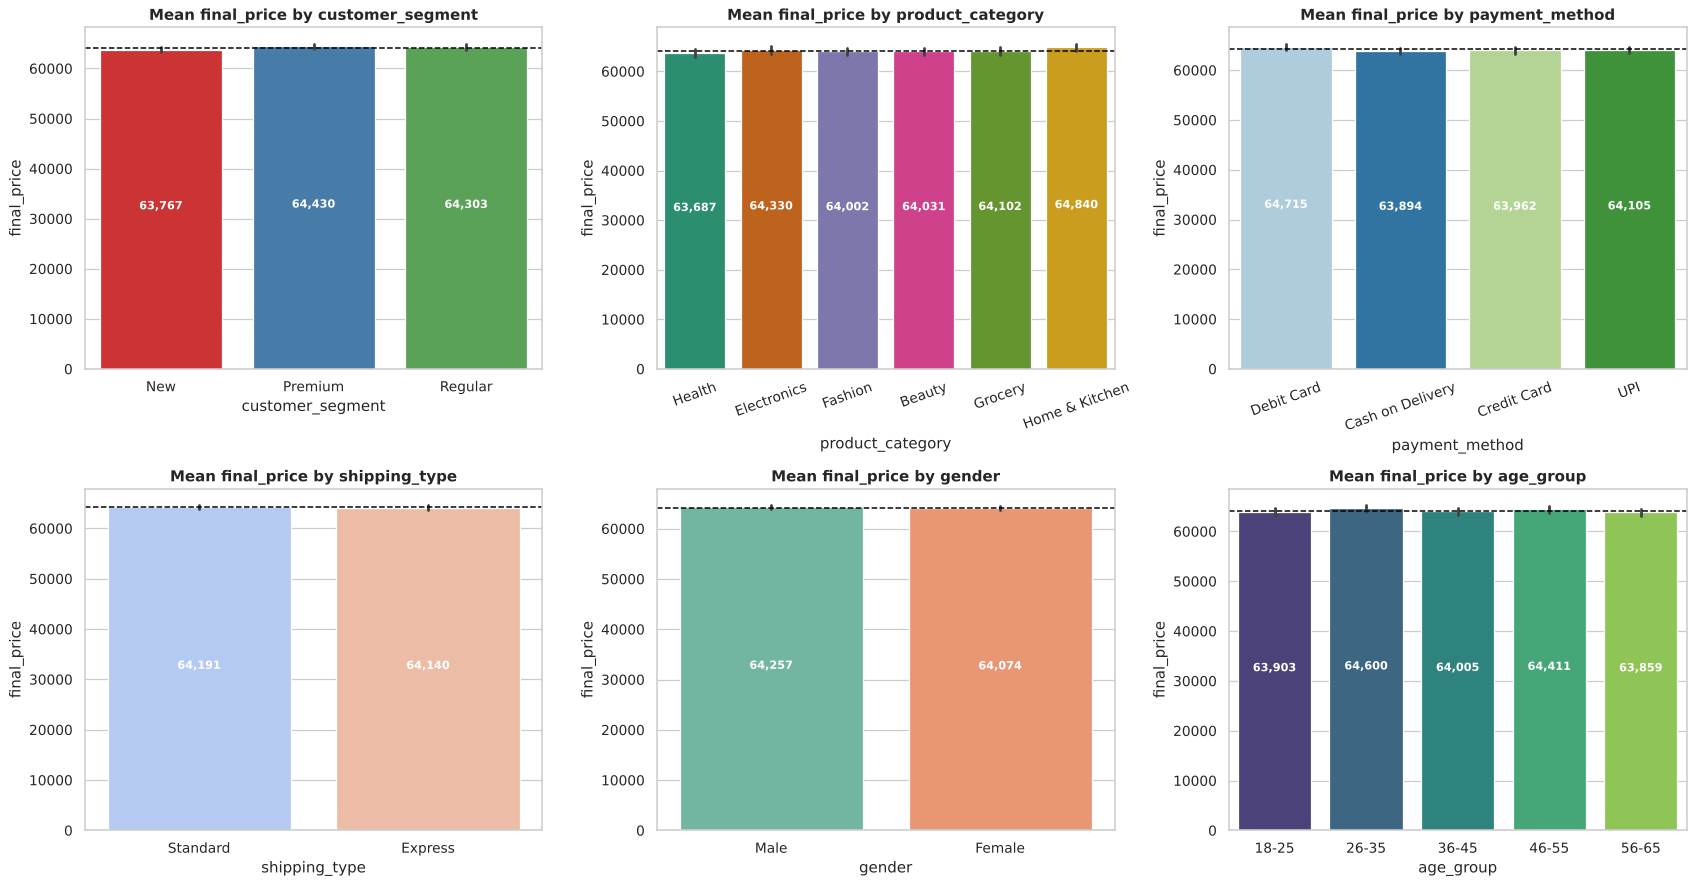

In [32]:
specs = [("customer_segment", "Set1"), ("product_category", "Dark2"), ("payment_method", "Paired"),
         ("shipping_type", "coolwarm"), ("gender", "Set2"), ("age_group", "viridis")]

fig, axes = plt.subplots(2, 3, figsize=(19, 10))
for ax, (c, pal) in zip(axes.ravel(), specs):
    sns.barplot(data=retail_data, x=c, y="final_price", hue=c, palette=pal, errorbar=("se", 1.96),
                dodge=False, legend=False, edgecolor="white", ax=ax)
    ax.axhline(overall_mean, color="black", ls="--", lw=1.2)
    for p in ax.patches:
        h = p.get_height()
        if h == h and h > 0:
            ax.annotate(f"{h:,.0f}", (p.get_x() + p.get_width() / 2, h * 0.5), ha="center", color="white",
                        fontsize=9, fontweight="bold")
    ax.set_title(f"Mean final_price by {c}")
    ax.tick_params(axis="x", rotation=20 if c in ("product_category", "payment_method") else 0)
plt.tight_layout()
save_fig("08_mean_by_group")
plt.show()

### 8.3 Distribution of order value by group (box and violin plots)

**Objective:** compare the whole distribution, not only the average.

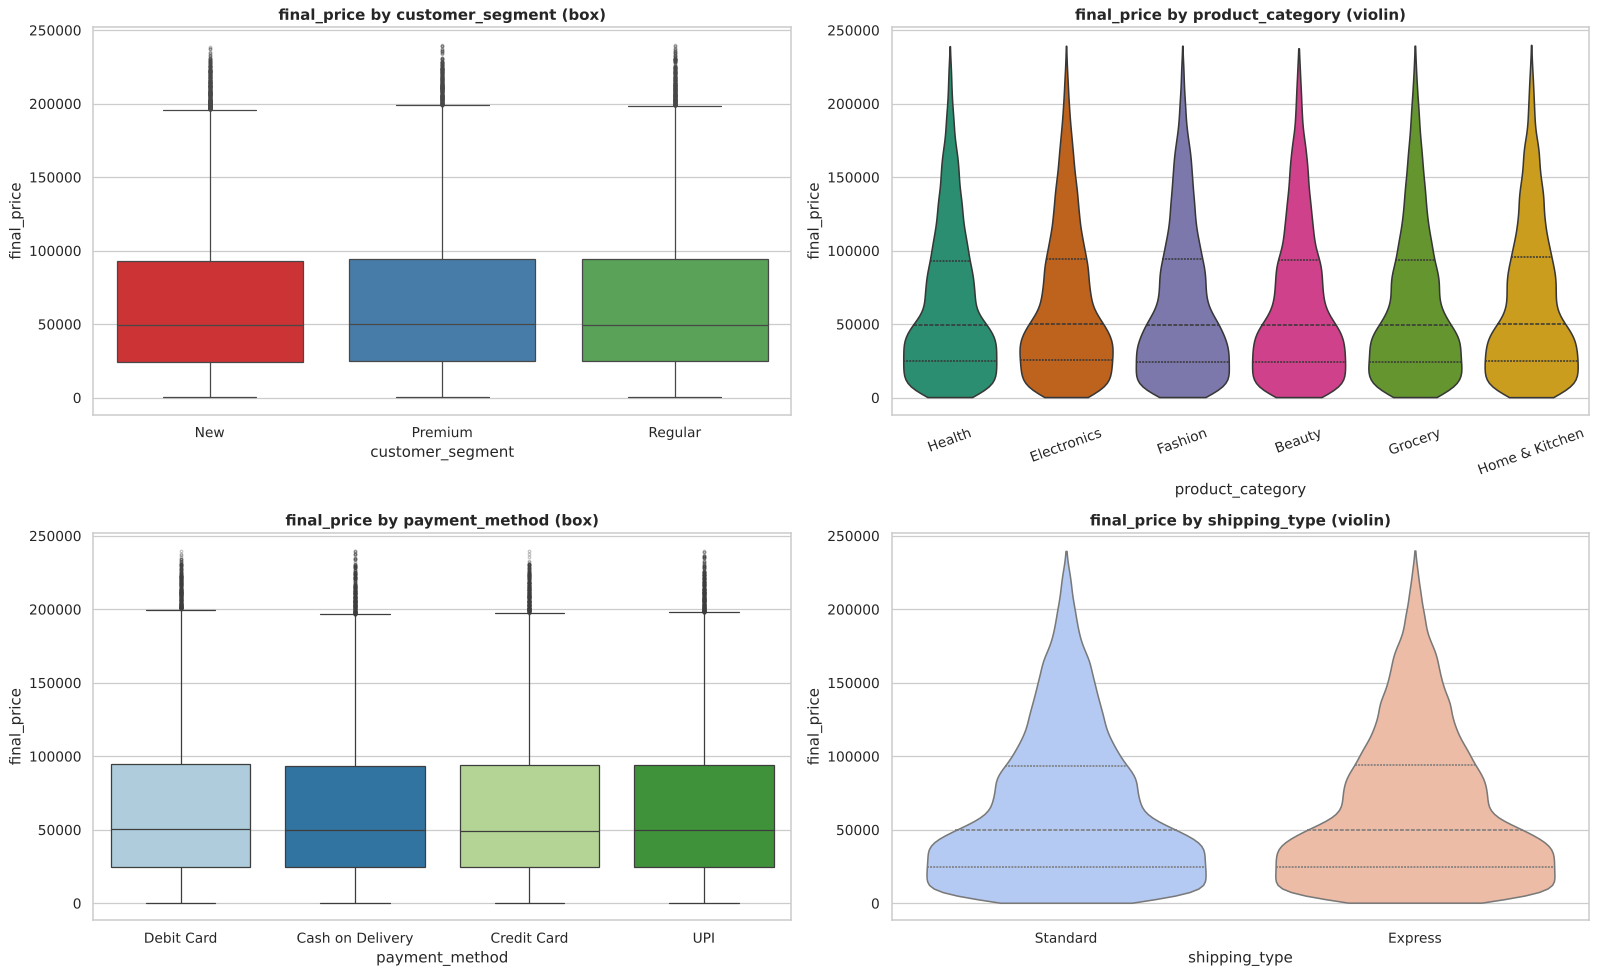

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11))
sns.boxplot(data=retail_data, x="customer_segment", y="final_price", hue="customer_segment", palette="Set1", legend=False,
            flierprops=dict(marker="o", markersize=2, alpha=0.3), ax=axes[0, 0])
axes[0, 0].set_title("final_price by customer_segment (box)")
sns.violinplot(data=retail_data, x="product_category", y="final_price", hue="product_category", palette="Dark2",
               legend=False, cut=0, inner="quartile", ax=axes[0, 1])
axes[0, 1].set_title("final_price by product_category (violin)")
axes[0, 1].tick_params(axis="x", rotation=20)
sns.boxplot(data=retail_data, x="payment_method", y="final_price", hue="payment_method", palette="Paired", legend=False,
            flierprops=dict(marker="o", markersize=2, alpha=0.3), ax=axes[1, 0])
axes[1, 0].set_title("final_price by payment_method (box)")
sns.violinplot(data=retail_data, x="shipping_type", y="final_price", hue="shipping_type", palette="coolwarm",
               legend=False, cut=0, inner="quartile", ax=axes[1, 1])
axes[1, 1].set_title("final_price by shipping_type (violin)")
plt.tight_layout()
save_fig("08_distribution_by_group")
plt.show()

### 8.4 Shipping type vs delivery days

**Objective:** check whether Express shipping really delivers faster, and whether delivery time differs by city.

               mean  median  std  min  max
shipping_type                             
Express        5.50    5.00 2.87    1   10
Standard       5.51    6.00 2.88    1   10

Welch t-test Express vs Standard delivery_days: t = -0.896, p = 0.37


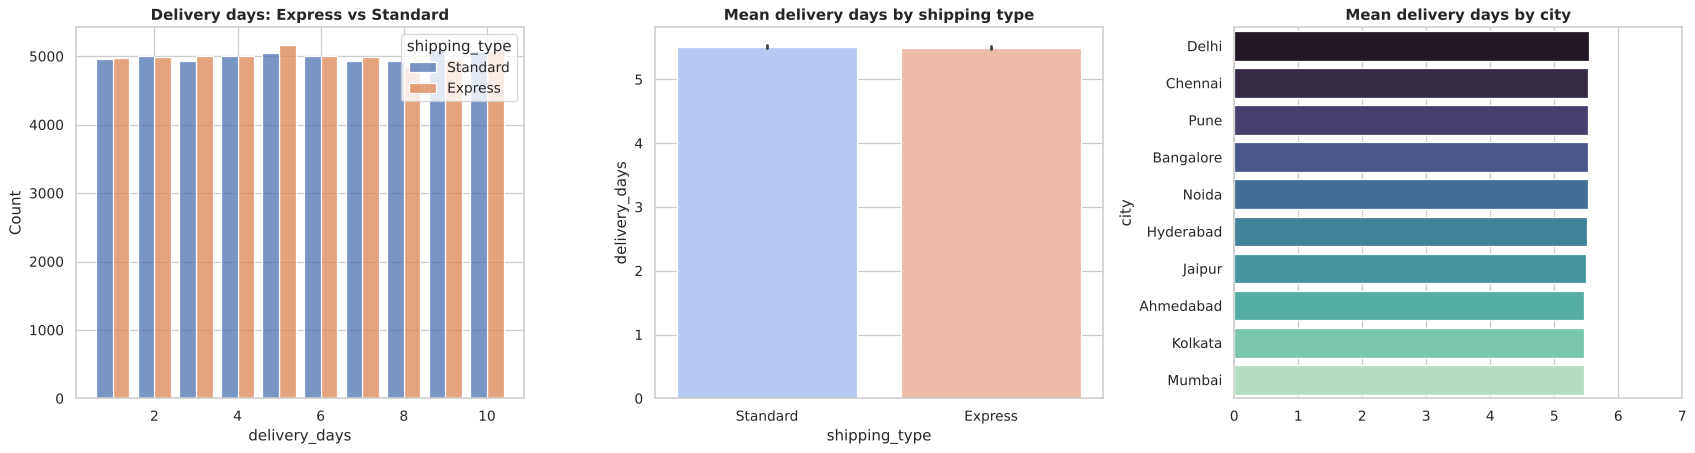

In [34]:
print(retail_data.groupby("shipping_type")["delivery_days"].agg(["mean", "median", "std", "min", "max"]).round(2).to_string())
t, p = stats.ttest_ind(retail_data.loc[retail_data["shipping_type"] == "Express", "delivery_days"],
                       retail_data.loc[retail_data["shipping_type"] == "Standard", "delivery_days"], equal_var=False)
print(f"\nWelch t-test Express vs Standard delivery_days: t = {t:.3f}, p = {p:.3g}")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
sns.histplot(data=retail_data, x="delivery_days", hue="shipping_type", multiple="dodge", discrete=True, shrink=0.8,
             palette=["#4C72B0", "#DD8452"], ax=axes[0])
axes[0].set_title("Delivery days: Express vs Standard")
sns.barplot(data=retail_data, x="shipping_type", y="delivery_days", hue="shipping_type", palette="coolwarm",
            errorbar=("se", 1.96), legend=False, ax=axes[1])
axes[1].set_title("Mean delivery days by shipping type")
city_means = retail_data.groupby("city")["delivery_days"].mean().sort_values(ascending=False)
sns.barplot(x=city_means.values, y=city_means.index, hue=city_means.index, palette="mako", legend=False, ax=axes[2])
axes[2].set_xlim(0, 7)
axes[2].set_title("Mean delivery days by city")
plt.tight_layout()
save_fig("08_delivery_days")
plt.show()

### 8.5 Statistical tests: are the group differences real?

**Objective:** with 100,000 rows even tiny differences can look "significant". So for every comparison we report (1) a p-value from ANOVA and from the rank-based Kruskal-Wallis test, and (2) an **effect size** (η², the share of variation explained by the grouping). A Bonferroni-adjusted threshold is used because we run several tests at once.

In [35]:
def anova_eta(valuevar, groupvar):
    groups = [g[valuevar].to_numpy() for _, g in retail_data.groupby(groupvar, observed=True)]
    F, p_a = stats.f_oneway(*groups)
    H, p_k = stats.kruskal(*groups)
    grand = retail_data[valuevar].mean()
    ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    sst = ((retail_data[valuevar] - grand) ** 2).sum()
    return {"numeric variable": valuevar, "grouped by": groupvar, "F (ANOVA)": F, "p (ANOVA)": p_a,
            "H (Kruskal)": H, "p (Kruskal)": p_k, "eta squared": ssb / sst}

def effect_label(e):
    return "negligible" if e < 0.01 else "small" if e < 0.06 else "medium" if e < 0.14 else "large"

tests = [("final_price", g) for g in ["customer_segment", "product_category", "payment_method",
                                      "shipping_type", "gender", "age_group", "city"]]
tests += [("delivery_days", g) for g in ["shipping_type", "customer_segment", "product_category"]]

anova_table = pd.DataFrame([anova_eta(*t) for t in tests])
alpha_adj = 0.05 / len(tests)
anova_table["effect size"] = anova_table["eta squared"].apply(effect_label)
anova_table["significant (p < 0.05)"] = anova_table["p (ANOVA)"] < 0.05
anova_table[f"significant (Bonferroni, p < {alpha_adj:.4f})"] = anova_table["p (ANOVA)"] < alpha_adj
for c in ["p (ANOVA)", "p (Kruskal)"]:
    anova_table[c] = anova_table[c].apply(lambda x: f"{x:.3g}")
anova_table["eta squared"] = anova_table["eta squared"].apply(lambda x: f"{x:.6f}")
anova_table

,numeric variable,grouped by,F (ANOVA),p (ANOVA),H (Kruskal),p (Kruskal),eta squared,effect size,significant (p < 0.05),"significant (Bonferroni, p < 0.0050)"
0,final_price,customer_segment,1.66,0.19,3.91,0.141,0.000033,negligible,False,False
1,final_price,product_category,1.03,0.401,5.04,0.41,0.000051,negligible,False,False
2,final_price,payment_method,1.39,0.244,2.96,0.399,0.000042,negligible,False,False
3,final_price,shipping_type,0.03,0.871,0.01,0.91,0.000000,negligible,False,False
4,final_price,gender,0.34,0.563,0.96,0.326,0.000003,negligible,False,False
5,final_price,age_group,0.88,0.472,3.12,0.538,0.000035,negligible,False,False
6,final_price,city,1.07,0.382,7.68,0.567,0.000096,negligible,False,False
7,delivery_days,shipping_type,0.80,0.37,0.80,0.372,0.000008,negligible,False,False
8,delivery_days,customer_segment,0.87,0.418,1.74,0.418,0.000017,negligible,False,False
9,delivery_days,product_category,0.47,0.8,2.34,0.801,0.000023,negligible,False,False


**Interpretation**

- **Average spending is almost identical for every group.** By customer segment the mean order value ranges from 63,767 (New) to 64,430 (Premium), a gap of 1.0%; by category from 63,687 (Health) to 64,840 (Home & Kitchen), 1.8%; by payment method from 63,894 to 64,715 (Debit Card), 1.3%; by age group from 63,859 to 64,600 (26-35), 1.2%; by city from 63,371 (Delhi) to 65,108 (Chennai), 2.7%. Gender (64,257 vs 64,074) and shipping type (64,191 vs 64,140) differ by less than 0.3%.
- **Medians tell the same story** (about 49,000 to 50,600 everywhere), and in every group the mean sits roughly 29% above the median because of the right skew. The capped means are about 0.3% lower in every group, in the same order.
- **Premium customers spend only 0.4% more than the overall average**, and the bar charts show overlapping error bars and bars that all touch the same dashed line.
- **Express shipping is not faster in this data.** Express averages 5.50 delivery days and Standard 5.51 (Welch t-test p = 0.37). Both are spread evenly from 1 to 10 days. Delivery time also does not differ by customer segment or product category.
- **Statistical tests agree.** All 10 ANOVA tests have p-values between 0.19 and 0.87 (Kruskal-Wallis: 0.14 to 0.91), so none is significant even before the stricter Bonferroni threshold of 0.005. The effect size η² is between 0 and 0.0001, meaning the grouping explains at most about 0.01% of the variation in order value or delivery time.
- **Take-away:** *who* the customer is (segment, gender, age, city) or *how* they pay or ship has no measurable effect on spending. Order value depends on what is in the order (price, quantity, discount).

## 9. Bivariate Analysis: Categorical vs Categorical

**Objective:** study the return rate across groups and check whether the categorical variables are associated with each other, using cross-tabulations, heatmaps and chi-square tests.

### 9.1 Return rate by group

**Objective:** compare the return rate (share of orders returned) across each categorical variable. The dashed line is the overall return rate.

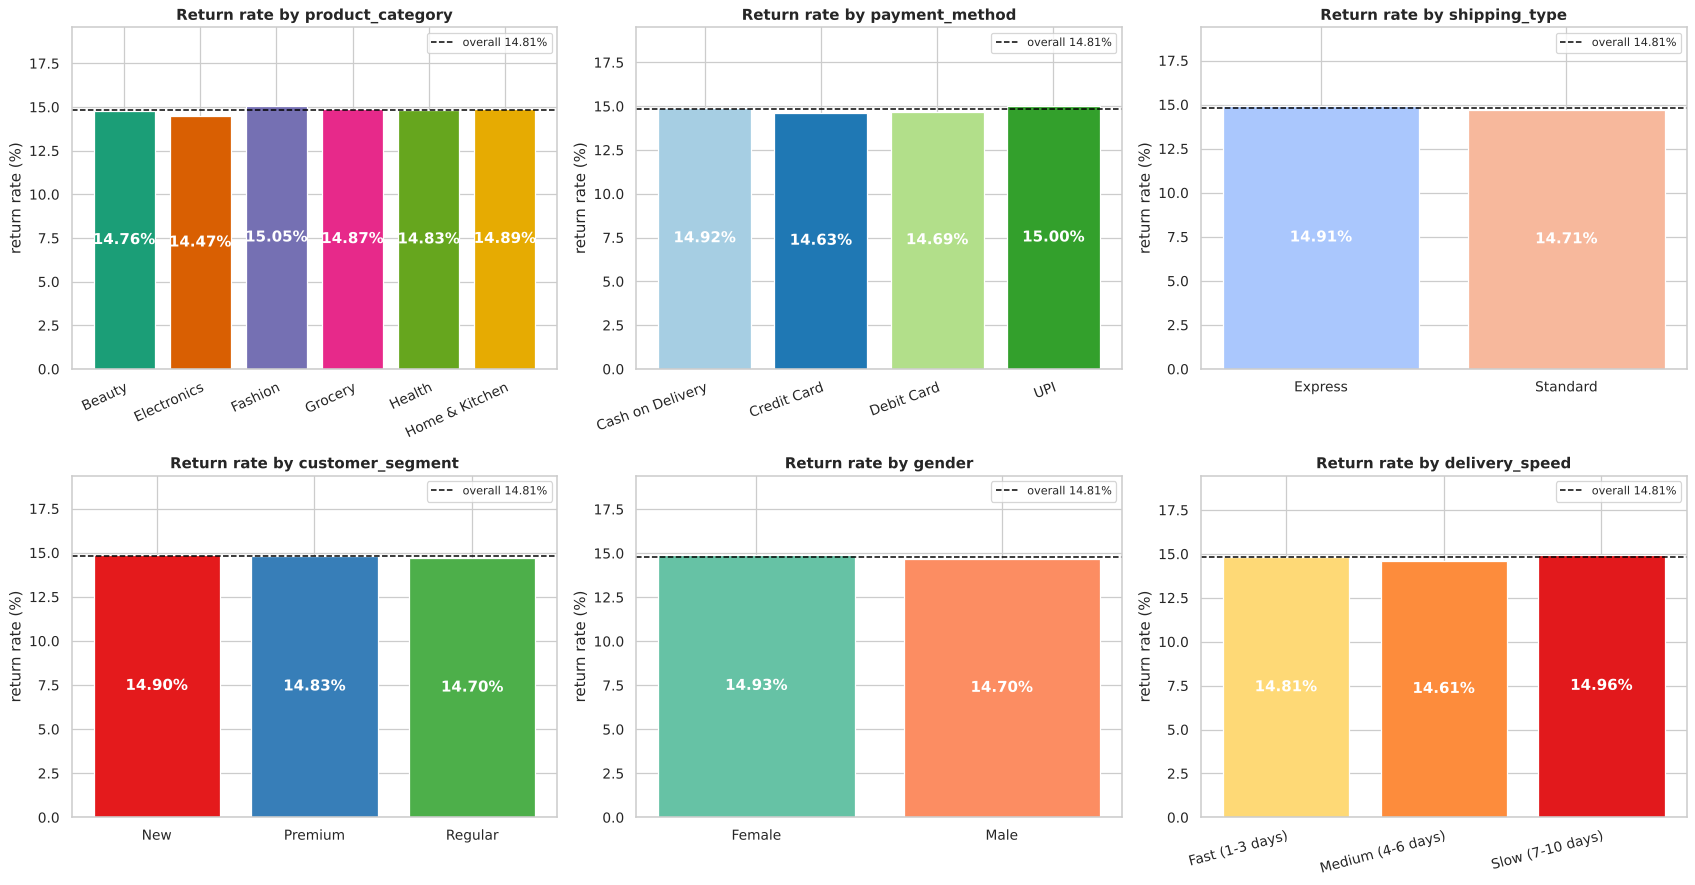

In [36]:
overall_rr = retail_data["is_return"].mean() * 100
panels = [("product_category", "Dark2", 25), ("payment_method", "Paired", 20), ("shipping_type", "coolwarm", 0),
          ("customer_segment", "Set1", 0), ("gender", "Set2", 0), ("delivery_speed", "YlOrRd", 15)]

fig, axes = plt.subplots(2, 3, figsize=(19, 10))
for ax, (c, pal, rot) in zip(axes.ravel(), panels):
    rr = retail_data.groupby(c, observed=True)["is_return"].mean() * 100
    bars = ax.bar(rr.index.astype(str), rr.values, color=sns.color_palette(pal, len(rr)), edgecolor="white")
    ax.bar_label(bars, fmt="%.2f%%", label_type="center", color="white", fontweight="bold")
    ax.axhline(overall_rr, color="black", ls="--", lw=1.2, label=f"overall {overall_rr:.2f}%")
    ax.set_ylim(0, rr.max() * 1.3)
    ax.set_ylabel("return rate (%)")
    ax.set_title(f"Return rate by {c}")
    ax.legend(loc="upper right", fontsize=9)
    ax.tick_params(axis="x", rotation=rot)
    if rot:
        plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
plt.tight_layout()
save_fig("09_return_rate_by_group")
plt.show()

### 9.2 Return-rate spread across every variable, compared with random noise

**Objective:** for each grouping variable, find the groups with the highest and lowest return rate. We also compute the approximate 95% margin of error for the smallest group, so we can tell whether a gap is larger than chance.

In [37]:
group_vars = ["product_category", "product_subcategory", "payment_method", "shipping_type", "customer_segment",
              "gender", "city", "state", "age_group", "discount_band", "delivery_speed", "delivery_days",
              "quantity", "order_year", "order_weekday"]
rows = []
for c in group_vars:
    g = retail_data.groupby(c, observed=True)["is_return"].agg(["mean", "size"])
    hi, lo = g["mean"].idxmax(), g["mean"].idxmin()
    p_small = g.loc[g["size"].idxmin(), "mean"]
    margin = 1.96 * np.sqrt(p_small * (1 - p_small) / g["size"].min()) * 100
    rows.append({"variable": c, "groups": len(g), "highest group": str(hi), "highest (%)": g.loc[hi, "mean"] * 100,
                 "lowest group": str(lo), "lowest (%)": g.loc[lo, "mean"] * 100,
                 "spread (pp)": (g["mean"].max() - g["mean"].min()) * 100,
                 "95% margin, smallest group (pp)": margin})
rr_spread = pd.DataFrame(rows).set_index("variable").sort_values("spread (pp)", ascending=False)
rr_spread

,groups,highest group,highest (%),lowest group,lowest (%),spread (pp),"95% margin, smallest group (pp)"
variable,,,,,,,
product_subcategory,21,Blender,15.91,Cookware,13.75,2.16,1.08
delivery_days,10,7,15.38,5,14.46,0.91,0.71
discount_band,6,26-30%,15.17,16-20%,14.39,0.78,0.55
city,10,Jaipur,15.14,Pune,14.48,0.66,0.71
state,9,Rajasthan,15.14,Maharashtra,14.54,0.60,0.71
product_category,6,Fashion,15.05,Electronics,14.47,0.58,0.54
order_year,3,2024,15.00,2023,14.46,0.54,0.39
quantity,4,2,15.03,1,14.51,0.52,0.44
order_weekday,7,Saturday,15.19,Thursday,14.69,0.50,0.59


### 9.3 Heatmaps: return rate and category composition

**Objective:** use crosstabs to see (left, middle) whether the return rate changes for particular combinations, and (right) whether customer segments are spread evenly across categories.

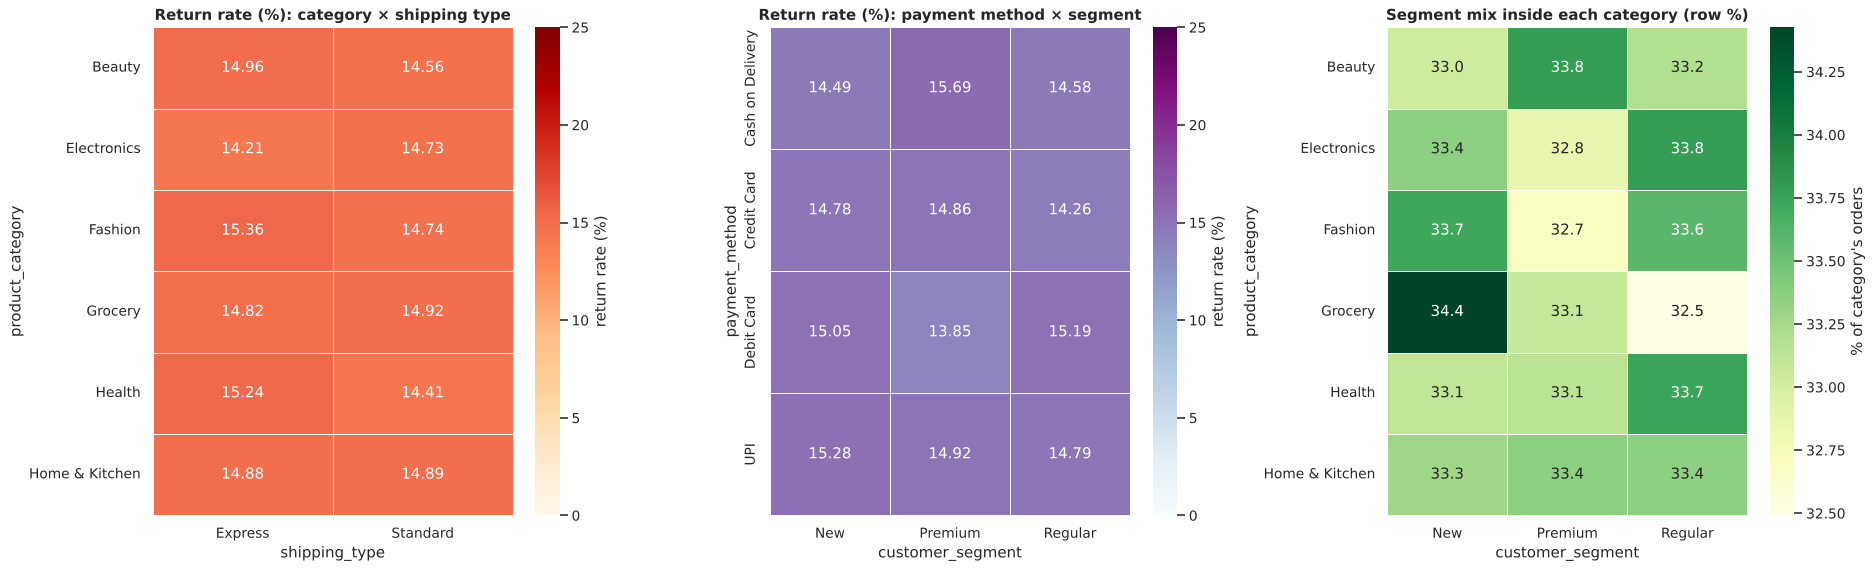

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))

pv = retail_data.pivot_table(index="product_category", columns="shipping_type", values="is_return", aggfunc="mean") * 100
sns.heatmap(pv, annot=True, fmt=".2f", cmap="OrRd", vmin=0, vmax=25, linewidths=0.5, cbar_kws={"label": "return rate (%)"}, ax=axes[0])
axes[0].set_title("Return rate (%): category × shipping type")

pv = retail_data.pivot_table(index="payment_method", columns="customer_segment", values="is_return", aggfunc="mean") * 100
sns.heatmap(pv, annot=True, fmt=".2f", cmap="BuPu", vmin=0, vmax=25, linewidths=0.5, cbar_kws={"label": "return rate (%)"}, ax=axes[1])
axes[1].set_title("Return rate (%): payment method × segment")

ct = pd.crosstab(retail_data["product_category"], retail_data["customer_segment"], normalize="index") * 100
sns.heatmap(ct, annot=True, fmt=".1f", cmap="YlGn", linewidths=0.5, cbar_kws={"label": "% of category's orders"}, ax=axes[2])
axes[2].set_title("Segment mix inside each category (row %)")
plt.tight_layout()
save_fig("09_categorical_heatmaps")
plt.show()

### 9.4 Stacked bars: returned vs kept orders

**Objective:** show the returned/kept split within each group as 100% stacked bars.

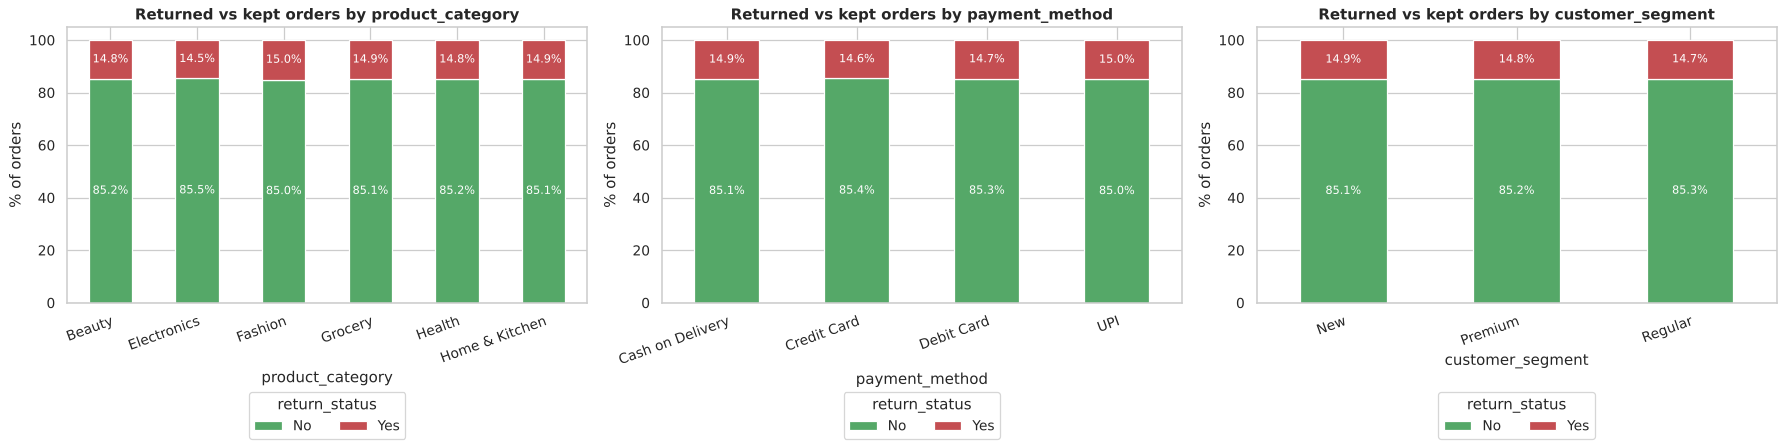

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, c in zip(axes, ["product_category", "payment_method", "customer_segment"]):
    ct = pd.crosstab(retail_data[c], retail_data["return_status"], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, color=["#55A868", "#C44E52"], edgecolor="white", ax=ax, rot=20)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.1f%%", label_type="center", color="white", fontsize=9)
    ax.set_ylabel("% of orders")
    ax.set_title(f"Returned vs kept orders by {c}")
    ax.legend(title="return_status", loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2)
    plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
plt.tight_layout()
save_fig("09_stacked_return_status")
plt.show()

### 9.5 Chi-square tests of independence

**Objective:** test whether two categorical variables are related. Cramér's V measures how strong the relationship is (0 = none, 1 = perfect). The first group of rows tests return status; the second group tests whether the other categorical variables depend on each other.

In [40]:
def chi_cramers(a, b):
    ct = pd.crosstab(retail_data[a], retail_data[b])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return {"variable A": a, "variable B": b, "chi-square": chi2, "dof": dof, "p-value": p, "Cramér's V": v}

pairs = [("return_status", x) for x in ["product_category", "payment_method", "shipping_type", "customer_segment",
                                        "gender", "city", "age_group", "discount_band", "delivery_speed", "delivery_days",
                                        "product_subcategory", "order_weekday", "order_year"]]
pairs += [("customer_segment", "product_category"), ("payment_method", "customer_segment"),
          ("shipping_type", "payment_method"), ("gender", "product_category"), ("city", "customer_segment")]

chi_table = pd.DataFrame([chi_cramers(*p) for p in pairs])
alpha_chi = 0.05 / len(pairs)
chi_table["strength"] = chi_table["Cramér's V"].apply(
    lambda v: "negligible" if v < 0.1 else "weak" if v < 0.3 else "moderate" if v < 0.5 else "strong")
chi_table["significant (p < 0.05)"] = chi_table["p-value"] < 0.05
chi_table[f"significant (Bonferroni, p < {alpha_chi:.4f})"] = chi_table["p-value"] < alpha_chi
chi_table["p-value"] = chi_table["p-value"].apply(lambda x: f"{x:.3g}")
chi_table["Cramér's V"] = chi_table["Cramér's V"].apply(lambda x: f"{x:.4f}")
chi_table

,variable A,variable B,chi-square,dof,p-value,Cramér's V,strength,significant (p < 0.05),"significant (Bonferroni, p < 0.0028)"
0,return_status,product_category,2.41,5,0.791,0.0049,negligible,False,False
1,return_status,payment_method,1.84,3,0.607,0.0043,negligible,False,False
2,return_status,shipping_type,0.79,1,0.375,0.0028,negligible,False,False
3,return_status,customer_segment,0.52,2,0.77,0.0023,negligible,False,False
4,return_status,gender,1.01,1,0.315,0.0032,negligible,False,False
5,return_status,city,3.50,9,0.941,0.0059,negligible,False,False
6,return_status,age_group,1.62,4,0.805,0.0040,negligible,False,False
7,return_status,discount_band,4.58,5,0.47,0.0068,negligible,False,False
8,return_status,delivery_speed,1.67,2,0.434,0.0041,negligible,False,False
9,return_status,delivery_days,5.40,9,0.798,0.0073,negligible,False,False


**Interpretation**

- **The return rate is flat across every group.** Overall it is 14.81%, and the group values stay within about half a percentage point of it: category 14.47% (Electronics) to 15.05% (Fashion), payment method 14.63% to 15.00%, segment 14.70% to 14.90%, gender 14.70% to 14.93%, delivery speed 14.61% to 14.96%. **Electronics actually has the lowest category return rate.** Standard shipping (14.71%) is not higher than Express (14.91%).
- **Subcategories show the widest spread (13.75% for Cookware to 15.91% for Blender), but this is what chance produces.** The "spread vs margin of error" table compares the highest and lowest of many groups, and the maximum and minimum of 21 noisy estimates are always far apart. The formal test confirms it (p = 0.24, Cramér's V = 0.016).
- **Heatmaps:** on a fair 0 to 25% colour scale, return rates look uniform across category × shipping type and payment method × segment (every cell between 13.9% and 15.7%). Customer segments make up about one third of every category (32.5% to 34.4%).
- **Chi-square tests:** all 13 tests with return status give p-values from 0.09 to 0.94, with Cramér's V of 0.016 or less ("negligible"). Returns are statistically independent of category, subcategory, payment, shipping, segment, gender, city, age group, discount band, delivery time, weekday and year.
- **The explanatory variables are also independent of each other** (segment × category, payment × segment, shipping × payment, gender × category). One test (city × segment) gave p = 0.045, but its Cramér's V is only 0.012, and it is not significant after the Bonferroni correction (threshold 0.0028). When 18 tests are run at the 5% level, about one false alarm is expected by chance, so this is most likely one of them.

## 10. Multivariate Analysis

**Objective:** study how three or more variables interact: pivot tables and heatmaps for the three interactions suggested in the brief (category × discount, segment × age, shipping × delivery days), plus a city × category view, a pairplot, a multicollinearity check (VIF) and a faceted view.

### 10.1 Product category × discount band × average final price

Smallest cell has 2,592 orders, so every cell average is based on plenty of data.


discount_band,0-5%,6-10%,11-15%,16-20%,21-25%,26-30%
product_category,,,,,,
Beauty,"72,928.03","70,167.36","65,128.20","61,099.10","57,873.82","55,350.26"
Electronics,"73,734.11","70,157.31","64,795.27","62,932.20","58,105.01","54,095.27"
Fashion,"73,241.59","68,451.89","65,939.57","61,594.01","58,830.69","53,934.66"
Grocery,"74,226.55","70,396.57","64,899.89","63,499.65","57,205.43","52,725.88"
Health,"73,364.02","68,189.75","65,048.99","62,256.25","56,621.52","54,706.65"
Home & Kitchen,"74,501.63","71,391.38","66,689.84","62,319.42","58,328.25","54,035.75"


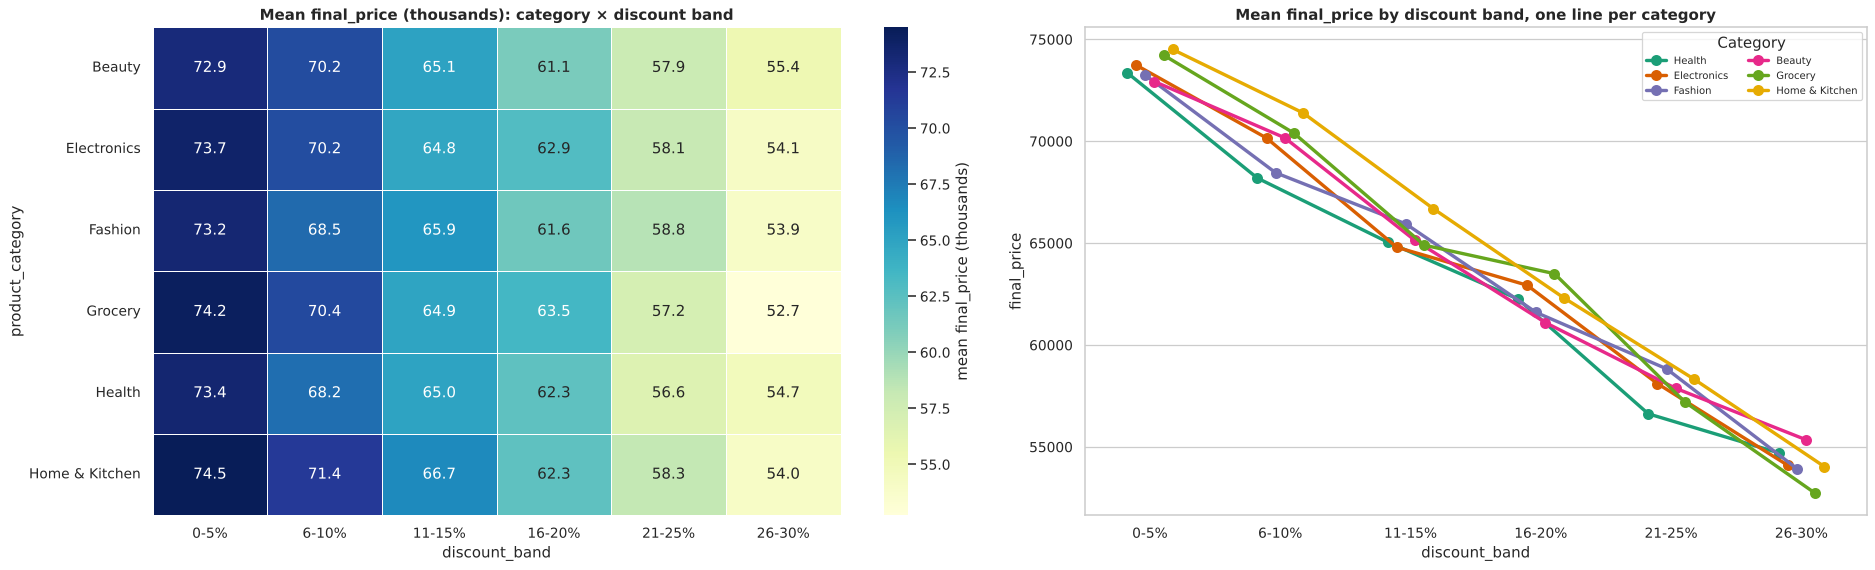

In [41]:
piv1 = retail_data.pivot_table(index="product_category", columns="discount_band", values="final_price",
                      aggfunc="mean", observed=True)
cell_min = retail_data.pivot_table(index="product_category", columns="discount_band", values="final_price",
                          aggfunc="size", observed=True).min().min()
print(f"Smallest cell has {cell_min:,} orders, so every cell average is based on plenty of data.")
display(piv1)

fig, axes = plt.subplots(1, 2, figsize=(21, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(piv1 / 1000, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5,
            cbar_kws={"label": "mean final_price (thousands)"}, ax=axes[0])
axes[0].set_title("Mean final_price (thousands): category × discount band")
sns.pointplot(data=retail_data, x="discount_band", y="final_price", hue="product_category", palette="Dark2",
              errorbar=None, dodge=0.35, markers="o", ax=axes[1])
axes[1].set_title("Mean final_price by discount band, one line per category")
axes[1].legend(title="Category", fontsize=8, ncol=2)
plt.tight_layout()
save_fig("10_category_discount_price")
plt.show()

### 10.2 Customer segment × age group × average spending

age_group,18-25,26-35,36-45,46-55,56-65
customer_segment,,,,,
New,"63,588.34","64,164.81","63,878.65","63,512.56","63,659.29"
Premium,"64,025.80","65,281.87","64,033.64","65,432.07","63,294.74"
Regular,"64,097.15","64,359.16","64,103.87","64,294.84","64,616.06"


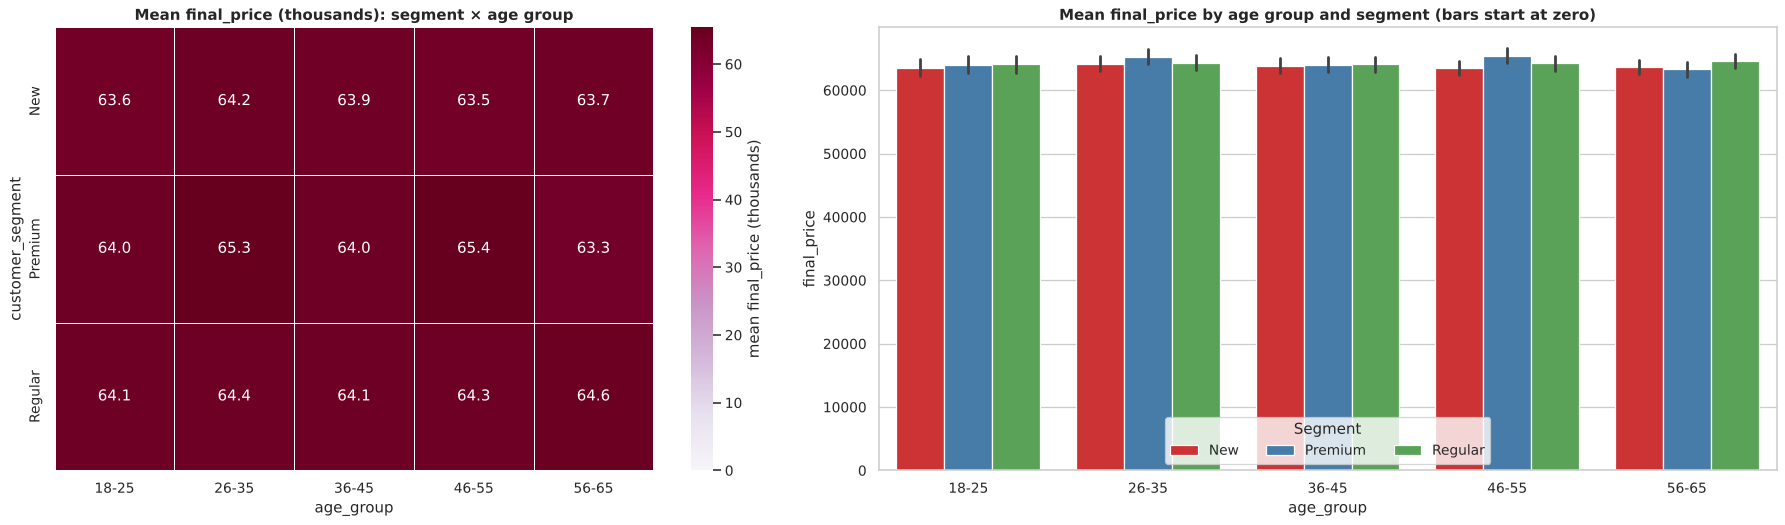

In [42]:
piv2 = retail_data.pivot_table(index="customer_segment", columns="age_group", values="final_price",
                      aggfunc="mean", observed=True)
display(piv2)

fig, axes = plt.subplots(1, 2, figsize=(20, 6), gridspec_kw={"width_ratios": [1, 1.2]})
sns.heatmap(piv2 / 1000, annot=True, fmt=".1f", cmap="PuRd", vmin=0, linewidths=0.5,
            cbar_kws={"label": "mean final_price (thousands)"}, ax=axes[0])
axes[0].set_title("Mean final_price (thousands): segment × age group")
sns.barplot(data=retail_data, x="age_group", y="final_price", hue="customer_segment", palette="Set1",
            errorbar=("se", 1.96), ax=axes[1])
axes[1].set_title("Mean final_price by age group and segment (bars start at zero)")
axes[1].legend(title="Segment", ncol=3, loc="lower center")
plt.tight_layout()
save_fig("10_segment_age_spending")
plt.show()

### 10.3 Shipping type × delivery days × return rate

delivery_days,1,2,3,4,5,6,7,8,9,10
shipping_type,,,,,,,,,,
Express,14.74,14.57,15.21,14.58,15.09,14.37,16.21,14.76,14.76,14.82
Standard,15.21,14.80,14.30,14.89,13.83,14.92,14.53,15.28,15.17,14.18


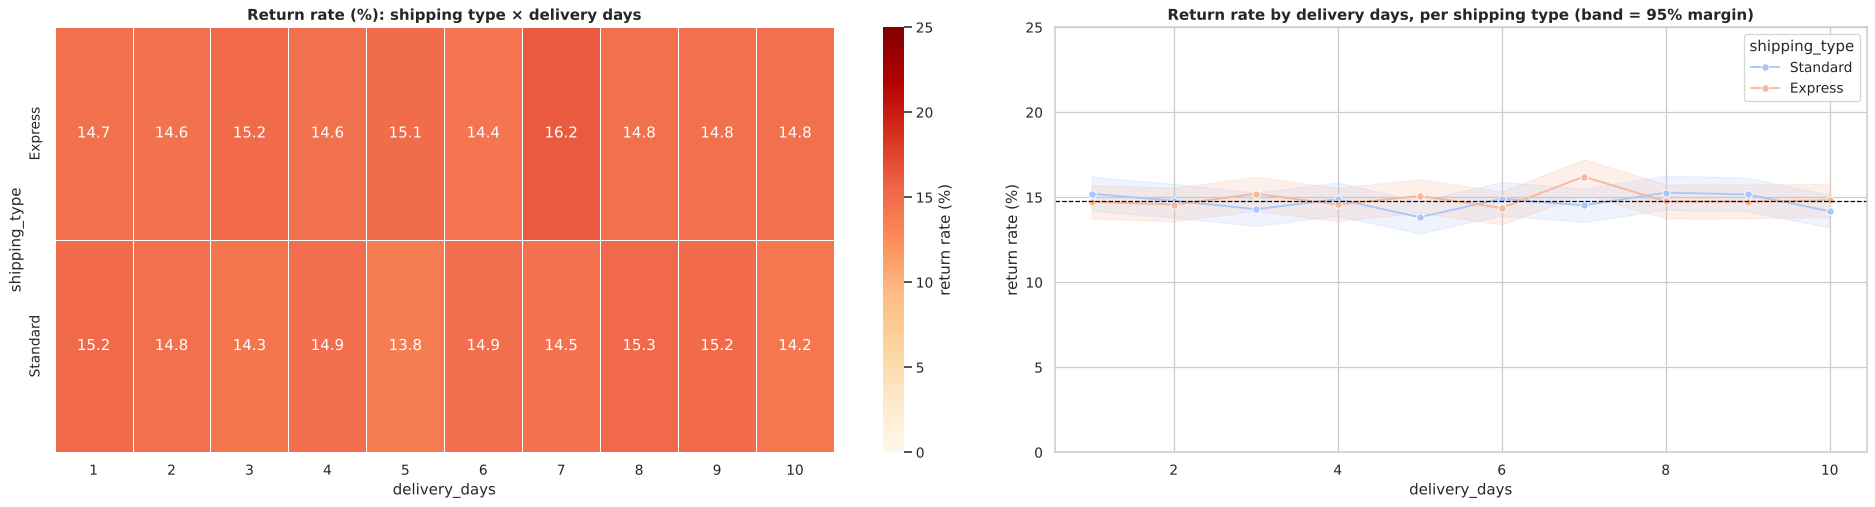

In [43]:
piv3 = retail_data.pivot_table(index="shipping_type", columns="delivery_days", values="is_return", aggfunc="mean") * 100
display(piv3.round(2))

fig, axes = plt.subplots(1, 2, figsize=(21, 5.8), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(piv3, annot=True, fmt=".1f", cmap="OrRd", vmin=0, vmax=25, linewidths=0.5,
            cbar_kws={"label": "return rate (%)"}, ax=axes[0])
axes[0].set_title("Return rate (%): shipping type × delivery days")
sns.lineplot(data=retail_plot_data, x="delivery_days", y="return_pct", hue="shipping_type", palette="coolwarm",
             marker="o", errorbar=("se", 1.96), ax=axes[1])
axes[1].axhline(overall_rr, color="black", ls="--", lw=1)
axes[1].set_ylim(0, 25)
axes[1].set_ylabel("return rate (%)")
axes[1].set_title("Return rate by delivery days, per shipping type (band = 95% margin)")
plt.tight_layout()
save_fig("10_shipping_delivery_return")
plt.show()

**Interpretation**

- **Category × discount × final price.** In every category, the average order value falls steadily as the discount band rises: from about 73,000 to 74,500 at 0-5% down to about 52,700 to 55,400 at 26-30%, a drop of roughly 26%. Differences *between* categories inside the same band are small (a few thousand at most). The highest cell is Home & Kitchen at 0-5% (74,502), and Electronics with a moderate discount (11-15%) is an ordinary 64,795. **There is no moderate-discount sweet spot: order value is highest where discounts are lowest.** The reason is simple: discounts cut the price paid directly, and customers do not buy more when the discount is larger (shown in section 11.5).
- **Segment × age group × spending.** The nine averages lie between 63,295 (Premium, 56-65) and 65,432 (Premium, 46-55), within about ±2% of the overall mean. Premium customers are highest in the 46-55 and 26-35 groups, but the 36-45 Premium group (64,034) is not special, and the error bars overlap everywhere. There is no meaningful segment × age interaction.
- **Shipping type × delivery days × return rate.** The 20 cells range from 13.8% (Standard, 5 days) to 16.2% (Express, 7 days), around the overall 14.8%, with no trend as delivery time grows. Both lines zigzag inside their margin-of-error bands. Longer delivery on Standard shipping does not raise return probability here.

### 10.4 City × product category: where does the revenue come from?

**Objective:** a heatmap of total revenue (in millions) for every city and category pair.

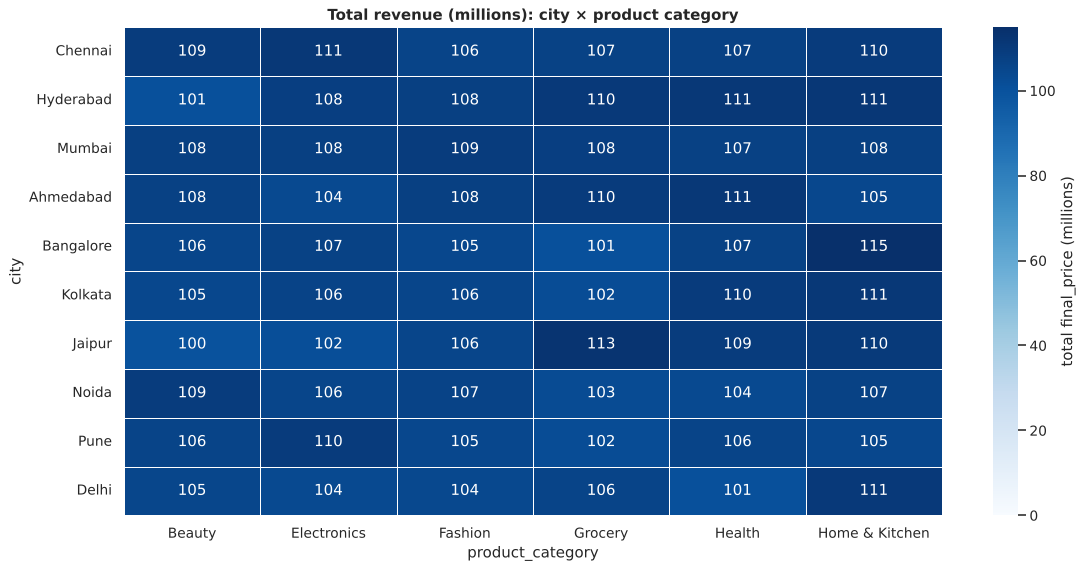

product_category,Beauty,Electronics,Fashion,Grocery,Health,Home & Kitchen,Total
city,,,,,,,
Chennai,109.10,111.10,106.00,107.20,107.40,109.90,650.60
Hyderabad,100.80,108.50,108.00,110.50,111.30,111.40,650.40
Mumbai,107.90,108.00,109.40,108.30,107.30,107.90,648.80
Ahmedabad,107.70,103.80,107.80,109.60,111.00,104.80,644.70
Bangalore,105.80,107.20,104.80,100.90,107.20,114.90,641.00
Kolkata,105.00,106.50,105.60,102.40,109.50,110.90,640.00
Jaipur,99.90,101.90,105.70,112.70,109.20,110.20,639.70
Noida,109.40,105.60,106.70,103.20,103.90,107.00,635.90
Pune,106.10,109.90,104.80,102.40,106.10,104.80,634.20


In [44]:
piv4 = retail_data.pivot_table(index="city", columns="product_category", values="final_price", aggfunc="sum") / 1e6
piv4["Total"] = piv4.sum(axis=1)
piv4 = piv4.sort_values("Total", ascending=False)

fig, ax = plt.subplots(figsize=(13, 6.5))
sns.heatmap(piv4.drop(columns="Total"), annot=True, fmt=".0f", cmap="Blues", vmin=0, linewidths=0.5,
            cbar_kws={"label": "total final_price (millions)"}, ax=ax)
ax.set_title("Total revenue (millions): city × product category")
plt.tight_layout()
save_fig("10_city_category_revenue")
plt.show()
display(piv4.round(1))

### 10.5 Pairplot of the numerical variables, coloured by customer segment

**Objective:** view all pairwise relationships at once, with `hue` showing whether the three customer segments behave differently. A random sample of 2,500 orders is used so the plot stays readable.

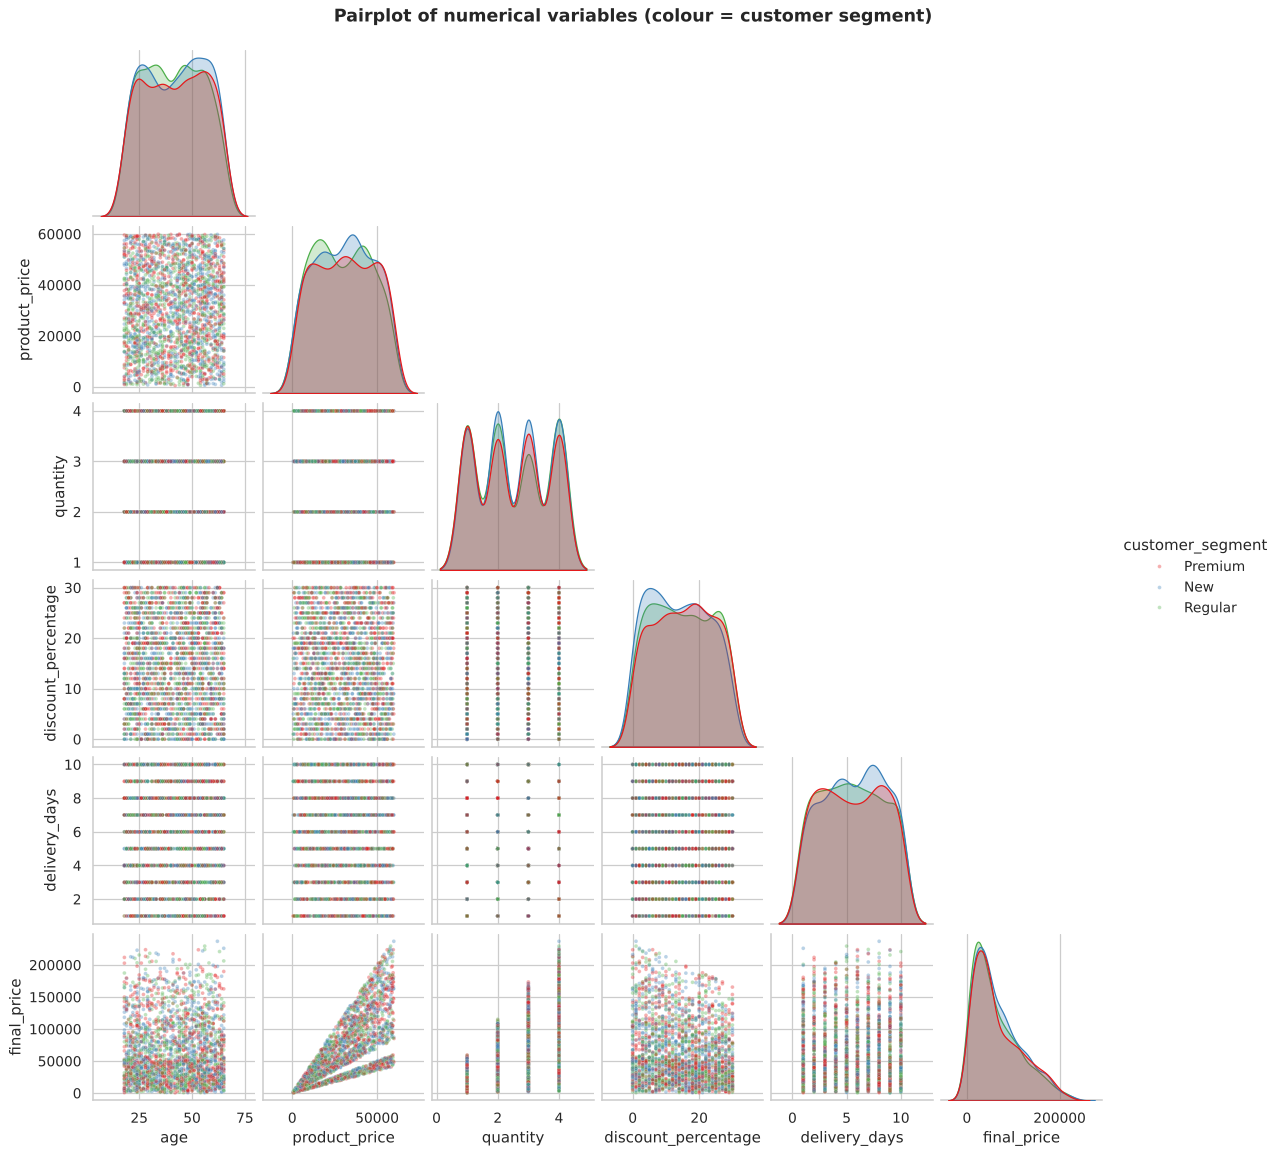

In [45]:
pp_cols = ["age", "product_price", "quantity", "discount_percentage", "delivery_days", "final_price"]
g = sns.pairplot(retail_data.sample(2500, random_state=7), vars=pp_cols, hue="customer_segment", palette="Set1",
                 corner=True, diag_kind="kde", plot_kws=dict(alpha=0.35, s=9), height=2.1)
g.figure.suptitle("Pairplot of numerical variables (colour = customer segment)", y=1.02, fontsize=14, fontweight="bold")
save_fig("10_pairplot")
plt.show()

### 10.6 Multicollinearity check (VIF)

**Objective:** VIF (Variance Inflation Factor) shows whether the input features carry overlapping information. Values near 1 mean independent; above 5 to 10 is a warning. `final_price` is *calculated* from price, quantity and discount, so it is not an independent feature. We show VIF both without it and with it added.

In [46]:
def vif(cols):
    X = retail_data[cols].astype(float).to_numpy()
    return pd.Series(np.diag(np.linalg.inv(np.corrcoef(X, rowvar=False))), index=cols)

indep = ["age", "product_price", "quantity", "discount_percentage", "delivery_days"]
vif_a = vif(indep)
vif_b = vif(indep + ["final_price"])
vif_table = pd.DataFrame({"VIF: independent features only": vif_a,
                          "VIF: with final_price added": vif_b}).reindex(indep + ["final_price"])
vif_table

,VIF: independent features only,VIF: with final_price added
age,1.00,1.00
product_price,1.00,5.51
quantity,1.00,3.79
discount_percentage,1.00,1.15
delivery_days,1.00,1.00
final_price,NaN,8.47


### 10.7 Faceted view: age group × gender × customer segment

**Objective:** use a `catplot` grid (one panel per segment) to check three variables at once.

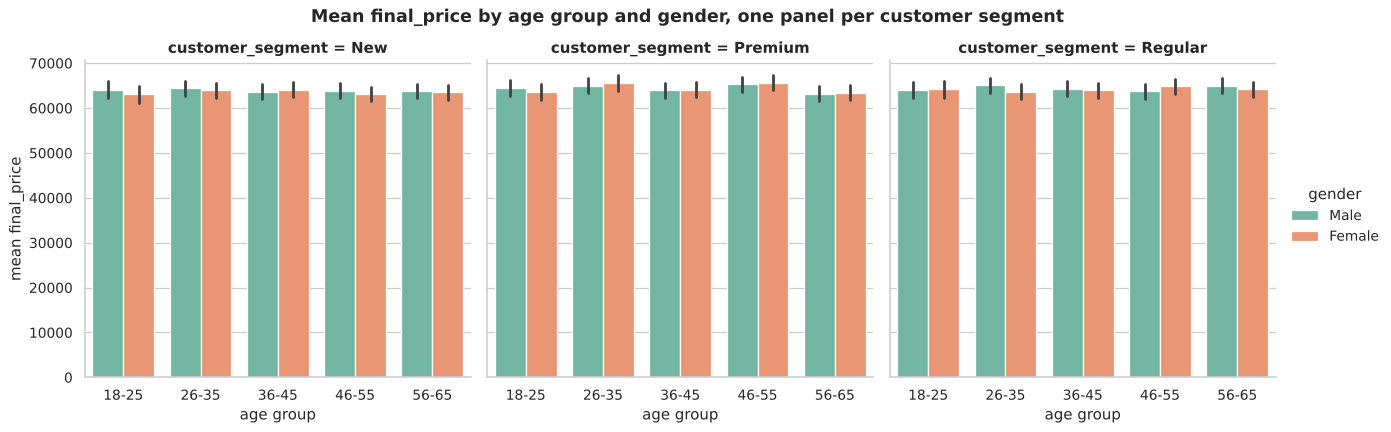

In [47]:
g = sns.catplot(data=retail_data, x="age_group", y="final_price", hue="gender", col="customer_segment", kind="bar",
                palette="Set2", errorbar=("se", 1.96), height=4.6, aspect=1.05)
g.figure.suptitle("Mean final_price by age group and gender, one panel per customer segment",
                  y=1.04, fontsize=14, fontweight="bold")
g.set_axis_labels("age group", "mean final_price")
save_fig("10_facet_age_gender_segment")
plt.show()

**Interpretation**

- **City × category revenue.** All 60 cells fall between about 100 and 115 million, and city totals range only from 631 million (Delhi) to 651 million (Chennai). There is no city that specialises in a category.
- **Pairplot.** The scatter plots between age, price, quantity, discount and delivery days are even grids of points with no pattern. The only structure appears in the `final_price` row, where it rises with price and quantity and falls with discount (the formula again). The density curves of the three customer segments overlap almost perfectly on every variable, so the segments do not behave differently.
- **Multicollinearity (VIF).** The five independent features each have a VIF of **1.00**, meaning they carry no overlapping information. When `final_price` is added, VIF rises to 5.51 for `product_price`, 3.79 for `quantity` and 8.47 for `final_price` itself, because it is calculated from them. So the independent features have no multicollinearity problem, but `final_price` should never be used together with its own ingredients as an input to a model.
- **Faceted view.** Across the three segment panels, bars for every age group and gender reach about the same height (around 64,000), so there is no three-way interaction between age, gender and segment.

## 11. Extra Analysis Beyond the Assignment

**Objective:** the brief only suggests a few comparisons. Here we explore four more business questions the data can answer: How do sales change over time? Which cities and states matter most? Which products drive revenue and returns? Do discounts actually change what customers buy?

### 11.1 Time trends: orders, revenue and returns

Yearly summary


,orders,revenue (millions),avg_order_value,return rate (%)
order_year,,,,
2023,33513,"2,140.49","63,870.29",14.46
2024,33547,"2,155.13","64,242.11",15.00
2025,32940,"2,120.96","64,388.50",14.98



Trend in average daily revenue: change = -0.0022 million per month elapsed (-0.04% of the average level), p = 0.451
Orders in line with the number of days in each weekday?  chi-square p = 0.049
Orders in line with the number of days in each month?    chi-square p = 0.000


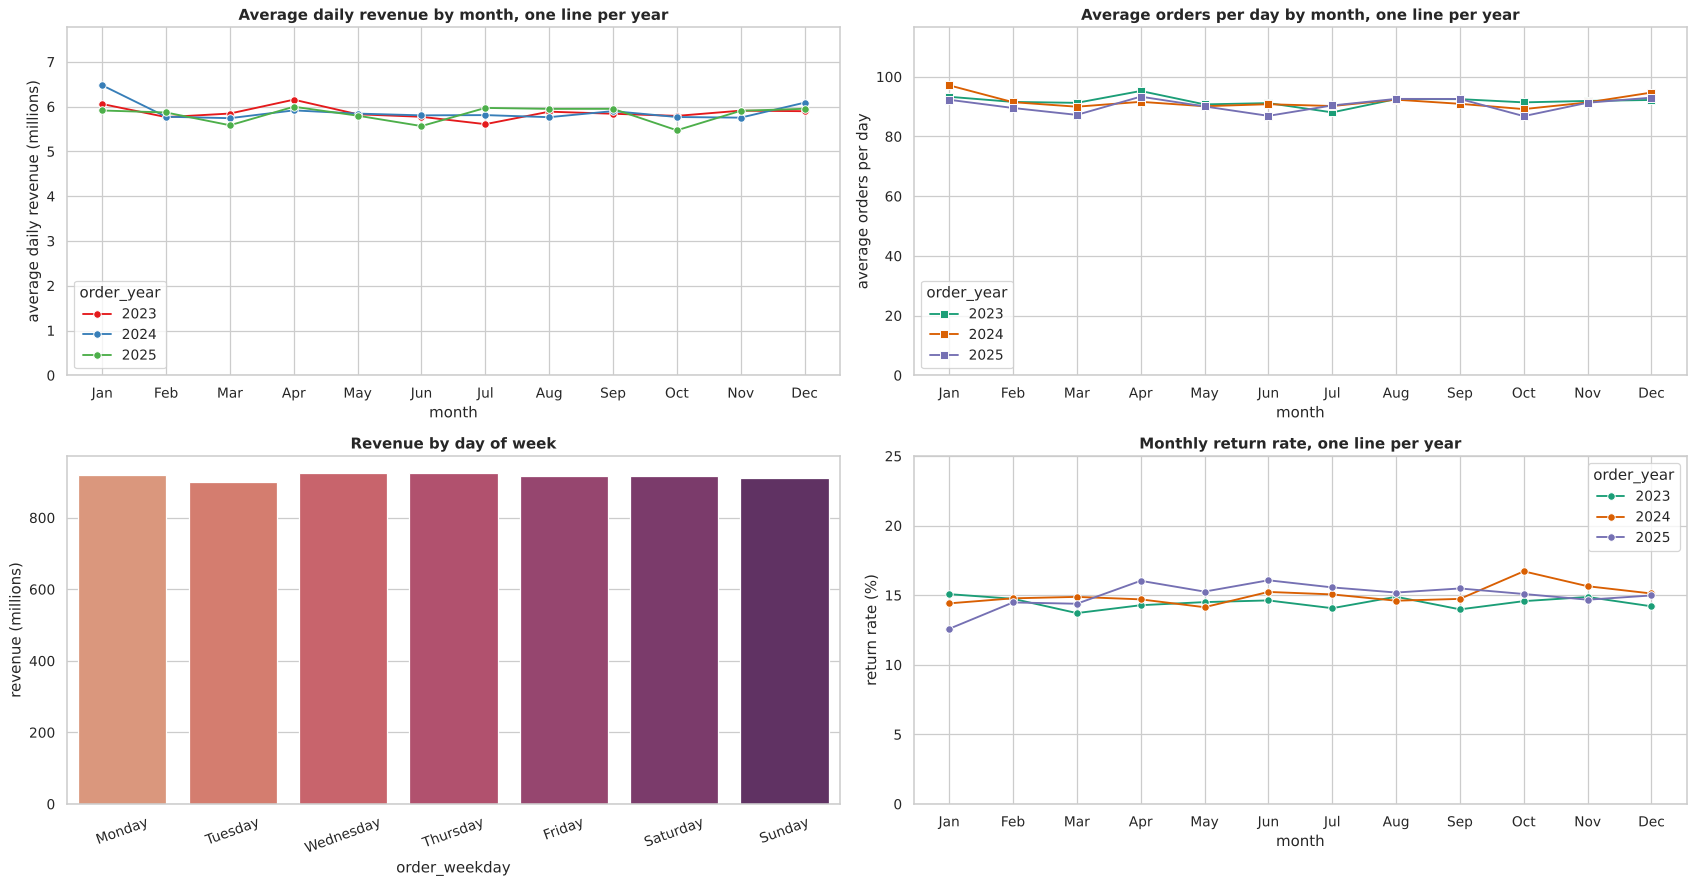

In [48]:
month_abbr = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

monthly = (retail_data.groupby(["order_year", "order_month"])
             .agg(revenue=("final_price", "sum"), orders=("order_id", "count"),
                  avg_order_value=("final_price", "mean"), return_rate=("is_return", "mean"))
             .reset_index())
monthly["revenue_m"] = monthly["revenue"] / 1e6
monthly["return_rate"] *= 100

# Months have different lengths, so compare AVERAGE PER DAY rather than monthly totals
all_days = pd.Series(pd.date_range(retail_data["order_date"].min(), retail_data["order_date"].max()))
day_counts = all_days.groupby([all_days.dt.year, all_days.dt.month]).size()
monthly["days"] = [day_counts[(y, m)] for y, m in zip(monthly["order_year"], monthly["order_month"])]
monthly["revenue_per_day_m"] = monthly["revenue_m"] / monthly["days"]
monthly["orders_per_day"] = monthly["orders"] / monthly["days"]

yearly = retail_data.groupby("order_year").agg(orders=("order_id", "count"), revenue=("final_price", "sum"),
                                      avg_order_value=("final_price", "mean"),
                                      return_rate=("is_return", "mean"))
yearly["return_rate"] *= 100
yearly["revenue"] = yearly["revenue"] / 1e6
yearly = yearly.rename(columns={"revenue": "revenue (millions)", "return_rate": "return rate (%)"})
print("Yearly summary")
display(yearly)

# Is there a real trend or seasonality? (formal checks)
ordered = monthly.sort_values(["order_year", "order_month"]).reset_index(drop=True)
lr = stats.linregress(np.arange(len(ordered)), ordered["revenue_per_day_m"])
print(f"\nTrend in average daily revenue: change = {lr.slope:+.4f} million per month elapsed "
      f"({lr.slope / ordered['revenue_per_day_m'].mean():.2%} of the average level), p = {lr.pvalue:.3f}")
# Expected orders if volume were constant per calendar day (months/weekdays have different numbers of days)
wd_counts = retail_data["order_weekday"].value_counts().reindex(weekday_order)
mo_counts = retail_data["order_month"].value_counts().sort_index()
wd_expected = all_days.dt.day_name().value_counts().reindex(weekday_order)
mo_expected = all_days.dt.month.value_counts().sort_index()
wd_expected = wd_expected / wd_expected.sum() * len(retail_data)
mo_expected = mo_expected / mo_expected.sum() * len(retail_data)
print(f"Orders in line with the number of days in each weekday?  chi-square p = {stats.chisquare(wd_counts, wd_expected).pvalue:.3f}")
print(f"Orders in line with the number of days in each month?    chi-square p = {stats.chisquare(mo_counts, mo_expected).pvalue:.3f}")

fig, axes = plt.subplots(2, 2, figsize=(19, 10))
sns.lineplot(data=monthly, x="order_month", y="revenue_per_day_m", hue="order_year", palette="Set1",
             marker="o", ax=axes[0, 0])
axes[0, 0].set_ylim(0, monthly["revenue_per_day_m"].max() * 1.2)
axes[0, 0].set_ylabel("average daily revenue (millions)")
axes[0, 0].set_title("Average daily revenue by month, one line per year")
sns.lineplot(data=monthly, x="order_month", y="orders_per_day", hue="order_year", palette="Dark2",
             marker="s", ax=axes[0, 1])
axes[0, 1].set_ylim(0, monthly["orders_per_day"].max() * 1.2)
axes[0, 1].set_ylabel("average orders per day")
axes[0, 1].set_title("Average orders per day by month, one line per year")
wd = retail_data.groupby("order_weekday")["final_price"].sum().reindex(weekday_order) / 1e6
sns.barplot(x=wd.index, y=wd.values, hue=wd.index, palette="flare", legend=False, ax=axes[1, 0])
axes[1, 0].set_ylabel("revenue (millions)")
axes[1, 0].set_title("Revenue by day of week")
axes[1, 0].tick_params(axis="x", rotation=20)
sns.lineplot(data=monthly, x="order_month", y="return_rate", hue="order_year", palette="Dark2",
             marker="o", ax=axes[1, 1])
axes[1, 1].set_ylim(0, 25)
axes[1, 1].set_ylabel("return rate (%)")
axes[1, 1].set_title("Monthly return rate, one line per year")
for ax in (axes[0, 0], axes[0, 1], axes[1, 1]):
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_abbr)
    ax.set_xlabel("month")
plt.tight_layout()
save_fig("11_time_trends")
plt.show()

### 11.2 Seasonality heatmap and quarterly view

**Objective:** see whether any month is consistently stronger across the three years (average daily revenue removes the effect of months having different lengths).

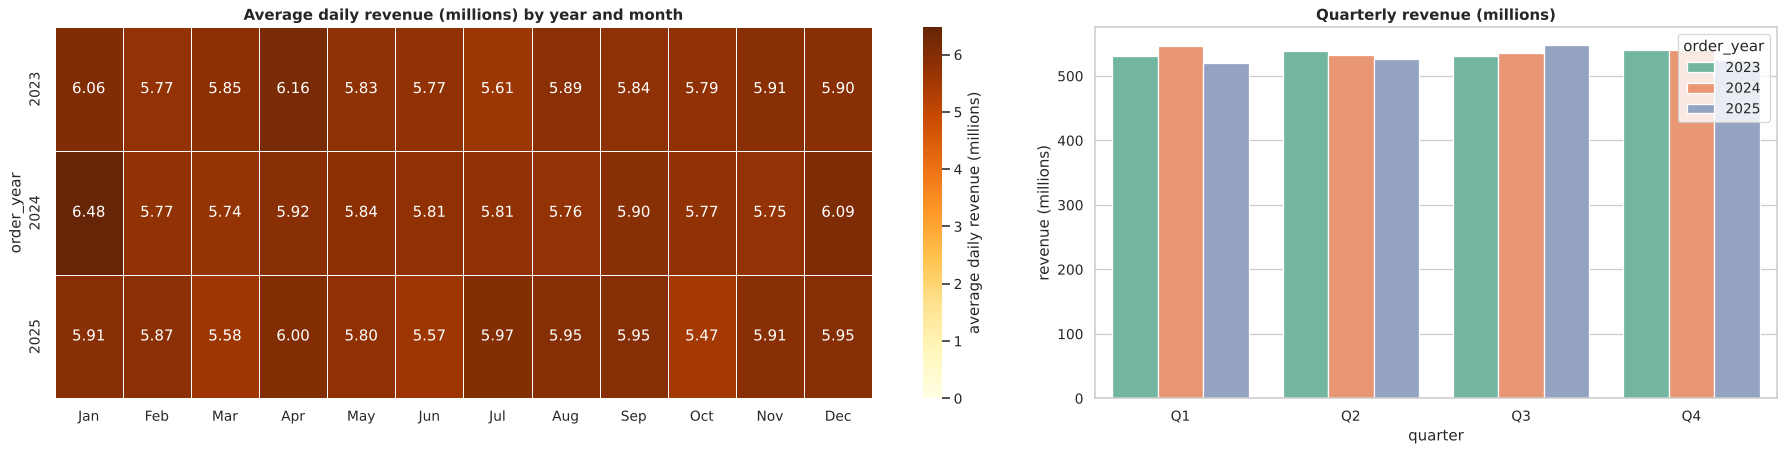

In [49]:
piv_t = monthly.pivot(index="order_year", columns="order_month", values="revenue_per_day_m")
piv_t.columns = month_abbr

fig, axes = plt.subplots(1, 2, figsize=(20, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(piv_t, annot=True, fmt=".2f", cmap="YlOrBr", vmin=0, linewidths=0.5,
            cbar_kws={"label": "average daily revenue (millions)"}, ax=axes[0])
axes[0].set_title("Average daily revenue (millions) by year and month")
q = retail_data.groupby(["order_year", "order_quarter"])["final_price"].sum().reset_index()
q["revenue_m"] = q["final_price"] / 1e6
sns.barplot(data=q, x="order_quarter", y="revenue_m", hue="order_year", palette="Set2", ax=axes[1])
axes[1].set_xticklabels(["Q1", "Q2", "Q3", "Q4"])
axes[1].set_xlabel("quarter")
axes[1].set_ylabel("revenue (millions)")
axes[1].set_title("Quarterly revenue (millions)")
plt.tight_layout()
save_fig("11_seasonality")
plt.show()

**Interpretation**

- **Volume and value are stable across the three years.** Orders were 33,513 (2023), 33,547 (2024) and 32,940 (2025); net revenue was 2,140 million, 2,155 million and 2,121 million; average order value moved only from 63,870 to 64,389; and the return rate was 14.5%, 15.0% and 15.0%. 2025 is about 1.6% lower in revenue than 2024, a small dip.
- **No growth or decline trend.** Average daily revenue changes by about −0.04% per month, which is not significant (p = 0.45).
- **No strong seasonality.** Once months are compared per day (so shorter months are not penalised), daily revenue stays around 5.5 to 6 million and daily orders between about 87 and 97 in every month and year. January and December look slightly busier in the line chart, but the gaps are only a few percent and do not repeat consistently. With 100,000 orders the month test can detect even these small gaps (p < 0.001), but at a few percent they are too small to matter for planning.
- **Weekdays are flat**: revenue is roughly 900 to 925 million on every day of the week (the weekday test is borderline, p = 0.049, with differences far too small to act on).
- **The monthly return rate** moves between about 12.6% and 16.7%, which is the normal noise for roughly 2,800 orders per month, with no upward or downward drift.

### 11.3 Geography: cities and states

**Objective:** compare orders, revenue, average order value and return rate across the 10 cities and 9 states.

By city


,orders,revenue (millions),avg_order_value,median_order_value,return rate (%),revenue share (%)
city,,,,,,
Chennai,9993,650.62,"65,107.98","50,638.80",15.12,10.14
Hyderabad,10150,650.43,"64,081.53","49,658.28",14.66,10.14
Mumbai,10015,648.85,"64,787.77","50,402.88",14.60,10.11
Ahmedabad,10057,644.68,"64,102.31","49,816.20",14.79,10.05
Bangalore,10047,640.95,"63,795.19","49,212.90",14.91,9.99
Kolkata,9955,639.98,"64,286.89","49,872.00",14.84,9.97
Jaipur,9920,639.65,"64,481.22","49,277.34",15.14,9.97
Noida,9964,635.89,"63,818.44","49,446.29",14.63,9.91
Pune,9937,634.23,"63,824.77","49,323.00",14.48,9.88



By state


,orders,revenue (millions),avg_order_value,median_order_value,return rate (%),revenue share (%)
state,,,,,,
Maharashtra,19952,"1,283.08","64,308.15","49,961.43",14.54,20.00
Tamil Nadu,9993,650.62,"65,107.98","50,638.80",15.12,10.14
Telangana,10150,650.43,"64,081.53","49,658.28",14.66,10.14
Gujarat,10057,644.68,"64,102.31","49,816.20",14.79,10.05
Karnataka,10047,640.95,"63,795.19","49,212.90",14.91,9.99
West Bengal,9955,639.98,"64,286.89","49,872.00",14.84,9.97
Rajasthan,9920,639.65,"64,481.22","49,277.34",15.14,9.97
Uttar Pradesh,9964,635.89,"63,818.44","49,446.29",14.63,9.91
Delhi,9962,631.30,"63,370.88","49,609.39",14.95,9.84


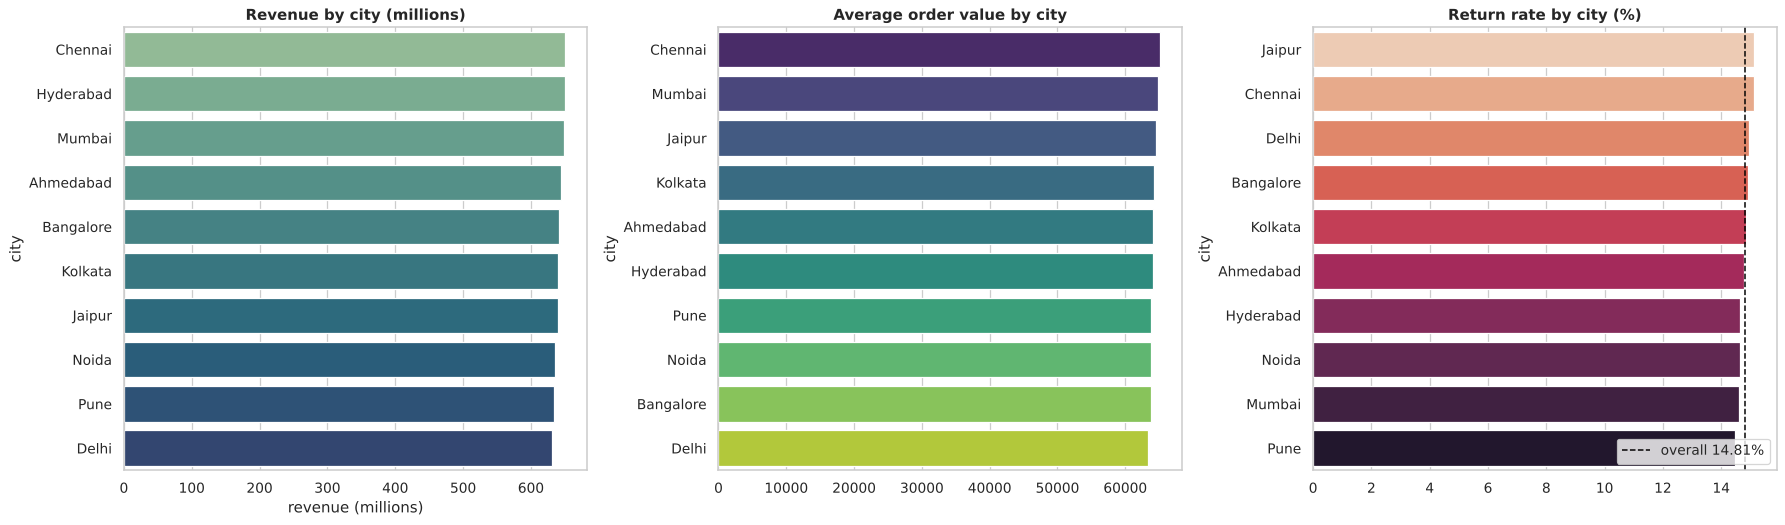

In [50]:
def geo_table(by):
    g = retail_data.groupby(by).agg(orders=("order_id", "count"), revenue=("final_price", "sum"),
                           avg_order_value=("final_price", "mean"),
                           median_order_value=("final_price", "median"),
                           return_rate=("is_return", "mean"))
    g["revenue share (%)"] = g["revenue"] / g["revenue"].sum() * 100
    g["return_rate"] *= 100
    g["revenue"] = g["revenue"] / 1e6
    return g.rename(columns={"revenue": "revenue (millions)", "return_rate": "return rate (%)"}).sort_values(
        "revenue (millions)", ascending=False)

geo_city, geo_state = geo_table("city"), geo_table("state")
print("By city")
display(geo_city)
print("\nBy state")
display(geo_state)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.barplot(x=geo_city["revenue (millions)"], y=geo_city.index, hue=geo_city.index, palette="crest", legend=False, ax=axes[0])
axes[0].set_title("Revenue by city (millions)")
aov = geo_city["avg_order_value"].sort_values(ascending=False)
sns.barplot(x=aov.values, y=aov.index, hue=aov.index, palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("Average order value by city")
rr = geo_city["return rate (%)"].sort_values(ascending=False)
sns.barplot(x=rr.values, y=rr.index, hue=rr.index, palette="rocket_r", legend=False, ax=axes[2])
axes[2].axvline(overall_rr, color="black", ls="--", lw=1.2, label=f"overall {overall_rr:.2f}%")
axes[2].legend(loc="lower right")
axes[2].set_title("Return rate by city (%)")
plt.tight_layout()
save_fig("11_geography")
plt.show()

**Interpretation**

- **Every city contributes almost exactly one tenth of revenue.** City revenue ranges only from 631 million (Delhi, 9.84%) to 651 million (Chennai, 10.14%). Average order value ranges from 63,371 (Delhi) to 65,108 (Chennai), about ±1.4% around the overall average, and the return rate from 14.48% (Pune) to 15.14% (Jaipur). The earlier tests (ANOVA p = 0.38 for spend; chi-square p = 0.94 for returns) confirm these are chance differences.
- **Maharashtra leads by state with 1,283 million (20%)** only because it combines Mumbai and Pune. Per city, it matches the others.
- Conclusion: no city or state stands out for volume, value or returns, so there is no data-based reason to treat locations differently.

### 11.4 Products: subcategory revenue, returns and price

**Objective:** find the products that generate the most revenue and the most returns, and check whether prices differ between product categories (a real-world shop would expect laptops to cost more than snacks).

,product_category,product_subcategory,orders,revenue (millions),avg_unit_price,avg_order_value,return rate (%)
0,Health,Supplements,5657,359.90,"29,992.65","63,619.56",15.08
1,Health,Protein Powder,5668,359.82,"30,003.13","63,483.56",14.54
2,Grocery,Organic Rice,5567,357.44,"30,370.81","64,206.87",14.46
3,Beauty,Shampoo,5578,356.82,"30,217.22","63,968.36",15.24
4,Beauty,Face Cream,5512,354.04,"29,763.88","64,230.18",13.79
5,Health,Vitamins,5533,353.91,"30,424.21","63,963.41",14.87
6,Grocery,Snacks,5548,353.34,"29,825.04","63,687.24",15.23
7,Grocery,Pulses,5477,352.80,"30,118.82","64,414.96",14.92
8,Beauty,Perfume,5423,346.48,"30,193.68","63,891.61",15.25
9,Electronics,Headphones,4265,277.74,"31,102.62","65,119.87",14.28


Do unit prices differ between product categories?  ANOVA F = 1.75, p = 0.120
Average unit price range across the 21 subcategories: 29,764 to 31,103


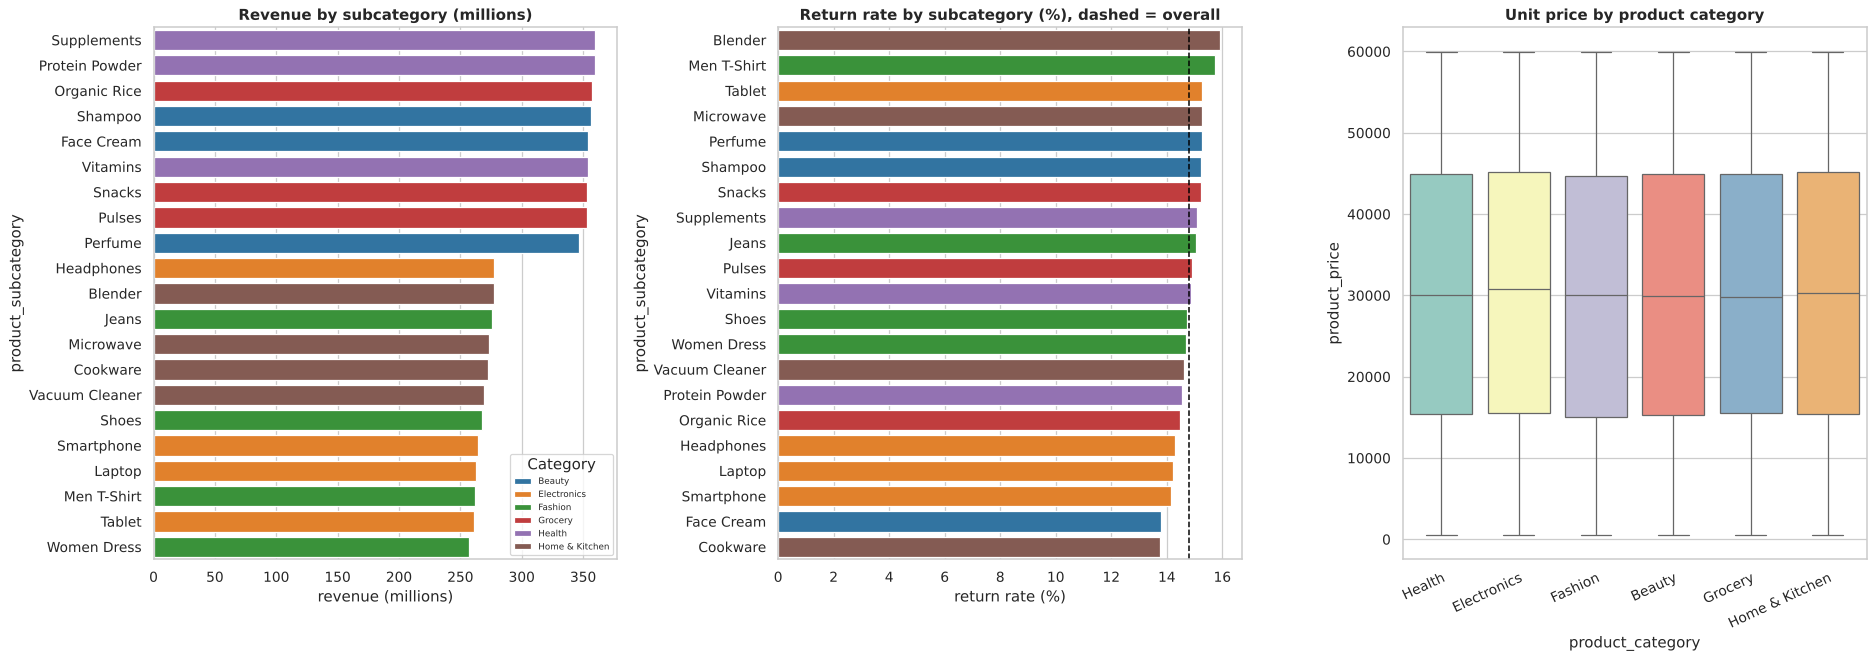

In [51]:
sub = (retail_data.groupby(["product_category", "product_subcategory"])
         .agg(orders=("order_id", "count"), revenue=("final_price", "sum"), avg_unit_price=("product_price", "mean"),
              avg_order_value=("final_price", "mean"), return_rate=("is_return", "mean"))
         .reset_index())
sub["revenue"] = sub["revenue"] / 1e6
sub["return_rate"] *= 100
sub = sub.rename(columns={"revenue": "revenue (millions)", "return_rate": "return rate (%)"})
sub = sub.sort_values("revenue (millions)", ascending=False).reset_index(drop=True)
display(sub)

F, p = stats.f_oneway(*[g["product_price"].to_numpy() for _, g in retail_data.groupby("product_category")])
print(f"Do unit prices differ between product categories?  ANOVA F = {F:.2f}, p = {p:.3f}")
print(f"Average unit price range across the 21 subcategories: {sub['avg_unit_price'].min():,.0f} to {sub['avg_unit_price'].max():,.0f}")

cat_order = sorted(retail_data["product_category"].unique())
cat_pal = dict(zip(cat_order, sns.color_palette("tab10", len(cat_order))))

fig, axes = plt.subplots(1, 3, figsize=(21, 7.5))
sns.barplot(data=sub, x="revenue (millions)", y="product_subcategory", hue="product_category",
            hue_order=cat_order, dodge=False, palette=cat_pal, ax=axes[0])
axes[0].set_title("Revenue by subcategory (millions)")
axes[0].legend(title="Category", fontsize=7, loc="lower right")
sub_rr = sub.sort_values("return rate (%)", ascending=False)
sns.barplot(data=sub_rr, x="return rate (%)", y="product_subcategory", hue="product_category",
            hue_order=cat_order, dodge=False, palette=cat_pal, legend=False, ax=axes[1])
axes[1].axvline(overall_rr, color="black", ls="--", lw=1.2)
axes[1].set_title("Return rate by subcategory (%), dashed = overall")
sns.boxplot(data=retail_data, x="product_category", y="product_price", hue="product_category", palette="Set3",
            legend=False, ax=axes[2])
axes[2].tick_params(axis="x", rotation=25)
plt.setp(axes[2].get_xticklabels(), ha="right", rotation_mode="anchor")
axes[2].set_title("Unit price by product category")
plt.tight_layout()
save_fig("11_products")
plt.show()

**Interpretation**

- **Revenue ranking is a grouping effect, not a popularity effect.** The top subcategories (Supplements 359.9 million, Protein Powder 359.8, Organic Rice 357.4, Shampoo 356.8) all belong to categories with three subcategories; the bottom ones (Women Dress 257.4, Tablet 261.4, Laptop 262.6) belong to categories with four. Each category has about the same size, so each of its three subcategories sells about 5,500 orders, against about 4,200 for each of four. Average order value is almost the same everywhere (63,000 to 65,400).
- **Return rates by subcategory range from 13.75% (Cookware) to 15.91% (Blender)**, which the chi-square test (p = 0.24) shows is random variation.
- **Unit prices do not depend on the product.** The average unit price is between 29,764 and 31,103 for all 21 subcategories, and the category price distributions look identical (ANOVA p = 0.12). In a real shop a laptop would cost far more than pulses or snacks. This is a strong sign that this dataset was generated artificially, so product-level pricing conclusions should not be drawn from it.

### 11.5 Discounts: do they change what customers buy?

**Objective:** compare discount bands on order value, quantity and money given away. *Note:* the first band (0-5%) contains six whole-number discount values while the others contain five, so we compare **averages per order**, not totals.

,orders,avg_quantity,avg_unit_price,avg_gross_order,avg_final_price,avg_discount_given,return rate (%)
discount_band,,,,,,,
0-5%,19364,2.51,"30,152.57","75,535.88","73,663.40","1,872.48",14.82
6-10%,16063,2.50,"30,329.73","75,875.86","69,797.06","6,078.80",14.98
11-15%,16151,2.49,"30,159.93","75,225.37","65,423.21","9,802.15",14.84
16-20%,16133,2.51,"30,277.78","75,962.95","62,281.74","13,681.22",14.39
21-25%,16130,2.49,"30,059.91","75,093.46","57,822.95","17,270.51",14.66
26-30%,16159,2.50,"30,010.58","75,199.65","54,141.87","21,057.78",15.17


Total gross sales : 7,548.4 million
Discounts given   : 1,131.8 million (14.99% of gross)
Net revenue       : 6,416.6 million

Correlation between discount % and quantity bought: r = -0.0036 (p = 0.258)


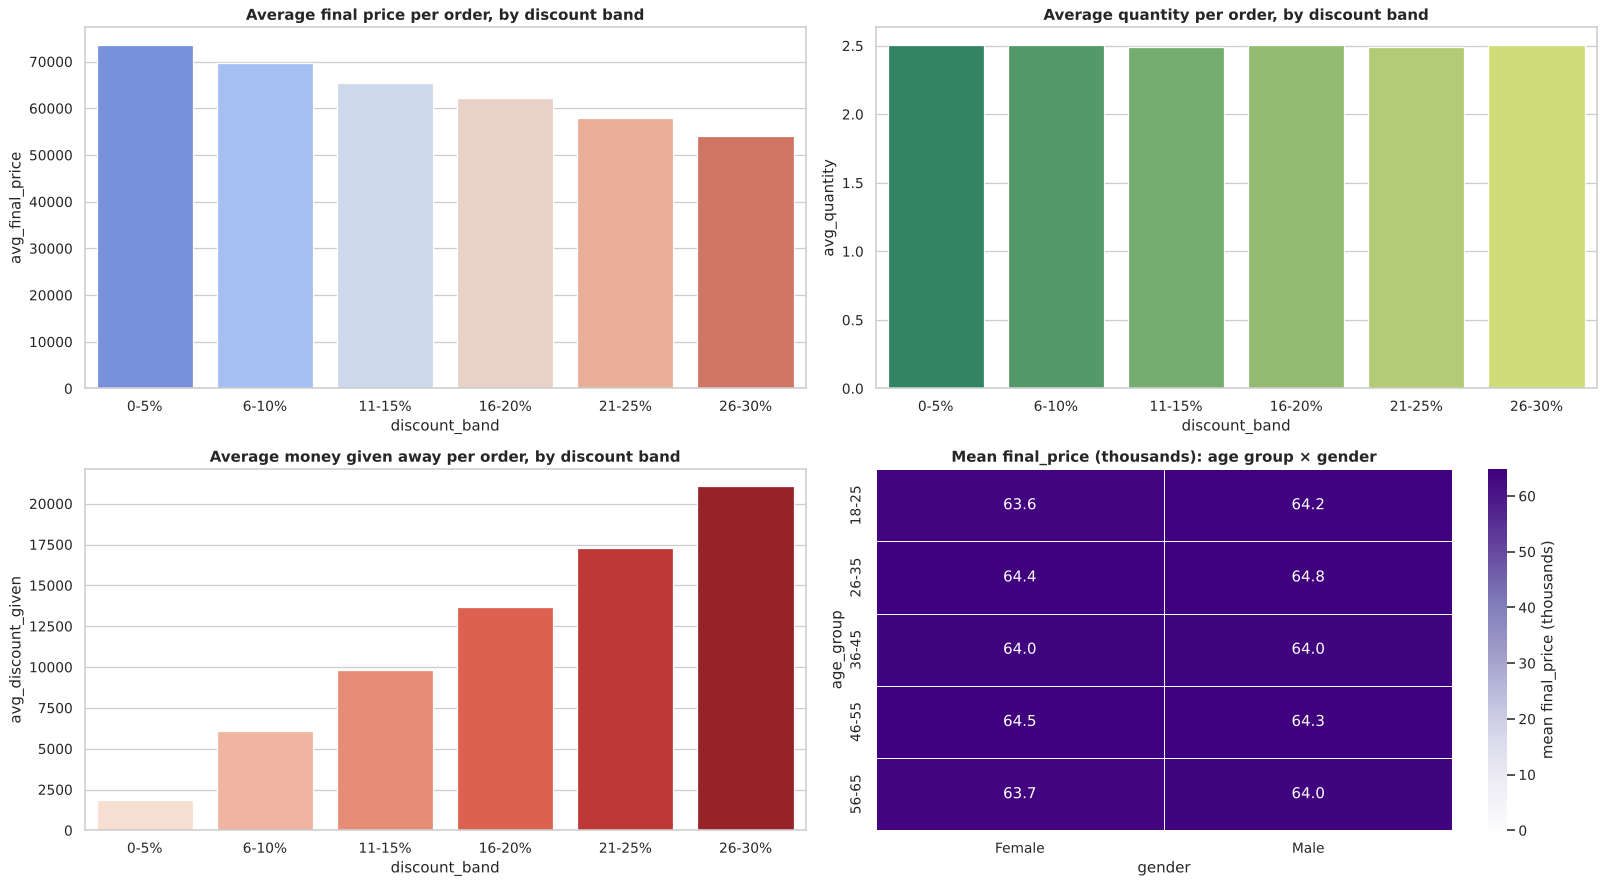

In [52]:
disc = retail_data.groupby("discount_band", observed=True).agg(
    orders=("order_id", "count"), avg_quantity=("quantity", "mean"), avg_unit_price=("product_price", "mean"),
    avg_gross_order=("gross_amount", "mean"), avg_final_price=("final_price", "mean"),
    avg_discount_given=("discount_amount", "mean"), return_rate=("is_return", "mean"))
disc["return_rate"] *= 100
disc = disc.rename(columns={"return_rate": "return rate (%)"})
display(disc)

gross_total, disc_total, net_total = retail_data["gross_amount"].sum(), retail_data["discount_amount"].sum(), retail_data["final_price"].sum()
print(f"Total gross sales : {gross_total / 1e6:,.1f} million")
print(f"Discounts given   : {disc_total / 1e6:,.1f} million ({disc_total / gross_total:.2%} of gross)")
print(f"Net revenue       : {net_total / 1e6:,.1f} million")
r, p = stats.pearsonr(retail_data["discount_percentage"], retail_data["quantity"])
print(f"\nCorrelation between discount % and quantity bought: r = {r:.4f} (p = {p:.3f})")

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
sns.barplot(data=disc.reset_index(), x="discount_band", y="avg_final_price", hue="discount_band",
            palette="coolwarm", legend=False, dodge=False, ax=axes[0, 0])
axes[0, 0].set_title("Average final price per order, by discount band")
sns.barplot(data=disc.reset_index(), x="discount_band", y="avg_quantity", hue="discount_band",
            palette="summer", legend=False, dodge=False, ax=axes[0, 1])
axes[0, 1].set_title("Average quantity per order, by discount band")
sns.barplot(data=disc.reset_index(), x="discount_band", y="avg_discount_given", hue="discount_band",
            palette="Reds", legend=False, dodge=False, ax=axes[1, 0])
axes[1, 0].set_title("Average money given away per order, by discount band")
pv = retail_data.pivot_table(index="age_group", columns="gender", values="final_price", aggfunc="mean", observed=True)
sns.heatmap(pv / 1000, annot=True, fmt=".1f", cmap="Purples", vmin=0, linewidths=0.5,
            cbar_kws={"label": "mean final_price (thousands)"}, ax=axes[1, 1])
axes[1, 1].set_title("Mean final_price (thousands): age group × gender")
plt.tight_layout()
save_fig("11_discounts_and_age_gender")
plt.show()

**Interpretation**

- **Discounts cost 1,131.8 million, which is 14.99% of the 7,548.4 million gross sales** (net revenue 6,416.6 million).
- **Higher discounts did not make customers buy more.** Average quantity is the same in every band (2.49 to 2.51 units), and the correlation between discount % and quantity is −0.0036 (p = 0.26). Average gross order value is also about the same in every band (roughly 75,100 to 76,000).
- **So deeper discounts only reduce what each order brings in.** Average final price falls from 73,663 (0-5%) to 54,142 (26-30%), a 26.5% drop, while the money given away per order rises from 1,872 to 21,058 (more than 11 times). Return rates are unaffected (14.4% to 15.2%).
- The 0-5% band has more orders (19,364 against about 16,100) simply because it covers six discount values, not because small discounts attract more buyers.
- **Caveat:** the data only contains orders that were placed. It cannot show whether discounts attract *additional customers* who would not have bought otherwise, so this result is about order size, not about total sales.
- **Age × gender spending** is flat: all ten cells lie between 63.6 thousand and 64.8 thousand.

## 12. Key Findings, Recommendations and Conclusion

**Objective:** bring the evidence from all sections together into one headline view, then state the findings, what they mean for the business, and the limits of this analysis.

### 12.1 Headline numbers

In [53]:
kpi = pd.Series({
    "Orders analysed": f"{len(retail_data):,}",
    "Unique customers": f"{retail_data['customer_id'].nunique():,}",
    "Period covered": f"{retail_data['order_date'].min().date()} to {retail_data['order_date'].max().date()}",
    "Net revenue (millions)": f"{retail_data['final_price'].sum() / 1e6:,.1f}",
    "Average order value": f"{retail_data['final_price'].mean():,.0f}",
    "Median order value": f"{retail_data['final_price'].median():,.0f}",
    "Discounts given (% of gross sales)": f"{retail_data['discount_amount'].sum() / retail_data['gross_amount'].sum():.2%}",
    "Overall return rate": f"{retail_data['is_return'].mean():.2%}",
    "Orders flagged as final_price outliers": f"{int(retail_data['is_final_price_outlier'].sum()):,} ({retail_data['is_final_price_outlier'].mean():.2%})",
    "final_price skewness / kurtosis": f"{retail_data['final_price'].skew():.2f} / {retail_data['final_price'].kurt():.2f}",
}, name="value").to_frame()
kpi.index.name = "metric"
kpi

,value
metric,
Orders analysed,"100,000"
Unique customers,"100,000"
Period covered,2023-01-01 to 2025-12-30
Net revenue (millions),"6,416.6"
Average order value,"64,166"
Median order value,"49,752"
Discounts given (% of gross sales),14.99%
Overall return rate,14.81%
Orders flagged as final_price outliers,"1,335 (1.33%)"


### 12.2 Files created by this notebook

In [54]:
print("Processed dataset:", os.path.join(DATA_DIR, "Processed_dataset.csv"),
      f"({os.path.getsize(os.path.join(DATA_DIR, 'Processed_dataset.csv')) / 1e6:.1f} MB)")
figs = sorted(os.listdir(FIG_DIR))
print(f"Figures saved in {FIG_DIR}/: {len(figs)} files")
for f in figs:
    print("  -", f)

Processed dataset: data/Processed_dataset.csv (23.3 MB)
Figures saved in outputs/figures/: 27 files
  - 04_boxplots_numeric.png
  - 04_final_price_log_qq.png
  - 04_histograms_numeric.png
  - 05_categorical_bars.png
  - 05_donut_charts.png
  - 05_subcategory_and_segment_mix.png
  - 06_before_after_capping.png
  - 06_final_price_outliers.png
  - 07_correlation_heatmaps.png
  - 07_scatter_relationships.png
  - 08_delivery_days.png
  - 08_distribution_by_group.png
  - 08_mean_by_group.png
  - 09_categorical_heatmaps.png
  - 09_return_rate_by_group.png
  - 09_stacked_return_status.png
  - 10_category_discount_price.png
  - 10_city_category_revenue.png
  - 10_facet_age_gender_segment.png
  - 10_pairplot.png
  - 10_segment_age_spending.png
  - 10_shipping_delivery_return.png
  - 11_discounts_and_age_gender.png
  - 11_geography.png
  - 11_products.png
  - 11_seasonality.png
  - 11_time_trends.png


### 12.3 Key findings

1. **The data is clean and complete.** No missing values, duplicates, spacing or naming problems, and all 10 integrity checks pass. `final_price` equals price × quantity × (1 − discount) in every row.
2. **Most variables are uniformly distributed.** Age, price, quantity, discount and delivery days are flat (skewness ≈ 0, kurtosis ≈ −1.2). Categorical groups are almost perfectly balanced.
3. **Order value is right-skewed** (skewness 0.93, mean 64,166 vs median 49,752) because it is a product of three variables. Its kurtosis (0.17) shows the tail is long but not extreme.
4. **Outliers are genuine.** 1,335 orders (1.33%) exceed the IQR fence, all with quantity 4, high unit prices and low discounts. Capping them changes the mean by only −0.29% and changes no conclusion.
5. **Price, quantity and discount are the only drivers of order value** (correlations +0.73, +0.58 and −0.14), and this is by construction.
6. **Customer segment, gender, age, city, payment method and shipping type make no measurable difference** to order value (all 10 ANOVA tests p > 0.19, η² ≤ 0.0001) or delivery time.
7. **The return rate is 14.81% and does not vary with anything measured.** 13 chi-square tests give p between 0.09 and 0.94, with Cramér's V ≤ 0.016, and none of the numerical correlations with returns is significant.
8. **Express shipping is not faster than Standard** (5.50 vs 5.51 days, p = 0.37).
9. **Discounts cost 14.99% of gross sales without increasing the quantity bought** (r = −0.004). Order value is highest at the lowest discounts.
10. **There is no time trend or meaningful seasonality** (p = 0.45 for trend); revenue is steady across three years and across weekdays.
11. **Product prices do not depend on the product**, and subcategory differences come only from how many subcategories each category has.

### 12.4 Testing common retail hypotheses

The assignment brief suggests several comparisons. Here is what this particular dataset says about each one.

| Idea to check | What the data shows | Supported? |
|---|---|---|
| `product_price` is right-skewed | Skewness 0.00, uniform between 500 and 60,000 | No |
| `final_price` has high kurtosis (extreme values) | Kurtosis 0.17; right-skewed (0.93) but not heavy-tailed | No |
| `discount_percentage` is roughly uniform from 0 to 30% | Flat, mean 15.0%, kurtosis −1.20 | Yes |
| Regular is the largest customer segment | New 33.5%, Regular 33.4%, Premium 33.2% | No |
| Electronics has the most transactions | Health is largest (16.9%); Electronics 16.6% | No |
| Return rate is about 15% | 14.81% | Yes |
| `product_price` has outliers | No outliers by IQR or Z-score | No |
| `final_price` outliers come from high quantity and premium products | All have quantity 4 and high unit price; not tied to one category | Partly |
| Strong correlation of price and quantity with `final_price` | 0.73 and 0.58 (by construction) | Yes |
| Age is only weakly related to spending | r ≈ 0.00 | Yes |
| Longer delivery slightly raises returns | r = 0.0005, p = 0.87 | No |
| Premium customers spend more | +0.4% vs average, not significant | No |
| Electronics has higher return rates | Lowest category return rate (14.47%) | No |
| Express shipping reduces delivery days | 5.50 vs 5.51 days | No |
| Moderate discounts maximise spending | Order value falls as discount rises | No |
| Premium customers aged 30-45 spend the most | Highest cells are Premium 46-55 and 26-35, differences about 3% and not significant | No |
| Standard shipping with long delivery raises return probability | No pattern across the 20 shipping × days cells | No |

### 12.5 Recommendations for the business

- **Review the discount policy.** In this data, discounts did not raise the number of units per order, yet they cost about 15% of gross sales. A controlled test (some customers with discount, some without) would show whether they bring in additional buyers.
- **Do not target by segment, gender, age or city on the basis of this data.** Spending, delivery time and returns are the same across all of them.
- **Investigate the Express service.** If Express is priced higher but delivers in the same time as Standard, customers are not getting what they pay for.
- **Find the cause of returns elsewhere.** About 1 in 7 orders is returned, and none of the available variables explains it. Capture the return reason, product condition and delivery experience.
- **Collect richer data** before making decisions: product cost and margin, repeat purchases, marketing source, return reasons and promised vs actual delivery dates.

### 12.6 Limitations

- **The data looks artificially generated**: five variables are perfectly uniform, independent variables have exactly zero correlation, and prices do not depend on the product. Real retail data is rarely this regular, so these findings describe *this dataset*, and real-world conclusions should be confirmed on real data.
- **One order per customer**, so repeat behaviour and customer lifetime value cannot be studied.
- **No cost or profit information**, so revenue is not the same as profit; the currency is not stated.
- **Observational data**: relationships are associations, not proof of cause. For example, we cannot see what customers would have done without a discount.
- **Many statistical tests were run.** With 100,000 rows even tiny differences can become "significant", so effect sizes (η², Cramér's V) and Bonferroni-adjusted thresholds were reported alongside p-values.

### 12.7 Conclusion

This EDA was carried out in full on 100,000 retail orders: the data was inspected, cleaned and checked, then examined with univariate, bivariate and multivariate methods, outlier detection and capping, correlation and statistical tests, and extra analysis of time, geography, products and discounts. The data is high quality and the main business insight is clear: **order value is determined by price, quantity and discount, and by nothing about the customer, location, payment or shipping method; returns are random relative to every variable available; and discounts reduce revenue per order without raising quantity.** The tidy, flat structure of the data also suggests it was simulated, so the most valuable next step would be to repeat this analysis on real transaction data, where these patterns are likely to be richer. The processed dataset (`data/Processed_dataset.csv`) and all figures (`outputs/figures/`) provide a ready foundation for predictive modelling.